# P5：共同支持、完整 EDA 与开发模型比较

本 Notebook 整理开发阶段 2026 年 4–7 月的既有证据。RQ1 分析同机衔接中的延误净变化；RQ2 评价预测误差。两者的样本、分母和解释目标不同。未归档的文件会明确标出，不用文字代替实际结果。

In [1]:
from pathlib import Path
cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, *cwd.parents] if (p / 'scripts/build_features.py').is_file()), Path('D:\\airline-delay'))
RUN_DIR = ROOT / 'experiments/runs/R0018'
OUTPUT_RUN_DIR = ROOT / 'experiments/runs/R0027'
NOTEBOOK_DIR = ROOT / 'notebooks'
RQ2_EDA_RUN_DIR = ROOT / 'experiments/runs/R0017'
MODEL_RUNS = [ROOT / 'experiments/runs/R0006', ROOT / 'experiments/runs/R0007', ROOT / 'experiments/runs/R0009', ROOT / 'experiments/runs/R0010', ROOT / 'experiments/runs/R0012', ROOT / 'experiments/runs/R0015', ROOT / 'experiments/runs/R0017', ROOT / 'experiments/runs/R0019', ROOT / 'experiments/runs/R0021', ROOT / 'experiments/runs/R0022', ROOT / 'experiments/runs/R0023', ROOT / 'experiments/runs/R0024', ROOT / 'experiments/runs/R0025', ROOT / 'experiments/runs/R0026']
RQ1_RUN_DIR = ROOT / 'experiments/runs/R0018'

In [2]:
from pathlib import Path
import hashlib
import json
import os
from urllib.parse import quote
import pandas as pd
from IPython.display import display, Markdown, Image

def notice(text):
    display(Markdown(text))

def link_file(path):
    relative = os.path.relpath(path, NOTEBOOK_DIR).replace(chr(92), "/")
    return f"[{path.name}]({quote(relative, safe='/.:')})"

def archived_json(name, base=None, show=True, keys=None):
    path = (RUN_DIR if base is None else base) / name
    if not path.is_file():
        notice(f"**未归档：{path.name}**（{path.parent.name}）。")
        return None
    value = json.loads(path.read_text(encoding="utf-8-sig"))
    if show:
        notice(f"**{link_file(path)}**")
        selected = value if keys is None else {key: value.get(key, "未归档该字段") for key in keys}
        notice("```json\n" + json.dumps(selected, ensure_ascii=False, indent=2) + "\n```")
    return value

def archived_table(name, base=None, limit=100, filters=None):
    path = (RUN_DIR if base is None else base) / name
    if not path.is_file():
        notice(f"**未归档：{path.name}**（{path.parent.name}）。")
        return None
    value = pd.read_csv(path, float_precision="round_trip")
    full_n = len(value)
    if filters:
        for column, selected in filters.items():
            if column not in value:
                notice(f"**{path.name} 未归档字段：{column}；未显示该筛选。**")
                return value
            value = value.loc[value[column].eq(selected)]
    notice(f"**{link_file(path)}**：完整表 {full_n:,} 行；当前条件 {len(value):,} 行。")
    shown = value if limit is None else value.head(limit)
    with pd.option_context("display.max_columns", None, "display.max_rows", None if limit is None else max(limit, 10)):
        display(shown)
    if len(shown) < len(value):
        notice(f"上方仅展示前 {len(shown):,} 行，完整结果见该归档 CSV。")
    return value

def archived_image(name, base=None):
    path = (RUN_DIR if base is None else base) / name
    if not path.is_file():
        notice(f"**未归档图：{path.name}**。")
        return False
    notice(f"**{link_file(path)}**")
    display(Image(filename=str(path)))
    return True

def archive_matches(pattern, base=None, kind="table", limit=60):
    base = RUN_DIR if base is None else base
    paths = sorted(base.glob(pattern))
    if not paths:
        notice(f"**未归档：{base.name}/{pattern}**。")
    for path in paths:
        if kind == "json":
            archived_json(str(path.relative_to(base)), base=base)
        elif kind == "image":
            archived_image(str(path.relative_to(base)), base=base)
        else:
            archived_table(str(path.relative_to(base)), base=base, limit=limit)

def single_flight_eda(base):
    notice(f"**完整单航段 EDA 来源：{base.name}**")
    archived_json("tables/eda_complete_summary.json", base=base)
    for name in ["single_flight_delay_stats.csv", "single_flight_operations.csv", "airline_aircraft_coverage.csv",
                 "airline_aircraft_models.csv", "airport_activity.csv", "rq2_weather_missing_coverage.csv"]:
        archived_table("tables/" + name, base=base)
    for name in ["monthly_delay_quantiles.png", "delay_sign_counts.png"]:
        archived_image("figures/" + name, base=base)

def model_structure_explanations(base):
    summaries = sorted(base.glob("**/explain_summary.json"))
    if not summaries:
        notice(f"**未归档结构解释摘要：{base.name}。**")
    for summary_path in summaries:
        source = summary_path.parent
        summary = json.loads(summary_path.read_text(encoding="utf-8-sig"))
        notice(f"### 系数、截距与树路径：{source.name}（{base.name}）")
        coefficients = source / "explain_coefficients.csv"
        has_linear_coefficients = False
        if coefficients.is_file():
            notice(f"**{link_file(coefficients)}**：完整编码系数表可下载。")
            table = pd.read_csv(coefficients, float_precision="round_trip")
            if table.empty:
                notice("系数表为空。树模型没有线性 coef_；应结合下面的已归档树路径阅读，不生成替代系数。")
            elif not {"fold", "encoded_feature", "coefficient"}.issubset(table):
                notice("系数表未归档完整 fold/encoded_feature/coefficient 字段，不能分类展示。")
            else:
                has_linear_coefficients = True
                numeric = table.loc[table.encoded_feature.astype(str).str.startswith("numeric__")]
                categorical = table.loc[~table.encoded_feature.astype(str).str.startswith("numeric__")]
                notice(f"**numeric__ 数值特征系数：{len(numeric):,} 行**（预处理后的编码/缩放单位）。")
                with pd.option_context("display.max_columns", None, "display.max_rows", None):
                    display(numeric)
                notice(f"**其他编码系数：共 {len(categorical):,} 行，按归档行序仅显示前 12 行**。类别系数依赖参考类别，数值系数使用缩放后输入；不能把绝对系数大小直接当重要性排名，也不能解释为因果效应。")
                display(categorical.head(12))
        else:
            notice("**未归档 explain_coefficients.csv**。树模型不适用线性系数；缺失文件本身不证明已完成线性解释。")
        intercepts = archived_table("explain_intercepts.csv", base=source, limit=None)
        if intercepts is not None and intercepts.empty:
            notice("截距表为空；树模型没有线性截距项，不补造截距。")
        paths = sorted(source.glob("explain_*_tree_paths.txt"))
        if not paths:
            if has_linear_coefficients:
                notice("该归档提供线性系数。OLS 没有树分裂路径，树路径不适用。")
            elif summary.get("tree_path_files"):
                notice("**摘要列有树路径文件，但当前解释目录未归档对应 txt；不能展示替代路径。**")
            else:
                notice("未归档树路径；是否适用应结合该模型类型与解释摘要判断。")
        for path in paths:
            lines = path.read_text(encoding="utf-8-sig").splitlines()
            notice(f"**{link_file(path)}**：完整文本 {len(lines):,} 行，下面最多展示前 120 行。DT 为一棵树，RF 为归档的前 3 棵，路径截于深度 3。阈值处于编码/缩放输入空间，不能直接按原始分钟或距离解读。RF 的前 3 棵、深度 3 截断仅为结构示例，不代表整个森林的全局解释。")
            notice("```text\n" + "\n".join(lines[:120]) + "\n```")
            if len(lines) > 120:
                notice("展示文本已截断，完整路径见上方归档下载链接。")

def rq1_reference(base):
    value = archived_json("rq1_standardized/frozen_reference.json", base=base,
                          keys=["schema_version", "frozen_on", "supported", "protocol", "interpretation"])
    if value is None:
        return
    notice("**冻结的机场集合 A 与共同主分层 C**")
    display(pd.DataFrame({"AirportID_in_A": value.get("airport_ids", [])}))
    display(pd.DataFrame({"master_cell_in_C": value.get("master_cells", [])}))
    rows = []
    for threshold, ref in value.get("references", {}).items():
        cells, weights = ref.get("cells", []), ref.get("weights", [])
        counts = ref.get("development_counts", [None] * len(cells))
        if len(cells) != len(weights) or len(cells) != len(counts):
            notice(f"**{threshold} 的冻结 cells/weights/counts 长度不一致，不能构造权重表。**")
            continue
        rows.extend({"threshold": threshold, "cell": cell, "weight_w": weight, "development_count": count}
                    for cell, weight, count in zip(cells, weights, counts))
    notice("**分阈值条件化的固定参考权重 w**")
    display(pd.DataFrame(rows))
    if not value.get("supported", False):
        notice("**该冻结参考未形成足够共同支持；不补零，不强行排序。**")

def model_comparison_runs():
    records, protocols = [], []
    if not MODEL_RUNS:
        notice("**未归档模型运行列表：本次未指定 model_runs，不自动选择其他实验。**")
        return
    for source in MODEL_RUNS:
        notice(f"### 模型归档：{source.name}")
        outer = archived_json("manifest.json", base=source, show=False)
        if outer is not None:
            notice(f"运行状态：**{outer.get('status', '未归档状态')}**。")
            if outer.get("config", {}).get("mode") == "final":
                notice("**这是最终测试归档，不纳入开发模型比较。**")
                continue
        manifest = archived_json("model_manifest.json", base=source, show=False)
        if manifest is None:
            continue
        if manifest.get("development_only") is False:
            notice("**这是最终测试模型，不纳入 P5 开发比较。**")
            continue
        notice("```json\n" + json.dumps({key: manifest.get(key, "未归档该字段") for key in
            ["feature_group", "model_name", "model_type", "models", "features", "categorical_features", "numeric_features",
             "model_params", "effective_preprocessing", "evaluation_rows", "evaluation_ids_sha256", "split_sha256"]}, ensure_ascii=False, indent=2) + "\n```")
        metrics = archived_table("metrics.csv", base=source, filters={"group": "all"}, limit=None)
        if metrics is not None and {"fold", "model", "mae", "rmse", "n"}.issubset(metrics):
            for row in metrics.loc[metrics.fold.eq("overall")].to_dict("records"):
                records.append({"run_id": source.name, "model": row["model"], "n": row["n"], "mae": row["mae"], "rmse": row["rmse"],
                                "feature_group": manifest.get("feature_group"), "model_type": manifest.get("model_type"),
                                "evaluation_ids_sha256": manifest.get("evaluation_ids_sha256"), "split_sha256": manifest.get("split_sha256")})
            protocols.append((manifest.get("evaluation_ids_sha256"), manifest.get("split_sha256")))
        archive_matches("**/comparison_metrics.csv", base=source, limit=None)
        archive_matches("**/comparison.json", base=source, kind="json")
        archive_matches("**/comparison_error_differences.png", base=source, kind="image")
    if records:
        notice("### 所指定开发运行的整体指标")
        combined = pd.DataFrame(records)
        display(combined)
        comparable = bool(protocols) and all(a and b for a, b in protocols) and len(set(protocols)) == 1
        if comparable:
            notice("这些归档声明相同的评估 ID 与切分哈希；完整逐行标签/时间一致性及配对区间仍以各 comparison.json/CSV 为证据。")
            for baseline in ["training_mean", "training_median", "carry_forward"]:
                values = combined.loc[combined.model.eq(baseline), "mae"]
                if len(values) and values.max() - values.min() <= 1e-10:
                    combined[f"delta_MAE_vs_{baseline}"] = combined.mae - values.iloc[0]
                elif len(values):
                    notice(f"**同名 {baseline} 的 MAE 在归档间不一致；不合并为单一参照。**")
            display(combined)
            notice("增量表为候选 MAE 减参照 MAE：正值表示更差；不是配对置信区间，也不是因果效应。")
        else:
            notice("**评估 ID/切分哈希缺失或不一致：上表仅陈列各轮结果，不据此判断模型改善。**")

def rq1_reference_identity(base):
    copied = base / "rq1_standardized/frozen_reference.json"
    if not copied.is_file():
        notice("**未归档最终 RQ1 的冻结参考副本，无法核对参考身份。**")
        return
    observed = hashlib.sha256(copied.read_bytes()).hexdigest()
    complete = archived_json("rq1_complete_summary.json", base=base, show=False)
    expected = None if complete is None else complete.get("frozen_reference_sha256")
    evidence = {"copied_reference_sha256": observed, "complete_summary_sha256": expected,
                "matches_complete_summary": observed == expected if expected else "未归档待比较 SHA"}
    config = archived_json("config.json", base=base, show=False)
    origin = None if config is None else config.get("rq1_frozen_reference_path")
    if origin:
        original = Path(origin)
        original = original if original.is_absolute() else ROOT / original
        if original.is_file():
            original_sha = hashlib.sha256(original.read_bytes()).hexdigest()
            evidence.update(development_reference_path=origin, development_reference_sha256=original_sha,
                            matches_development_reference=original_sha == observed)
        else:
            evidence["development_reference_identity"] = "源参考路径未归档/不可用，未额外声明相同"
    else:
        evidence["development_reference_identity"] = "未归档开发参考源路径"
    display(pd.json_normalize(evidence))
    if evidence.get("matches_complete_summary") is False or evidence.get("matches_development_reference") is False:
        notice("**参考 SHA 不一致：不能据此宣称最终沿用了相同冻结参考。**")

notice(f"**阅读归档：{RUN_DIR.name}**。所有单元仅读取已保存结果，不训练、不重算研究样本或选择参数。")


**阅读归档：R0018**。所有单元仅读取已保存结果，不训练、不重算研究样本或选择参数。

## 1. 运行范围与完整探索性分析

单航段原始有符号延误与衔接预测的非负目标分别展示。月份、机场、星期/小时、航司和机型覆盖用来识别组成与缺失；B43 2024/2025 是参考快照，不是逐预测时刻的历史机队。所有开发目标统计应来自 4–7 月。

**[config.json](../experiments/runs/R0018/config.json)**

```json
{
  "stage": "P5-RQ1-EDA",
  "mode": "development",
  "analysis_only": true,
  "data_id": "D0003",
  "connection_path": "processed/D0003/flight_connections.csv.gz",
  "connections_path": "processed/D0003/flight_connections.csv.gz",
  "data_manifest_path": "processed/D0003/data_manifest.json",
  "flight_path": "processed/flights_clean.csv.gz",
  "flights_path": "processed/flights_clean.csv.gz",
  "parent_run_id": "R0017",
  "change": "Complete registered common-support RQ1 with monthly fixed-reference network and single-flight EDA; no model fitting",
  "threads": 8,
  "feature_group": "G4B",
  "feature_archive_path": "experiments/runs/R0017/data/features.pkl",
  "rq1_protocol_path": "configs/rq1_protocol.json",
  "model_run_ids": [
    "R0006",
    "R0007",
    "R0009",
    "R0010",
    "R0012",
    "R0015",
    "R0017"
  ],
  "test_target_sealed": true
}
```

**完整单航段 EDA 来源：R0018**

**[eda_complete_summary.json](../experiments/runs/R0018/tables/eda_complete_summary.json)**

```json
{
  "mode": "development",
  "scope": "2026-04 through 2026-07 local FlightDate; August excluded before target parsing",
  "flight_source": "processed/flights_clean.csv.gz",
  "connection_source": "processed/D0003/flight_connections.csv.gz",
  "single_flight_summary": {
    "input_rows": 3057590,
    "scoped_flight_rows": 2449201,
    "normal_completed_rows": 2402785,
    "cancelled_rows": 37606,
    "diverted_rows": 8810,
    "unknown_operation_status_rows": 0,
    "distribution_population": "normal completed flights only; cancellations and diversions summarized separately"
  },
  "single_flight_target_fields": [
    "DepDelay",
    "ArrDelay",
    "DepDelayMinutes",
    "ArrDelayMinutes"
  ],
  "aircraft_inventory_years": [
    2024,
    2025
  ],
  "aircraft_unknown_policy": "unknown tail/model retained as an explicit category",
  "airport_activity_note": "Flight movements and eligible connection counts are separate columns; connections use D0003 QA cohort month.",
  "rq2_weather_coverage": "Optional feature archive strata describe RQ2 eligible prediction connections, not single-flight EDA.",
  "tables": [
    "single_flight_delay_stats.csv",
    "single_flight_operations.csv",
    "airline_aircraft_coverage.csv",
    "airline_aircraft_models.csv",
    "airport_activity.csv",
    "rq2_weather_missing_coverage.csv"
  ],
  "figures": [
    "monthly_delay_quantiles.png",
    "delay_sign_counts.png"
  ]
}
```

...

,airport_id,origin_flights,destination_flights,total_flight_movements,accepted_connection_count,main_analysis_eligible_connection_count,rq2_eligible_connection_count,airport_code,latitude,longitude
0,10135,1267,1268,2535,1141,1141,1141,ABE,40.652363,-75.440406
1,10136,1015,1016,2031,944,944,944,ABI,32.411333,-99.681889
2,10140,8510,8514,17024,8233,8233,8233,ABQ,35.038932,-106.608262
3,10141,244,244,488,227,227,227,ABR,45.446798,-98.422441
4,10154,961,961,1922,852,852,852,ACK,41.253299,-70.060511
5,10155,364,364,728,335,335,335,ACT,31.612194,-97.230306
6,10157,870,870,1740,811,811,811,ACV,40.977826,-124.108469
7,10158,387,388,775,362,362,362,ACY,39.457576,-74.577155
8,10165,35,35,70,34,34,34,ADK,51.883583,-176.642482
9,10170,323,323,646,317,317,317,ADQ,57.749794,-152.493944


上方仅展示前 100 行，完整结果见该归档 CSV。

**[rq2_weather_missing_coverage.csv](../experiments/runs/R0018/tables/rq2_weather_missing_coverage.csv)**：完整表 1 行；当前条件 1 行。

,analysis_population,metar_missing,taf_missing,connections,target_n,target_missing,target_mean_minutes,target_q50_minutes,target_q90_minutes,target_q99_minutes,target_max_minutes
0,"RQ2 prediction connections, not individual fli...",NaN,NaN,2261775,2261775,0,15.440298,0.0,44.0,187.0,3392.0


**[monthly_delay_quantiles.png](../experiments/runs/R0018/figures/monthly_delay_quantiles.png)**

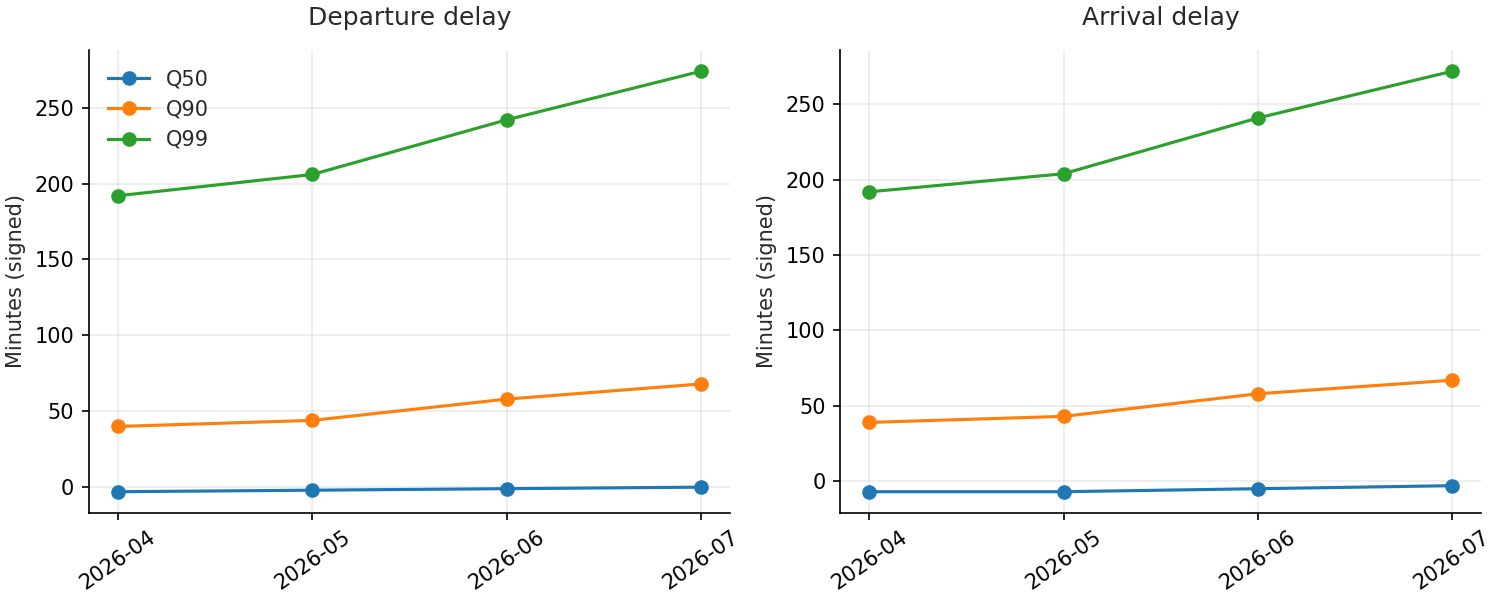

**[delay_sign_counts.png](../experiments/runs/R0018/figures/delay_sign_counts.png)**

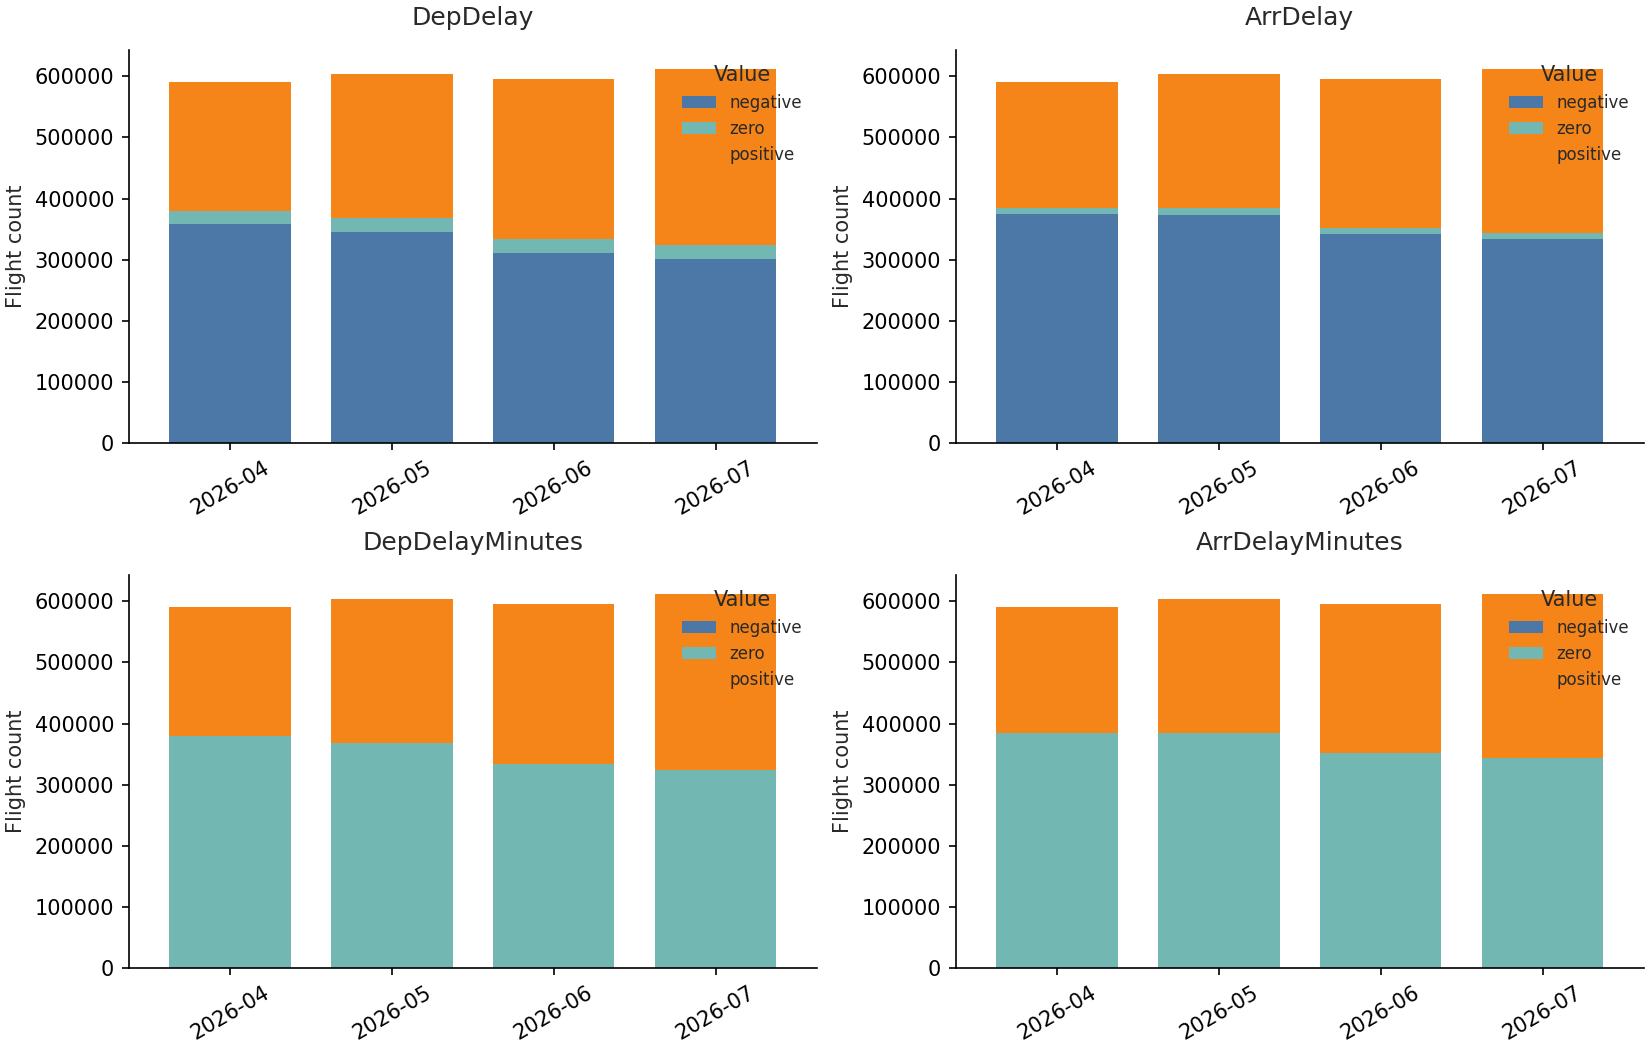

**衔接预测 RQ2 EDA 来源：R0017**

**[eda_summary.json](../experiments/runs/R0017/eda_summary.json)**

```json
{
  "scope": "2026-04-01 <= prediction_time < 2026-08-01 UTC",
  "population": "eligible RQ2 connections",
  "n": 2261775,
  "airport_n": 355,
  "route_n": 6591,
  "overnight_n": 437491,
  "main_target": "nonnegative downstream departure delay",
  "feature_audit": {
    "development_only": true,
    "counts": {
      "input_connections": 2821852,
      "outside_prediction_utc_scope": 560077,
      "scoped_connections": 2261775,
      "missing_or_nonfinite_target": 0,
      "negative_target": 0,
      "missing_label_time": 0,
      "prediction_not_before_departure": 0,
      "missing_or_invalid_upstream_delay": 0,
      "eligible_connections": 2261775
    },
    "categorical_features": [
      "airport_id",
      "route",
      "downstream_airline",
      "aircraft_family"
    ],
    "numeric_features": [
      "downstream_distance",
      "downstream_crs_elapsed_time",
      "downstream_day_of_week",
      "downstream_sched_hour",
      "scheduled_turnaround_minutes",
      "upstream_arr_delay_minutes",
      "tail_completed_24h_n",
      "tail_completed_24h_arr_delay_mean",
      "history_window_incomplete",
      "airport_departures_60m_n",
      "airport_departures_60m_delay_mean",
      "airport_planned_departures_next60m_n",
      "airport_planned_arrivals_next60m_n",
      "airport_history_window_incomplete",
      "metar_wind_knots",
      "metar_gust_knots",
      "metar_visibility_miles",
      "metar_ceiling_ft",
      "metar_precip_amount_in",
      "metar_precip_flag",
      "metar_rain_flag",
      "metar_snow_flag",
      "metar_thunder_flag",
      "metar_age_minutes",
      "metar_missing",
      "metar_sky_reported",
      "metar_ceiling_reported",
      "metar_weather_codes_reported",
      "taf_bulletin_age_minutes",
      "taf_lead_minutes",
      "taf_missing",
      "taf_prevailing_wind_knots",
      "taf_prevailing_gust_knots",
      "taf_prevailing_visibility_miles",
      "taf_prevailing_ceiling_ft",
      "taf_prevailing_precip_flag",
      "taf_prevailing_rain_flag",
      "taf_prevailing_snow_flag",
      "taf_prevailing_thunder_flag",
      "taf_prevailing_segment_count",
      "taf_prevailing_missing",
      "taf_tempo_wind_knots",
      "taf_tempo_gust_knots",
      "taf_tempo_visibility_miles",
      "taf_tempo_ceiling_ft",
      "taf_tempo_precip_flag",
      "taf_tempo_rain_flag",
      "taf_tempo_snow_flag",
      "taf_tempo_thunder_flag",
      "taf_tempo_segment_count",
      "taf_tempo_missing",
      "taf_probability_wind_knots",
      "taf_probability_gust_knots",
      "taf_probability_visibility_miles",
      "taf_probability_ceiling_ft",
      "taf_probability_precip_flag",
      "taf_probability_rain_flag",
      "taf_probability_snow_flag",
      "taf_probability_thunder_flag",
      "taf_probability_segment_count",
      "taf_probability_missing"
    ],
    "outcome_rule": "finite target >= 0 and prediction_time < label_time",
    "feature_group": "G4B",
    "features": [
      "airport_id",
      "route",
      "downstream_airline",
      "aircraft_family",
      "downstream_distance",
      "downstream_crs_elapsed_time",
      "downstream_day_of_week",
      "downstream_sched_hour",
      "scheduled_turnaround_minutes",
      "upstream_arr_delay_minutes",
      "tail_completed_24h_n",
      "tail_completed_24h_arr_delay_mean",
      "history_window_incomplete",
      "airport_departures_60m_n",
      "airport_departures_60m_delay_mean",
      "airport_planned_departures_next60m_n",
      "airport_planned_arrivals_next60m_n",
      "airport_history_window_incomplete",
      "metar_wind_knots",
      "metar_gust_knots",
      "metar_visibility_miles",
      "metar_ceiling_ft",
      "metar_precip_amount_in",
      "metar_precip_flag",
      "metar_rain_flag",
      "metar_snow_flag",
      "metar_thunder_flag",
      "metar_age_minutes",
      "metar_missing",
      "metar_sky_reported",
      "metar_ceiling_reported",
      "metar_weather_codes_reported",
      "taf_bulletin_age_minutes",
      "taf_lead_minutes",
      "taf_missing",
      "taf_prevailing_wind_knots",
      "taf_prevailing_gust_knots",
      "taf_prevailing_visibility_miles",
      "taf_prevailing_ceiling_ft",
      "taf_prevailing_precip_flag",
      "taf_prevailing_rain_flag",
      "taf_prevailing_snow_flag",
      "taf_prevailing_thunder_flag",
      "taf_prevailing_segment_count",
      "taf_prevailing_missing",
      "taf_tempo_wind_knots",
      "taf_tempo_gust_knots",
      "taf_tempo_visibility_miles",
      "taf_tempo_ceiling_ft",
      "taf_tempo_precip_flag",
      "taf_tempo_rain_flag",
      "taf_tempo_snow_flag",
      "taf_tempo_thunder_flag",
      "taf_tempo_segment_count",
      "taf_tempo_missing",
      "taf_probability_wind_knots",
      "taf_probability_gust_knots",
      "taf_probability_visibility_miles",
      "taf_probability_ceiling_ft",
      "taf_probability_precip_flag",
      "taf_probability_rain_flag",
      "taf_probability_snow_flag",
      "taf_probability_thunder_flag",
      "taf_probability_segment_count",
      "taf_probability_missing"
    ]
  },
  "heatmap_note": "Delta is downstream departure delay minus upstream arrival delay; no causal interpretation."
}
```

**[eda_monthly_target.csv](../experiments/runs/R0017/tables/eda_monthly_target.csv)**：完整表 4 行；当前条件 4 行。

,month_utc,n,mean,median,p10,p90,p95,p99,maximum,target_ge15_share,target_ge60_share
0,2026-04,554684,11.815758,0.0,0.0,34.0,61.0,154.0,3140.0,0.186331,0.051498
1,2026-05,574571,13.209259,0.0,0.0,38.0,67.0,163.0,2939.0,0.207785,0.058941
2,2026-06,561972,16.995806,0.0,0.0,49.0,84.0,198.0,2759.0,0.247952,0.080344
3,2026-07,570548,19.678702,0.0,0.0,56.0,96.0,221.0,3392.0,0.272265,0.094178


...

,route,n,months
0,14771->12892,3997,4
1,12892->14771,3804,4
2,12953->13930,3454,4
3,13930->12953,3313,4
4,12892->12478,3175,4
5,13830->12173,3085,4
6,12173->13830,2989,4
7,10721->11278,2814,4
8,11278->10721,2813,4
9,14107->11292,2782,4


上方仅展示前 100 行，完整结果见该归档 CSV。

**[eda_support_airline.csv](../experiments/runs/R0017/tables/eda_support_airline.csv)**：完整表 13 行；当前条件 13 行。

,downstream_airline,n,months
0,WN,462819,4
1,DL,341872,4
2,AA,309521,4
3,OO,278994,4
4,UA,265099,4
5,YX,113460,4
6,AS,111690,4
7,MQ,106705,4
8,B6,74365,4
9,OH,73415,4


**[eda_target_distribution.png](../experiments/runs/R0017/figures/eda_target_distribution.png)**

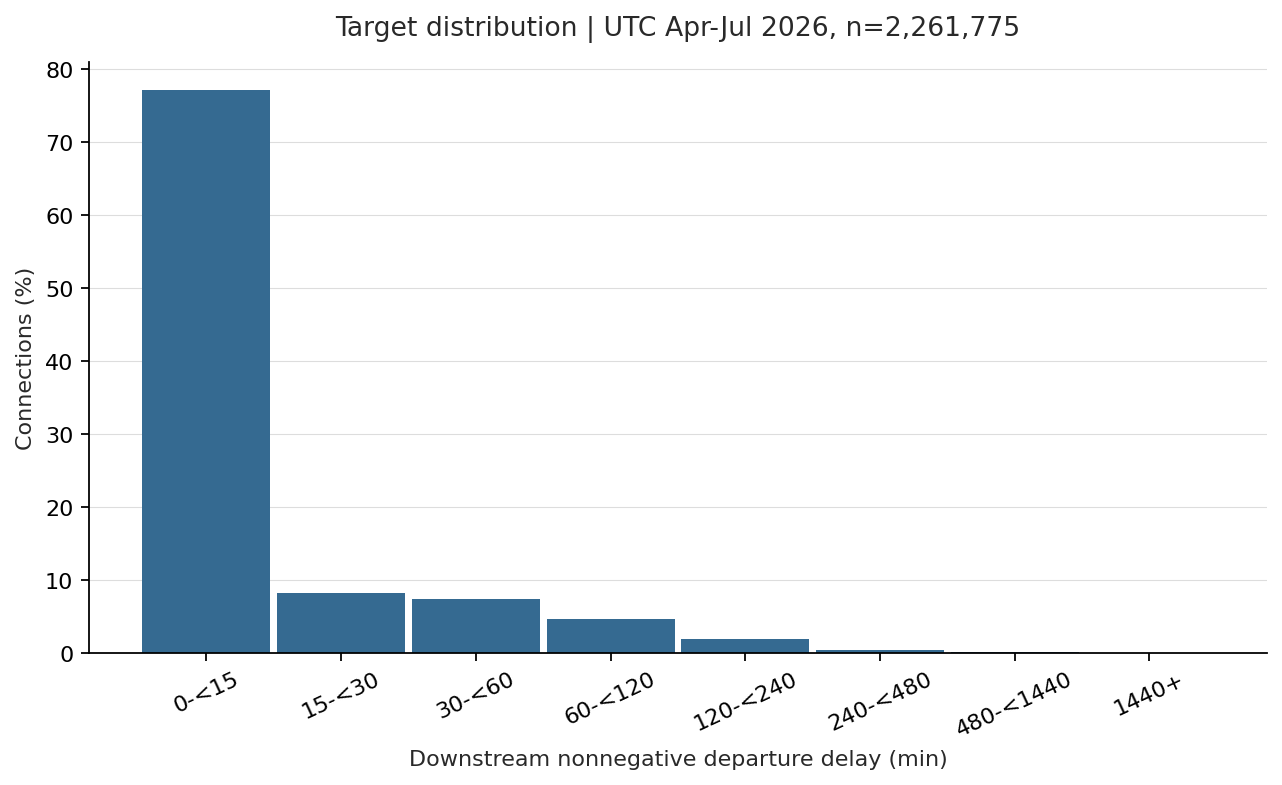

**[eda_monthly_target.png](../experiments/runs/R0017/figures/eda_monthly_target.png)**

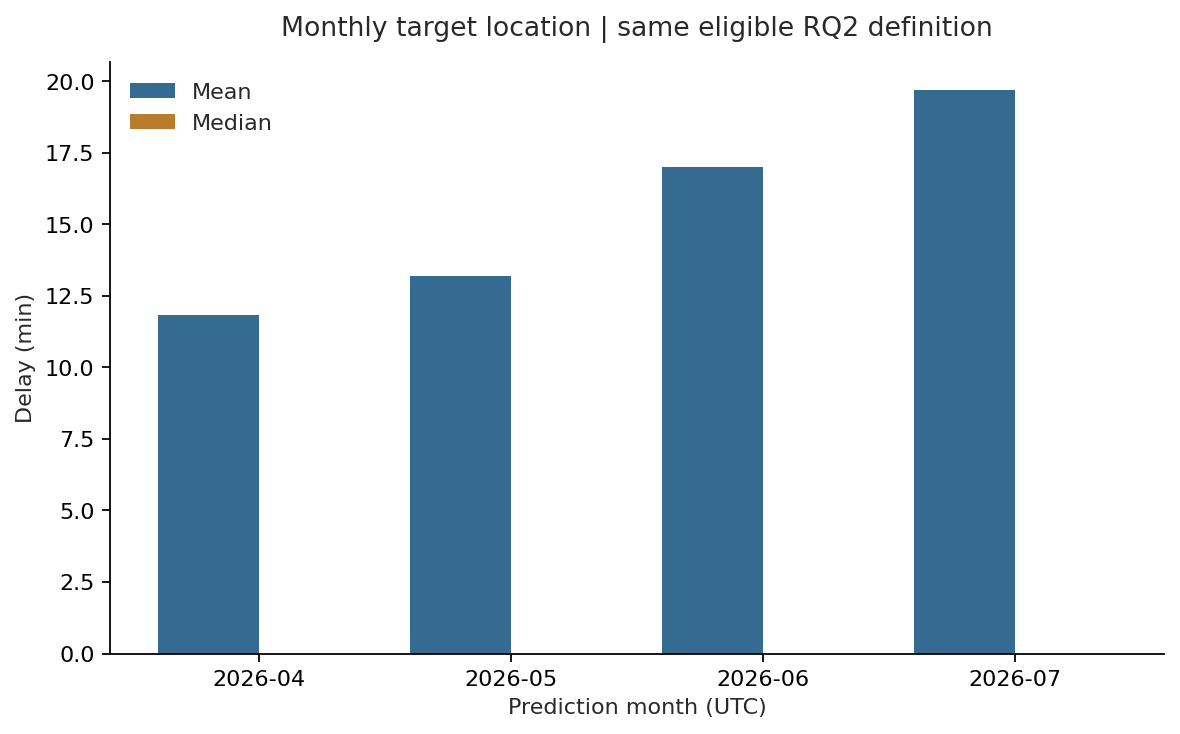

**[eda_airport_support.png](../experiments/runs/R0017/figures/eda_airport_support.png)**

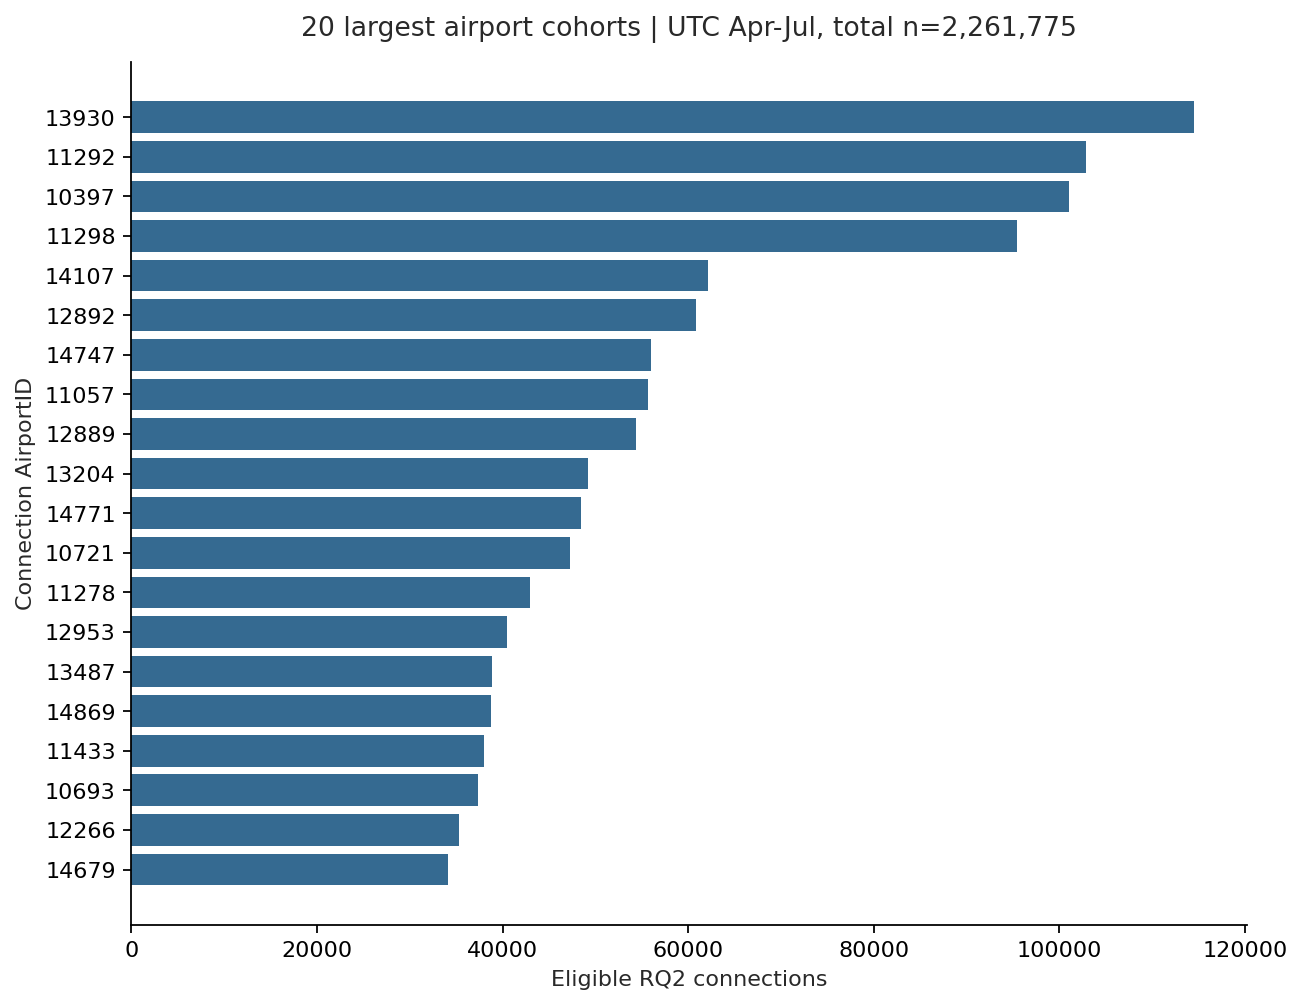

**[eda_turnaround_count.png](../experiments/runs/R0017/figures/eda_turnaround_count.png)**

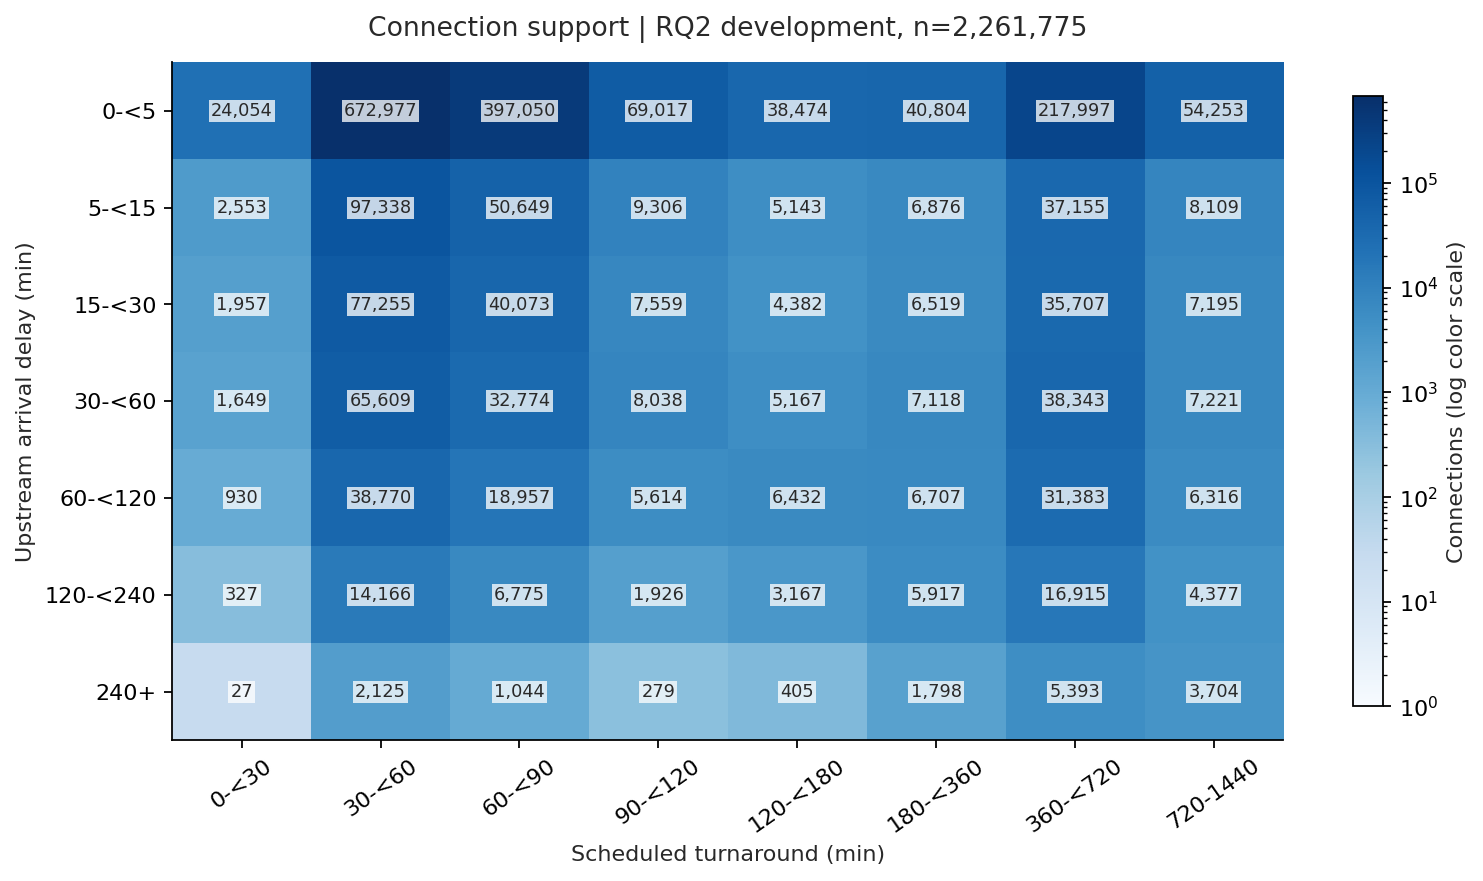

**[eda_turnaround_mean_delta.png](../experiments/runs/R0017/figures/eda_turnaround_mean_delta.png)**

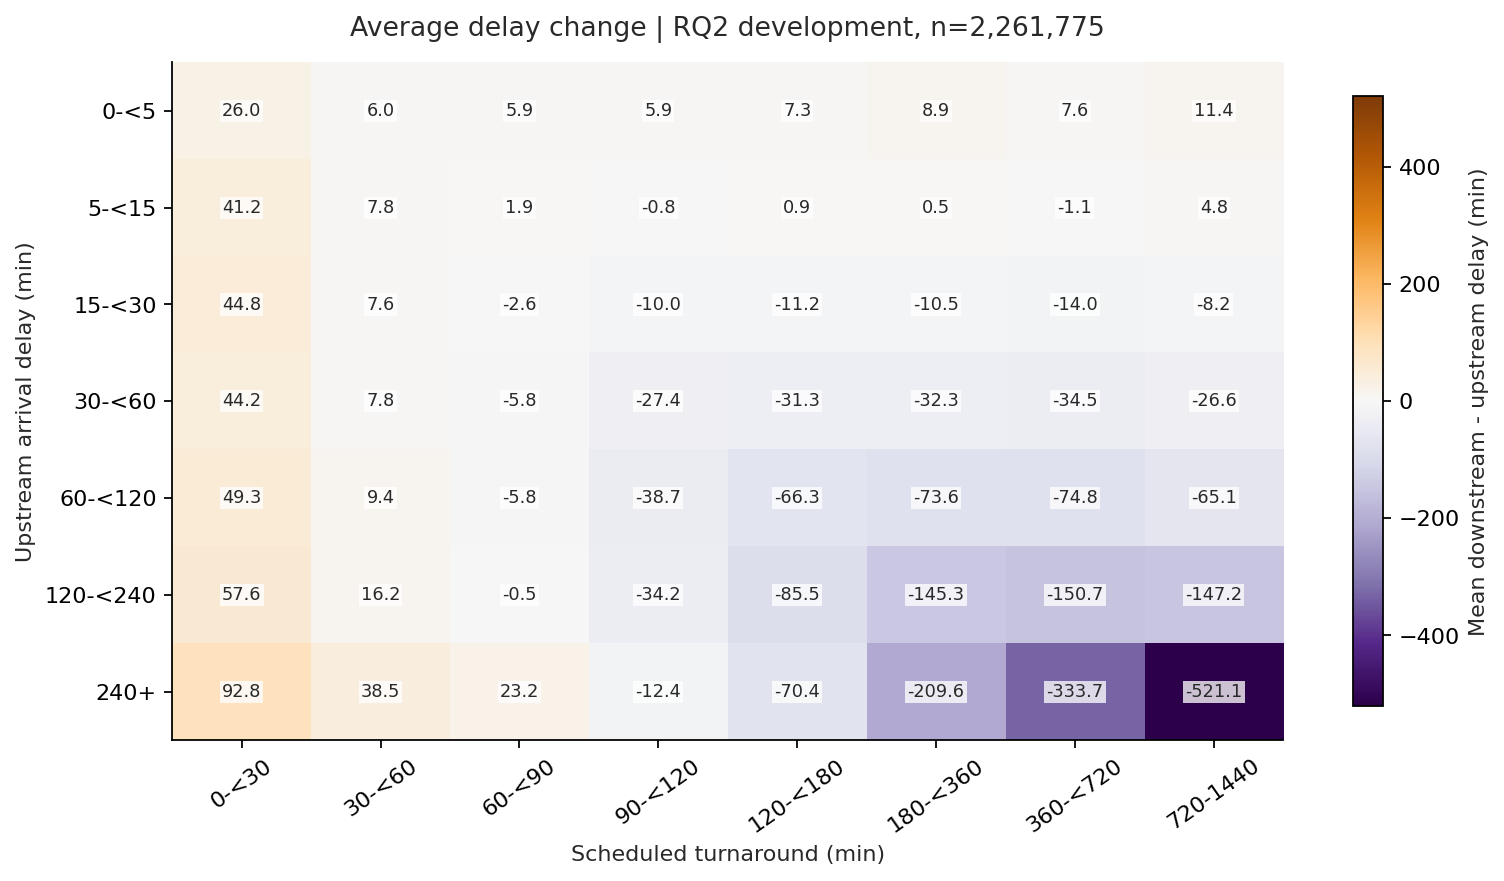

In [3]:
archived_json("config.json")
single_flight_eda(RUN_DIR)
notice(f"**衔接预测 RQ2 EDA 来源：{RQ2_EDA_RUN_DIR.name}**")
archived_json("eda_summary.json", base=RQ2_EDA_RUN_DIR)
for name in ["eda_monthly_target.csv", "eda_target_bins.csv", "eda_feature_missing.csv",
             "eda_support_airport.csv", "eda_support_route.csv", "eda_support_airline.csv"]:
    archived_table("tables/" + name, base=RQ2_EDA_RUN_DIR)
for name in ["eda_target_distribution.png",
             "eda_monthly_target.png", "eda_airport_support.png", "eda_turnaround_count.png", "eda_turnaround_mean_delta.png"]:
    archived_image("figures/" + name, base=RQ2_EDA_RUN_DIR)

## 2. RQ1 定义与原始累计量

主分析为上游非负到达延误至少 15 分钟、计划非隔夜的有效同机衔接。\(\Delta=D^{dep}_{down}-D^{arr}_{up}\)。每次平均净变化以分钟/衔接计；\(S_+=\sum\max(\Delta,0)\)、\(S_-=\sum\max(-\Delta,0)\)、\(S_{net}=S_+-S_-\) 为样本累计分钟，受流量影响。负 Δ 不保证下游准点，更不证明机场造成了恢复。

**[rq1_complete_summary.json](../experiments/runs/R0018/rq1_complete_summary.json)**

```json
{
  "development": true,
  "raw": {
    "development_only": true,
    "connection_path": "processed/D0003/flight_connections.csv.gz",
    "sample_rule": "accepted, upstream delay >=15 min, non-overnight; ground >=0 allowed",
    "counts": {
      "input_accepted_connections": 2821852,
      "outside_prediction_utc_scope": 560077,
      "scoped_accepted_connections": 2261775,
      "invalid_delay": 0,
      "invalid_actual_ground": 0,
      "upstream_below_15": 1731755,
      "scheduled_overnight": 150345,
      "main_connections": 379675,
      "main_ground_zero_n": 0
    },
    "airports": 349,
    "mean_delta": -7.4662487653914535,
    "s_plus": 4071355.0,
    "s_minus": 6906103.0,
    "s_net": -2834748.0,
    "delta_identity_checked": true,
    "standardized": false,
    "uncertainty_intervals": false,
    "interpretation": "Descriptive raw differences; airport composition is unadjusted and results are not causal."
  },
  "standardized": {
    "development": true,
    "frozen_reference_reused": false,
    "period": [
      "2026-04-01 00:00:00+00:00",
      "2026-08-01 00:00:00+00:00"
    ],
    "selected_airports": 25,
    "supported_reference": true,
    "bootstrap": {
      "unit": "common UTC prediction-date moving blocks",
      "block_days": 7,
      "replicates": 1000,
      "seed": 42,
      "interval": "95% percentile",
      "min_valid_replicates": 950
    },
    "calendar_days": 122,
    "sample_rule": "accepted, nonovernight, upstream positive; threshold-specific subsets",
    "uncertainty": "Common calendar moving blocks; fixed airports/cells/weights, no reselection per replicate; percentile intervals are not multiplicity adjusted.",
    "units": {
      "standardized_mean": "minutes per connection",
      "s_plus_s_minus_s_net": "sample cumulative minutes"
    }
  },
  "monthly": [
    {
      "development": true,
      "frozen_reference_reused": true,
      "period": [
        "2026-04-01 00:00:00+00:00",
        "2026-05-01 00:00:00+00:00"
      ],
      "selected_airports": 25,
      "supported_reference": true,
      "bootstrap": {
        "unit": "common UTC prediction-date moving blocks",
        "block_days": 7,
        "replicates": 1000,
        "seed": 42,
        "interval": "95% percentile",
        "min_valid_replicates": 950
      },
      "calendar_days": 30,
      "sample_rule": "accepted, nonovernight, upstream positive; threshold-specific subsets",
      "uncertainty": "Common calendar moving blocks; fixed airports/cells/weights, no reselection per replicate; percentile intervals are not multiplicity adjusted.",
      "units": {
        "standardized_mean": "minutes per connection",
        "s_plus_s_minus_s_net": "sample cumulative minutes"
      }
    },
    {
      "development": true,
      "frozen_reference_reused": true,
      "period": [
        "2026-05-01 00:00:00+00:00",
        "2026-06-01 00:00:00+00:00"
      ],
      "selected_airports": 25,
      "supported_reference": true,
      "bootstrap": {
        "unit": "common UTC prediction-date moving blocks",
        "block_days": 7,
        "replicates": 1000,
        "seed": 42,
        "interval": "95% percentile",
        "min_valid_replicates": 950
      },
      "calendar_days": 31,
      "sample_rule": "accepted, nonovernight, upstream positive; threshold-specific subsets",
      "uncertainty": "Common calendar moving blocks; fixed airports/cells/weights, no reselection per replicate; percentile intervals are not multiplicity adjusted.",
      "units": {
        "standardized_mean": "minutes per connection",
        "s_plus_s_minus_s_net": "sample cumulative minutes"
      }
    },
    {
      "development": true,
      "frozen_reference_reused": true,
      "period": [
        "2026-06-01 00:00:00+00:00",
        "2026-07-01 00:00:00+00:00"
      ],
      "selected_airports": 25,
      "supported_reference": true,
      "bootstrap": {
        "unit": "common UTC prediction-date moving blocks",
        "block_days": 7,
        "replicates": 1000,
        "seed": 42,
        "interval": "95% percentile",
        "min_valid_replicates": 950
      },
      "calendar_days": 30,
      "sample_rule": "accepted, nonovernight, upstream positive; threshold-specific subsets",
      "uncertainty": "Common calendar moving blocks; fixed airports/cells/weights, no reselection per replicate; percentile intervals are not multiplicity adjusted.",
      "units": {
        "standardized_mean": "minutes per connection",
        "s_plus_s_minus_s_net": "sample cumulative minutes"
      }
    },
    {
      "development": true,
      "frozen_reference_reused": true,
      "period": [
        "2026-07-01 00:00:00+00:00",
        "2026-08-01 00:00:00+00:00"
      ],
      "selected_airports": 25,
      "supported_reference": true,
      "bootstrap": {
        "unit": "common UTC prediction-date moving blocks",
        "block_days": 7,
        "replicates": 1000,
        "seed": 42,
        "interval": "95% percentile",
        "min_valid_replicates": 950
      },
      "calendar_days": 31,
      "sample_rule": "accepted, nonovernight, upstream positive; threshold-specific subsets",
      "uncertainty": "Common calendar moving blocks; fixed airports/cells/weights, no reselection per replicate; percentile intervals are not multiplicity adjusted.",
      "units": {
        "standardized_mean": "minutes per connection",
        "s_plus_s_minus_s_net": "sample cumulative minutes"
      }
    }
  ],
  "frozen_reference_sha256": "559ddb58275e5def26bd62cda09536c5b16700f9771c366fc85a6eafb1690547",
  "network": {
    "nodes": 355,
    "edges": 6600,
    "bts_flights": 2445202,
    "valid_connections": 2261775,
    "display_top_routes": 100,
    "edge_window": "scheduled departure UTC",
    "node_window": "upstream actual arrival UTC",
    "unsupported_color": "gray",
    "full_coordinate_tables": "rq1_standardized/network_nodes.csv; network_edges.csv"
  }
}
```

**[rq1_summary.json](../experiments/runs/R0018/rq1_summary.json)**

```json
{
  "development_only": true,
  "connection_path": "processed/D0003/flight_connections.csv.gz",
  "sample_rule": "accepted, upstream delay >=15 min, non-overnight; ground >=0 allowed",
  "counts": {
    "input_accepted_connections": 2821852,
    "outside_prediction_utc_scope": 560077,
    "scoped_accepted_connections": 2261775,
    "invalid_delay": 0,
    "invalid_actual_ground": 0,
    "upstream_below_15": 1731755,
    "scheduled_overnight": 150345,
    "main_connections": 379675,
    "main_ground_zero_n": 0
  },
  "airports": 349,
  "mean_delta": -7.4662487653914535,
  "s_plus": 4071355.0,
  "s_minus": 6906103.0,
  "s_net": -2834748.0,
  "delta_identity_checked": true,
  "standardized": false,
  "uncertainty_intervals": false,
  "interpretation": "Descriptive raw differences; airport composition is unadjusted and results are not causal."
}
```

**[rq1_airport_raw.csv](../experiments/runs/R0018/tables/rq1_airport_raw.csv)**：完整表 349 行；当前条件 349 行。

...

上方仅展示前 100 行，完整结果见该归档 CSV。

**[rq1_airport_monthly.csv](../experiments/runs/R0018/tables/rq1_airport_monthly.csv)**：完整表 1,356 行；当前条件 1,356 行。

,month_utc,airport_id,airport_code,n,mean_delta,median_delta,p10_delta,p90_delta,reduction_share,amplification_share,unchanged_share,s_plus,s_minus,s_net,upstream_mean,downstream_mean,scheduled_turnaround_mean,supported_months
0,2026-04,10135,ABE,36,19.972222,-3.5,-23.0,13.5,0.638889,0.333333,0.027778,1137.0,418.0,719.0,54.583333,74.555556,102.805556,1
1,2026-04,10136,ABI,24,-2.916667,-4.5,-33.8,36.5,0.708333,0.291667,0.000000,226.0,296.0,-70.0,71.250000,68.333333,45.875000,1
2,2026-04,10140,ABQ,244,1.872951,-3.0,-23.0,15.0,0.590164,0.352459,0.057377,2576.0,2119.0,457.0,45.536885,47.409836,66.717213,1
3,2026-04,10141,ABR,4,-9.250000,-9.5,-14.7,-3.6,1.000000,0.000000,0.000000,0.0,37.0,-37.0,72.000000,62.750000,36.000000,1
4,2026-04,10155,ACT,5,-8.000000,-7.0,-12.2,-4.8,1.000000,0.000000,0.000000,0.0,40.0,-40.0,63.800000,55.800000,30.000000,1
5,2026-04,10157,ACV,32,-0.156250,-2.0,-18.8,19.7,0.656250,0.343750,0.000000,185.0,190.0,-5.0,61.843750,61.687500,42.875000,1
6,2026-04,10158,ACY,41,-23.487805,-11.0,-86.0,9.0,0.780488,0.219512,0.000000,109.0,1072.0,-963.0,62.682927,39.195122,160.365854,1
7,2026-04,10165,ADK,2,7.000000,7.0,0.6,13.4,0.500000,0.500000,0.000000,15.0,1.0,14.0,79.500000,86.500000,56.000000,1
8,2026-04,10170,ADQ,3,-1.666667,-1.0,-5.8,2.2,0.666667,0.333333,0.000000,3.0,8.0,-5.0,35.333333,33.666667,52.000000,1
9,2026-04,10185,AEX,5,11.400000,2.0,-2.6,35.4,0.400000,0.600000,0.000000,62.0,5.0,57.0,61.400000,72.800000,30.000000,1


上方仅展示前 100 行，完整结果见该归档 CSV。

**[rq1_raw_airport_mean.png](../experiments/runs/R0018/figures/rq1_raw_airport_mean.png)**

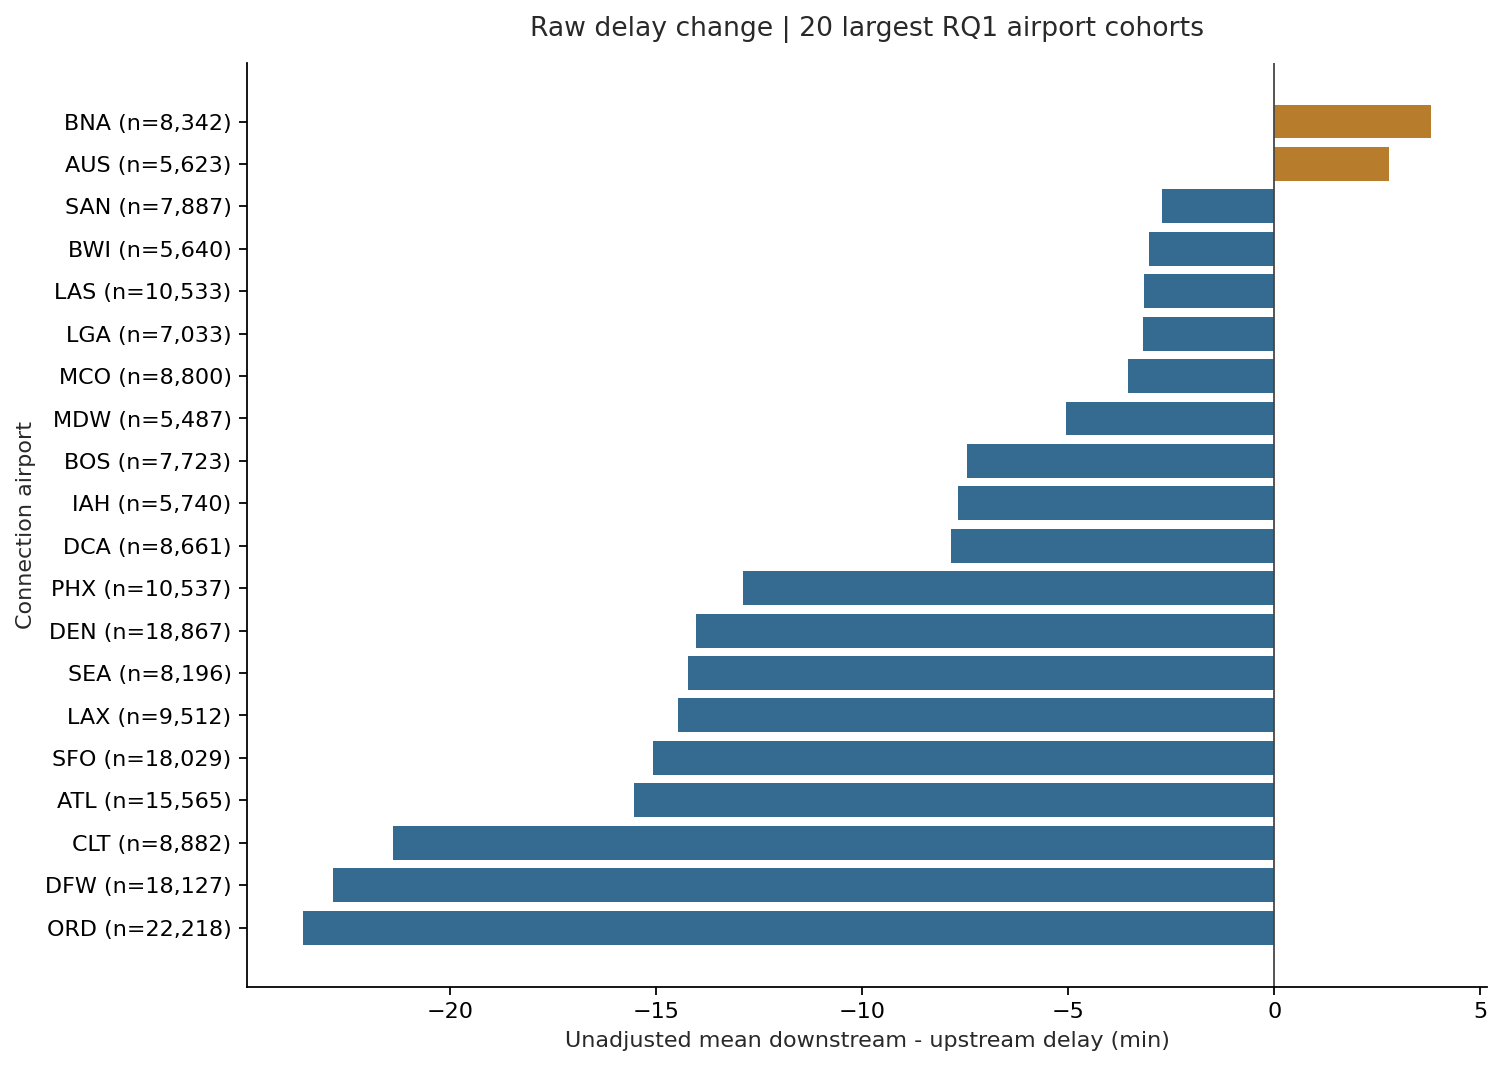

**[rq1_cumulative_delay.png](../experiments/runs/R0018/figures/rq1_cumulative_delay.png)**

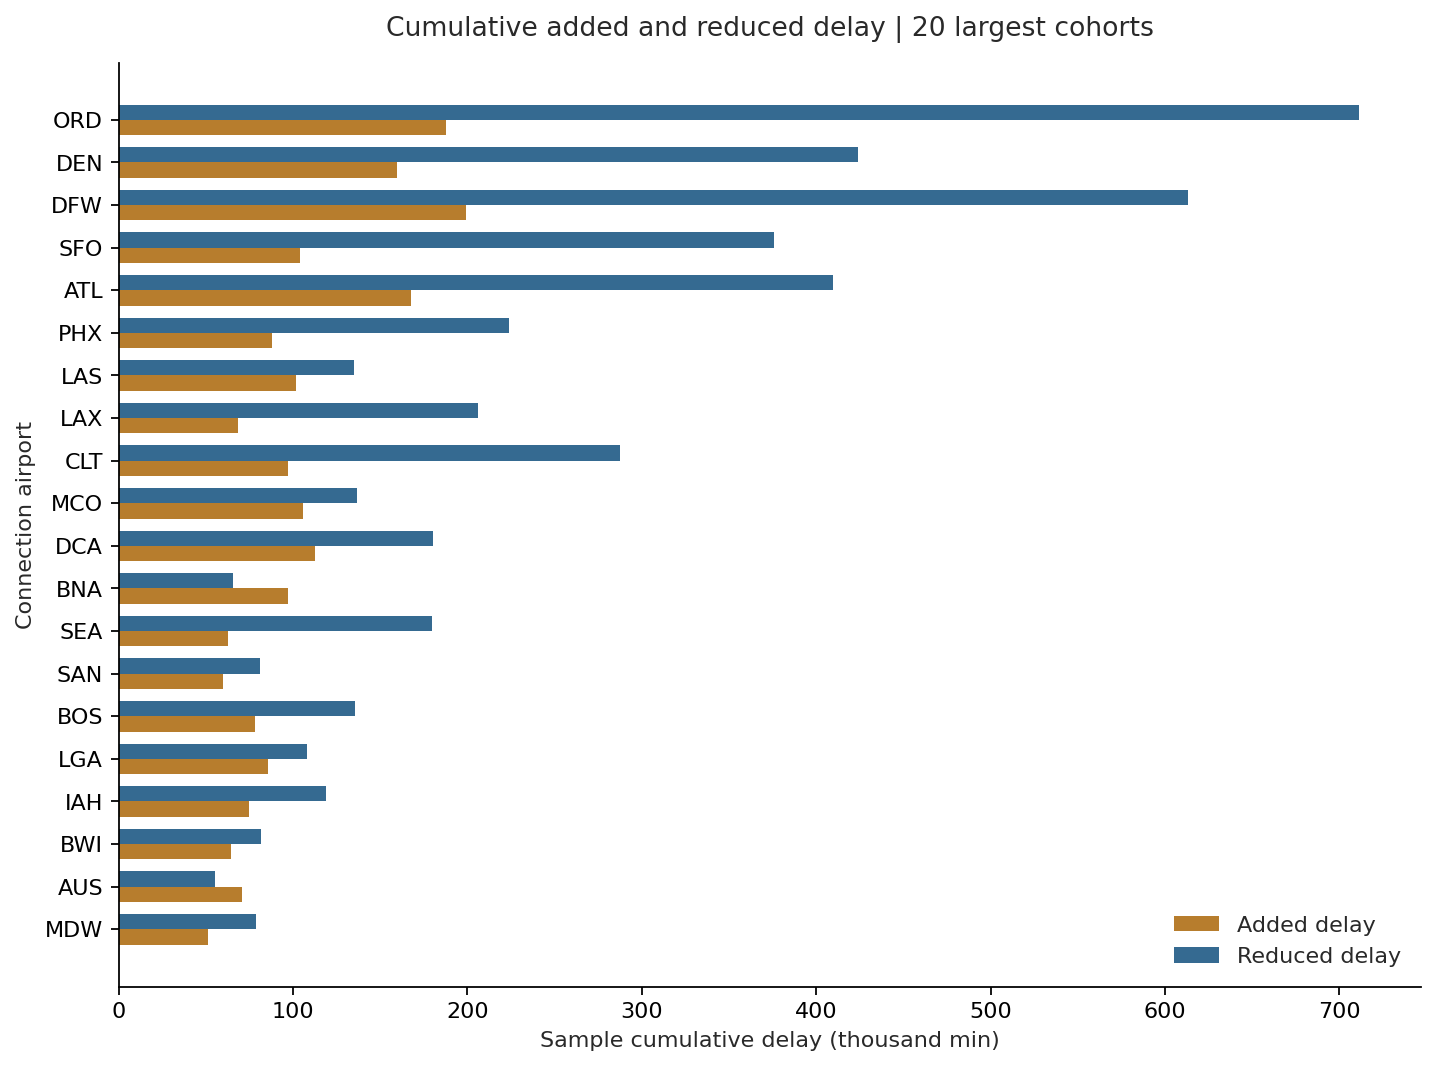

True

In [4]:
archived_json("rq1_complete_summary.json")
archived_json("rq1_summary.json")
archived_table("tables/rq1_airport_raw.csv")
archived_table("tables/rq1_airport_monthly.csv")
archived_image("figures/rq1_raw_airport_mean.png")
archived_image("figures/rq1_cumulative_delay.png")

## 3. 冻结共同支持：机场 A、分层 C 与权重 w

主比较只对上游到达延误和计划周转做标准化，\(\hat\mu_a=\sum_{c\in C}w_c\bar\Delta_{a,c}\)。机场集合、共同分层与参考权重在开发期冻结；每个阈值条件化同一主参考，不能分别挑选一套有利机场。天气与航司只作辅助分层。计划周转不是已知最低作业缓冲，实际地面时间不作为调整变量。

In [5]:
rq1_reference(RUN_DIR)
archived_json("rq1_standardized/rq1_standardization_summary.json")
archived_table("rq1_standardized/selection_attempts.csv", limit=None)
archived_table("rq1_standardized/rq1_cells.csv", limit=100)

**[frozen_reference.json](../experiments/runs/R0018/rq1_standardized/frozen_reference.json)**

```json
{
  "schema_version": 1,
  "frozen_on": "development_only",
  "supported": true,
  "protocol": {
    "registered_before_first_model": true,
    "development_window": [
      "2026-04-01T00:00:00Z",
      "2026-08-01T00:00:00Z"
    ],
    "main_threshold": 15,
    "sensitivity_thresholds": [
      "gt0",
      "ge5",
      "ge15"
    ],
    "master_delay_bins": [
      0,
      5,
      15,
      30,
      60,
      120,
      "inf"
    ],
    "turnaround_bins": [
      0,
      45,
      90,
      180,
      1440.000001
    ],
    "airport_min_main_rows": 1000,
    "airport_min_prediction_days": 30,
    "cell_min_rows": 30,
    "cell_min_prediction_days": 10,
    "minimum_retained_share": 0.5,
    "support_selection": "Use covariates and counts only; first full eligible airport set, then predeclared top 50/25/10/5 by main-sample count if support fails. Each attempt is retained. Stop at first cohort with >=2 airports, nonempty common cells and every airport retained share>=0.5.",
    "fallback_airport_limits": [
      50,
      25,
      10,
      5
    ],
    "weights": "Pooled development counts across selected airports within common cells; identical across airports. Threshold-specific conditioning of a fixed master grid/reference is required because eligibility populations differ.",
    "bootstrap": {
      "unit": "common UTC prediction-date moving blocks",
      "block_days": 7,
      "replicates": 1000,
      "seed": 42,
      "interval": "95% percentile",
      "min_valid_replicates": 950
    },
    "unsupported": "NA; never zero or per-airport renormalization",
    "test_period": "Freeze development airport set, cells, weights and rules before August; do not change to improve August support"
  },
  "interpretation": "Descriptive common-support differences; not causal airport effects."
}
```

**冻结的机场集合 A 与共同主分层 C**

,AirportID_in_A
0,13930
1,11292
2,11298
3,14771
4,10397
5,14107
6,12889
7,12892
8,11057
9,13204


,master_cell_in_C
0,0
1,1
2,4
3,5
4,8
5,9
6,10
7,12
8,13
9,14


...

,attempt,airport_limit,airports,passed,common_master_cells,airport_ids,threshold_support
0,1,NaN,66,False,"[1, 5, 9, 13, 17]","[13930, 11292, 11298, 14771, 10397, 14107, 128...","{""gt0"": {""cells"": [1, 5, 9, 13, 17], ""retained..."
1,2,50.0,50,False,"[1, 5, 9, 13, 17]","[13930, 11292, 11298, 14771, 10397, 14107, 128...","{""gt0"": {""cells"": [1, 5, 9, 13, 17], ""retained..."
2,3,25.0,25,True,"[0, 1, 4, 5, 8, 9, 10, 12, 13, 14, 16, 17, 18,...","[13930, 11292, 11298, 14771, 10397, 14107, 128...","{""gt0"": {""cells"": [0, 1, 4, 5, 8, 9, 10, 12, 1..."


**[rq1_cells.csv](../experiments/runs/R0018/rq1_standardized/rq1_cells.csv)**：完整表 20,984 行；当前条件 20,984 行。

,airport_id,cell,n,prediction_days,mean_delta,reduction_share,amplification_share,unchanged_share,threshold,selected_airport,reference_weight,in_frozen_common_support,cell_support_passed,delay_bin_lower,delay_bin_upper,turnaround_bin_lower,turnaround_bin_upper
0,10135,0,14,14,5.142857,0.500000,0.428571,0.071429,gt0,False,0.032979,False,False,0,5.0,0,45.000000
1,10135,1,30,28,6.866667,0.400000,0.533333,0.066667,gt0,False,0.110100,False,True,0,5.0,45,90.000000
2,10135,2,0,0,NaN,NaN,NaN,NaN,gt0,False,NaN,False,False,0,5.0,90,180.000000
3,10135,3,5,5,-2.200000,1.000000,0.000000,0.000000,gt0,False,NaN,False,False,0,5.0,180,1440.000001
4,10135,4,30,30,3.100000,0.600000,0.400000,0.000000,gt0,False,0.058266,False,True,5,15.0,0,45.000000
5,10135,5,61,48,2.459016,0.475410,0.426230,0.098361,gt0,False,0.187023,False,True,5,15.0,45,90.000000
6,10135,6,1,1,-12.000000,1.000000,0.000000,0.000000,gt0,False,NaN,False,False,5,15.0,90,180.000000
7,10135,7,11,11,10.545455,0.818182,0.181818,0.000000,gt0,False,NaN,False,False,5,15.0,180,1440.000001
8,10135,8,20,19,49.150000,0.650000,0.300000,0.050000,gt0,False,0.047076,False,False,15,30.0,0,45.000000
9,10135,9,26,24,3.692308,0.461538,0.500000,0.038462,gt0,False,0.151249,False,False,15,30.0,45,90.000000


上方仅展示前 100 行，完整结果见该归档 CSV。

,airport_id,cell,n,prediction_days,mean_delta,reduction_share,amplification_share,unchanged_share,threshold,selected_airport,reference_weight,in_frozen_common_support,cell_support_passed,delay_bin_lower,delay_bin_upper,turnaround_bin_lower,turnaround_bin_upper
0,10135,0,14,14,5.142857,0.500000,0.428571,0.071429,gt0,False,0.032979,False,False,0,5.0,0,45.000000
1,10135,1,30,28,6.866667,0.400000,0.533333,0.066667,gt0,False,0.110100,False,True,0,5.0,45,90.000000
2,10135,2,0,0,NaN,NaN,NaN,NaN,gt0,False,NaN,False,False,0,5.0,90,180.000000
3,10135,3,5,5,-2.200000,1.000000,0.000000,0.000000,gt0,False,NaN,False,False,0,5.0,180,1440.000001
4,10135,4,30,30,3.100000,0.600000,0.400000,0.000000,gt0,False,0.058266,False,True,5,15.0,0,45.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20979,16869,19,0,0,NaN,NaN,NaN,NaN,ge15,False,NaN,False,False,60,120.0,180,1440.000001
20980,16869,20,7,7,-5.714286,0.857143,0.142857,0.000000,ge15,False,NaN,False,False,120,inf,0,45.000000
20981,16869,21,0,0,NaN,NaN,NaN,NaN,ge15,False,0.048269,False,False,120,inf,45,90.000000
20982,16869,22,0,0,NaN,NaN,NaN,NaN,ge15,False,0.022080,False,False,120,inf,90,180.000000


## 4. 机场估计、日期块区间与阈值敏感性

机场估计同时给出保留样本、保留率、支持原因和区间。不支持的结果保留缺失，不填零或强行排名。以同一 UTC 日期块共同重抽样，区间表示抽样不确定性；成对机场差异使用同一重复样本，未做多重比较校正。>0、≥5、≥15 分钟的方向一致率与 Spearman 只在共同可比机场上计算。

**[rq1_airports.csv](../experiments/runs/R0018/rq1_standardized/rq1_airports.csv)**：完整表 1,049 行；当前条件 349 行。

,airport_id,n,prediction_days,mean_delta,s_plus,s_minus,s_net,threshold,selected_airport,retained_n,retained_share,supported,standardized_mean,standardized_reduction_share,standardized_amplification_share,standardized_unchanged_share,ci_low,ci_high,valid_replicates,support_reason,s_plus_ci_low,s_plus_ci_high,s_minus_ci_low,s_minus_ci_high,s_net_ci_low,s_net_ci_high,rank
700,10135,183,95,19.142077,5887.0,2384.0,3503.0,ge15,False,0,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,0,outside_frozen_airport_set,1759.375,9824.225,1790.000,3023.125,-545.600,7310.425,NaN
701,10136,104,65,2.048077,1495.0,1282.0,213.0,ge15,False,0,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,0,outside_frozen_airport_set,698.975,2851.075,896.000,1644.075,-577.050,1544.750,NaN
702,10140,1216,122,2.908717,13247.0,9710.0,3537.0,ge15,False,0,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,0,outside_frozen_airport_set,8848.025,16997.600,7803.800,11318.125,-839.825,7766.075,NaN
703,10141,7,7,-3.142857,36.0,58.0,-22.0,ge15,False,0,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,0,outside_frozen_airport_set,0.000,108.000,5.000,92.025,-80.000,87.000,NaN
704,10154,187,55,15.513369,4357.0,1456.0,2901.0,ge15,False,0,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,0,outside_frozen_airport_set,873.625,8187.400,795.950,2213.575,-408.025,6389.800,NaN
705,10155,35,30,5.200000,337.0,155.0,182.0,ge15,False,0,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,0,outside_frozen_airport_set,78.775,728.050,92.000,226.025,-88.000,576.100,NaN
706,10157,170,96,-4.358824,1234.0,1975.0,-741.0,ge15,False,0,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,0,outside_frozen_airport_set,624.000,1916.275,1344.925,2799.200,-1802.500,315.125,NaN
707,10158,109,80,36.174312,5070.0,1127.0,3943.0,ge15,False,0,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,0,outside_frozen_airport_set,2128.000,8810.725,178.325,2052.000,865.675,8196.275,NaN
708,10165,2,2,7.000000,15.0,1.0,14.0,ge15,False,0,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,0,outside_frozen_airport_set,0.000,45.000,0.000,3.000,-3.000,45.000,NaN
709,10170,21,20,-3.142857,49.0,115.0,-66.0,ge15,False,0,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,0,outside_frozen_airport_set,13.975,96.000,57.975,195.025,-139.000,-4.000,NaN


**[rq1_pairwise_differences.csv](../experiments/runs/R0018/rq1_standardized/rq1_pairwise_differences.csv)**：完整表 900 行；当前条件 900 行。

,threshold,airport_left,airport_right,mean_difference,ci_low,ci_high,valid_replicates
0,gt0,13930,11292,-2.638591,-3.824831,-1.292735,1000
1,gt0,13930,11298,-6.907470,-8.654650,-5.034538,1000
2,gt0,13930,14771,1.664041,0.241471,3.121290,1000
3,gt0,13930,10397,-7.084535,-9.359336,-4.725341,1000
4,gt0,13930,14107,-1.318917,-2.655882,-0.078969,1000
5,gt0,13930,12889,-5.377555,-7.346106,-3.487289,1000
6,gt0,13930,12892,-1.795637,-3.127382,-0.488227,1000
7,gt0,13930,11057,-5.647539,-7.512668,-3.505551,1000
8,gt0,13930,13204,-8.147580,-10.699471,-6.194894,1000
9,gt0,13930,11278,-3.038852,-6.095304,-0.173164,1000


上方仅展示前 100 行，完整结果见该归档 CSV。

**[rq1_threshold_stability.csv](../experiments/runs/R0018/rq1_standardized/rq1_threshold_stability.csv)**：完整表 3 行；当前条件 3 行。

,threshold,common_airports,frozen_airports,common_airport_share,direction_agreement,spearman
0,gt0,25,25,1.0,0.76,0.973846
1,ge5,25,25,1.0,0.96,0.980769
2,ge15,25,25,1.0,1.00,1.000000


**[rq1_standardized_airports.png](../experiments/runs/R0018/figures/rq1_standardized_airports.png)**

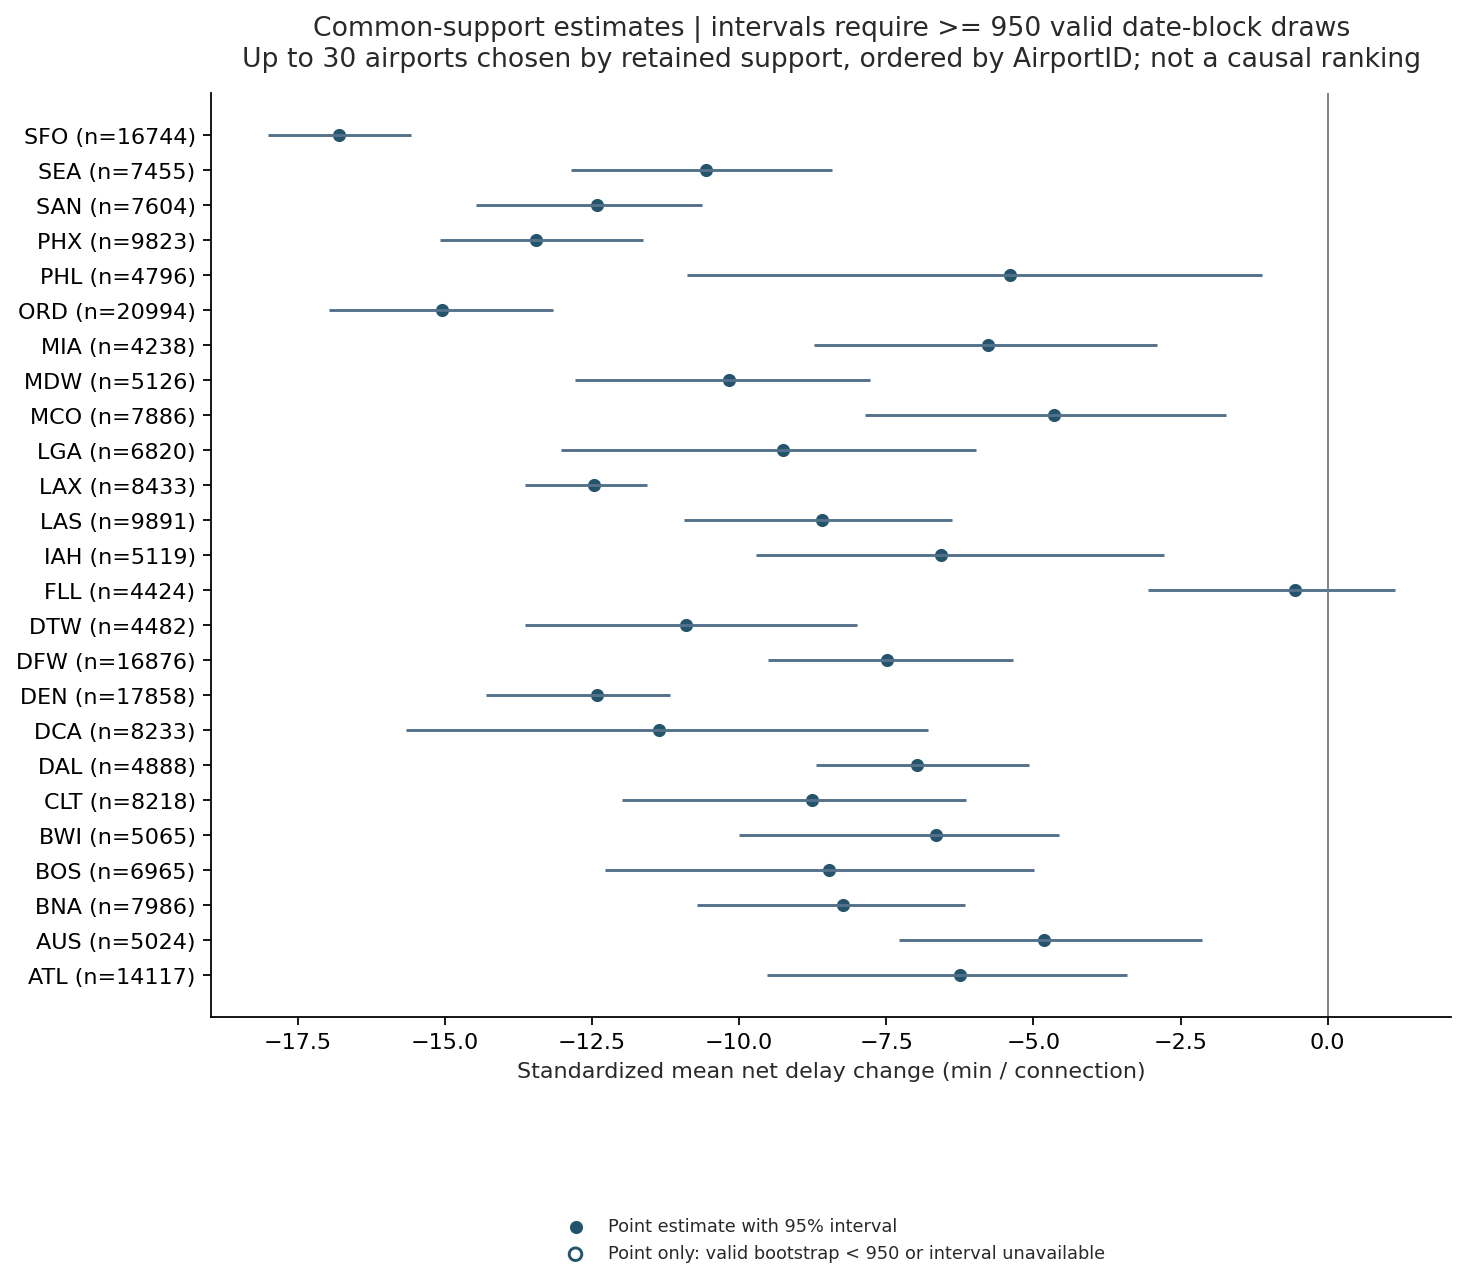

**[rq1_threshold_stability.png](../experiments/runs/R0018/figures/rq1_threshold_stability.png)**

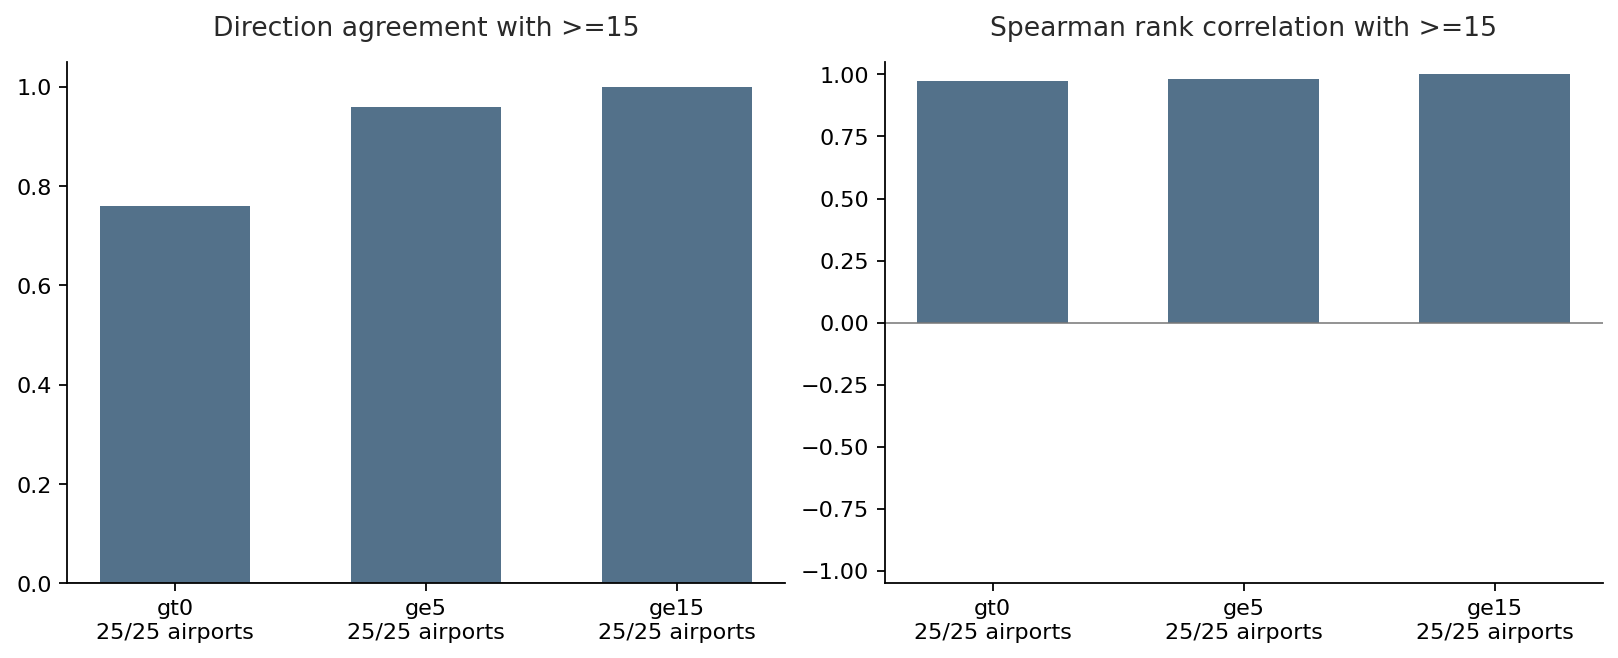

True

In [6]:
archived_table("rq1_standardized/rq1_airports.csv", limit=None, filters={"threshold": "ge15"})
archived_table("rq1_standardized/rq1_pairwise_differences.csv")
archived_table("rq1_standardized/rq1_threshold_stability.csv", limit=None)
archived_image("figures/rq1_standardized_airports.png")
archived_image("figures/rq1_threshold_stability.png")

## 5. 按月稳定性与网络导航

逐月复用同一冻结 A/C/w；低支持月份仍保留缺失。经纬度布局图的节点大小表示有效衔接数，节点颜色表示共同支持中的每次标准化净变化，灰色表示不支持；有向边宽表示 BTS 航班量，不表示传播强度。图仅显示有限主要航线及面板内连线，完整节点/边表保留全部范围。

**[rq1_airports_monthly.csv](../experiments/runs/R0018/rq1_standardized/rq1_airports_monthly.csv)**：完整表 4,089 行；当前条件 4,089 行。

,month_utc,airport_id,n,prediction_days,mean_delta,s_plus,s_minus,s_net,threshold,selected_airport,retained_n,retained_share,supported,standardized_mean,standardized_reduction_share,standardized_amplification_share,standardized_unchanged_share,ci_low,ci_high,valid_replicates,support_reason,s_plus_ci_low,s_plus_ci_high,s_minus_ci_low,s_minus_ci_high,s_net_ci_low,s_net_ci_high,rank
0,2026-04,10135,70,29,9.157143,1180.0,539.0,641.0,gt0,False,0,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,0,outside_frozen_airport_set,68.975,3157.025,393.000,736.025,-570.000,2611.275,NaN
1,2026-04,10136,46,21,-2.347826,254.0,362.0,-108.0,gt0,False,0,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,0,outside_frozen_airport_set,77.975,318.175,188.000,426.000,-282.000,34.075,NaN
2,2026-04,10140,435,30,3.296552,4006.0,2572.0,1434.0,gt0,False,0,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,0,outside_frozen_airport_set,1728.575,5465.325,2016.975,2940.175,-470.025,2768.475,NaN
3,2026-04,10141,8,8,-7.500000,0.0,60.0,-60.0,gt0,False,0,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,0,outside_frozen_airport_set,0.000,0.000,20.000,83.025,-83.025,-20.000,NaN
4,2026-04,10155,7,5,-6.285714,2.0,46.0,-44.0,gt0,False,0,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,0,outside_frozen_airport_set,0.000,2.000,12.000,86.000,-86.000,-10.000,NaN
5,2026-04,10157,54,26,-0.407407,250.0,272.0,-22.0,gt0,False,0,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,0,outside_frozen_airport_set,164.975,448.000,181.000,379.000,-170.000,202.100,NaN
6,2026-04,10158,68,29,-13.882353,205.0,1149.0,-944.0,gt0,False,0,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,0,outside_frozen_airport_set,118.000,301.025,600.725,1674.200,-1414.000,-419.850,NaN
7,2026-04,10165,2,2,7.000000,15.0,1.0,14.0,gt0,False,0,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,0,outside_frozen_airport_set,0.000,45.000,0.000,3.000,-3.000,45.000,NaN
8,2026-04,10170,6,6,-2.333333,3.0,17.0,-14.0,gt0,False,0,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,0,outside_frozen_airport_set,0.000,9.000,4.000,32.000,-30.000,3.000,NaN
9,2026-04,10185,12,8,7.750000,106.0,13.0,93.0,gt0,False,0,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,0,outside_frozen_airport_set,2.000,117.100,2.000,23.025,-12.000,110.000,NaN


上方仅展示前 100 行，完整结果见该归档 CSV。

**[rq1_standardization_summary.json](../experiments/runs/R0018/rq1_standardized/monthly/2026-04/rq1_standardization_summary.json)**

```json
{
  "development": true,
  "frozen_reference_reused": true,
  "period": [
    "2026-04-01 00:00:00+00:00",
    "2026-05-01 00:00:00+00:00"
  ],
  "selected_airports": 25,
  "supported_reference": true,
  "bootstrap": {
    "unit": "common UTC prediction-date moving blocks",
    "block_days": 7,
    "replicates": 1000,
    "seed": 42,
    "interval": "95% percentile",
    "min_valid_replicates": 950
  },
  "calendar_days": 30,
  "sample_rule": "accepted, nonovernight, upstream positive; threshold-specific subsets",
  "uncertainty": "Common calendar moving blocks; fixed airports/cells/weights, no reselection per replicate; percentile intervals are not multiplicity adjusted.",
  "units": {
    "standardized_mean": "minutes per connection",
    "s_plus_s_minus_s_net": "sample cumulative minutes"
  }
}
```

...

上方仅展示前 100 行，完整结果见该归档 CSV。

**[network_edges.csv](../experiments/runs/R0018/rq1_standardized/network_edges.csv)**：完整表 6,600 行；当前条件 6,600 行。

,origin_airport_id,destination_airport_id,flight_count
0,10135,10397,55
1,10135,10693,21
2,10135,11057,242
3,10135,11292,21
4,10135,11697,36
5,10135,13204,39
6,10135,13360,35
7,10135,13577,100
8,10135,13930,251
9,10135,14082,90


上方仅展示前 100 行，完整结果见该归档 CSV。

**[rq1_network_geographic.png](../experiments/runs/R0018/figures/rq1_network_geographic.png)**

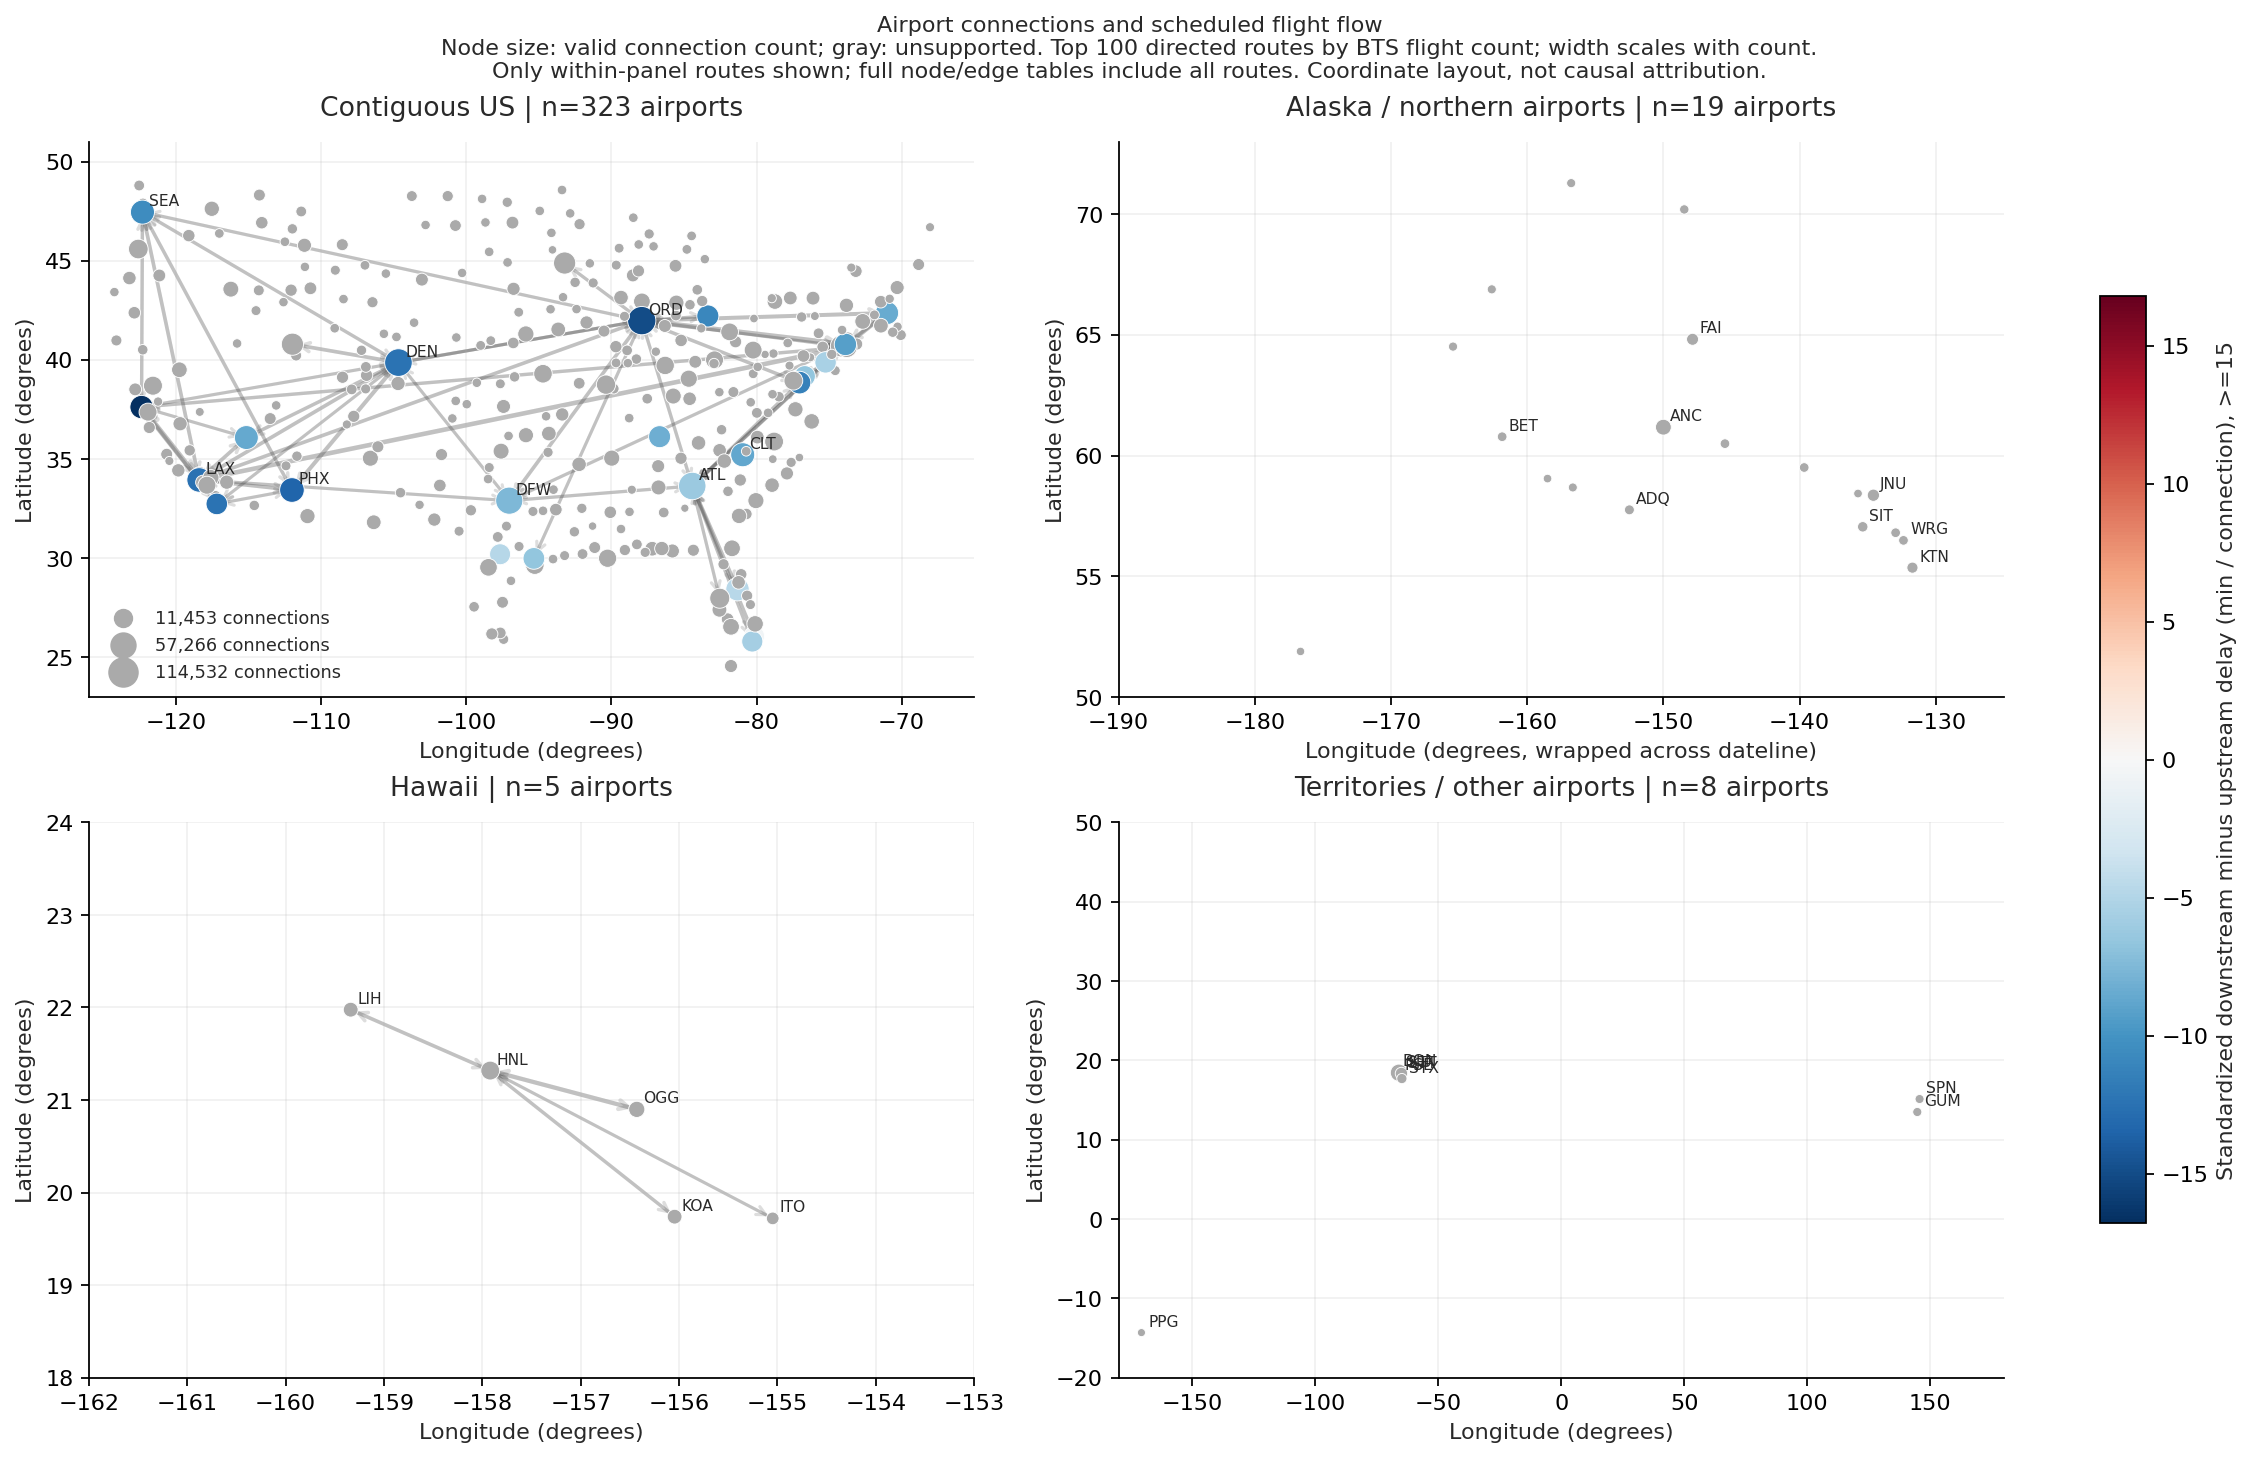

True

In [7]:
archived_table("rq1_standardized/rq1_airports_monthly.csv")
archive_matches("rq1_standardized/monthly/*/rq1_standardization_summary.json", kind="json")
archived_table("rq1_standardized/network_nodes.csv")
archived_table("rq1_standardized/network_edges.csv")
archived_image("figures/rq1_network_geographic.png")

## 6. 动态模型与基线比较

每轮实际算法、特征、参数和误差来自该轮 manifest/metrics。训练中位数直接对应绝对误差目标，训练均值对应平方误差目标；目标偏态时两种常数基线的 MAE 可以明显不同。carry-forward 是已知上游延误原样传递，也不应与常数基线混称。学习模型若没有优于中位数，应如实保留该结果。特征增益和算法增益分开比较，同样本差值才有直接意义。

### 模型归档：R0006

运行状态：**completed**。

```json
{
  "feature_group": "G0",
  "model_name": "g0_linear",
  "model_type": "linear",
  "models": [
    "training_mean",
    "training_median",
    "carry_forward",
    "g0_linear"
  ],
  "features": [
    "airport_id",
    "route",
    "downstream_airline",
    "downstream_distance",
    "downstream_crs_elapsed_time",
    "downstream_day_of_week",
    "downstream_sched_hour",
    "scheduled_turnaround_minutes"
  ],
  "categorical_features": [
    "airport_id",
    "route",
    "downstream_airline"
  ],
  "numeric_features": [
    "downstream_distance",
    "downstream_crs_elapsed_time",
    "downstream_day_of_week",
    "downstream_sched_hour",
    "scheduled_turnaround_minutes"
  ],
  "model_params": {
    "copy_X": true,
    "fit_intercept": true,
    "n_jobs": 8,
    "positive": false,
    "tol": 1e-06
  },
  "effective_preprocessing": {
    "min_frequency": 20,
    "drop": "first",
    "sparse": true,
    "categorical_imputation": "constant __MISSING__; keep_empty_features=True",
    "numeric_imputation": "median; add_indicator=True; keep_empty_features=True",
    "numeric_scaling": "StandardScaler(with_mean=False), fixed across algorithms",
    "unknown_categories": "infrequent_if_exist"
  },
  "evaluation_rows": 1707091,
  "evaluation_ids_sha256": "db4e500797d62152fece891a62b9c171822e97e4dea76ab92efd587bcfa8d68c",
  "split_sha256": "4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018967420e7e24441a593"
}
```

**[metrics.csv](../experiments/runs/R0006/metrics.csv)**：完整表 6,388 行；当前条件 16 行。

,model,fold,group,value,n,mae,rmse,target_ge15_share,unit,absolute_error_sum,squared_error_sum,target_ge15_n
0,training_mean,2026-05,all,all,574571,17.969705,43.443239,0.207785,minutes,1.032487e+07,1.084396e+09,119387
395,training_median,2026-05,all,all,574571,13.209259,45.383891,0.207785,minutes,7.589657e+06,1.183442e+09,119387
790,carry_forward,2026-05,all,all,574571,14.173169,49.267137,0.207785,minutes,8.143492e+06,1.394628e+09,119387
1185,g0_linear,2026-05,all,all,574571,17.021161,43.097816,0.207785,minutes,9.779866e+06,1.067221e+09,119387
1580,training_mean,2026-06,all,all,561972,21.068890,50.817858,0.247952,minutes,1.184013e+07,1.451267e+09,139342
1979,training_median,2026-06,all,all,561972,16.995806,53.396380,0.247952,minutes,9.551167e+06,1.602280e+09,139342
2378,carry_forward,2026-06,all,all,561972,17.543874,56.830990,0.247952,minutes,9.859166e+06,1.815035e+09,139342
2777,g0_linear,2026-06,all,all,561972,19.667731,50.034227,0.247952,minutes,1.105271e+07,1.406854e+09,139342
3176,training_mean,2026-07,all,all,570548,23.718273,57.589119,0.272265,minutes,1.353241e+07,1.892226e+09,155340
3576,training_median,2026-07,all,all,570548,19.678702,60.592404,0.272265,minutes,1.122764e+07,2.094732e+09,155340


...

**[comparison_metrics.csv](../experiments/runs/R0007/comparison/comparison_metrics.csv)**：完整表 8 行；当前条件 8 行。

,scope,metric,n,calendar_dates,reference_error,candidate_error,difference_candidate_minus_reference,ci95_low,ci95_high,valid_bootstrap_repeats,unit,sample_scope
0,2026-05,mae,574571,31,17.021161,14.790785,-2.230377,-2.305851,-2.092327,1000,minutes,full_evaluation
1,2026-05,rmse,574571,31,43.097816,40.424176,-2.673640,-3.377638,-1.868658,1000,minutes,full_evaluation
2,2026-06,mae,561972,30,19.667731,17.354639,-2.313093,-2.441001,-2.104950,1000,minutes,full_evaluation
3,2026-06,rmse,561972,30,50.034227,46.539443,-3.494784,-4.408066,-2.992622,1000,minutes,full_evaluation
4,2026-07,mae,570548,31,22.052005,19.647748,-2.404257,-2.561392,-2.226160,1000,minutes,full_evaluation
5,2026-07,rmse,570548,31,56.694487,53.045264,-3.649223,-4.195264,-3.324499,1000,minutes,full_evaluation
6,pooled,mae,1707091,92,19.573829,17.258108,-2.315721,-2.406308,-2.215774,1000,minutes,full_evaluation
7,pooled,rmse,1707091,92,50.235168,46.941039,-3.294128,-3.745491,-2.831743,1000,minutes,full_evaluation


**[comparison.json](../experiments/runs/R0007/comparison/comparison.json)**

```json
{
  "reference_run": "R0006",
  "candidate_run": "R0007",
  "reference_model": "g0_linear",
  "candidate_model": "g1_linear",
  "parent_run_id": "R0006",
  "candidate_declared_parent": "R0006",
  "comparison_purpose": null,
  "align_rows": false,
  "candidate_status_at_comparison": "running",
  "allow_running_candidate": true,
  "evaluation_ids_sha256": "db4e500797d62152fece891a62b9c171822e97e4dea76ab92efd587bcfa8d68c",
  "split_sha256": "4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018967420e7e24441a593",
  "sample_scope": "full_evaluation",
  "full_evaluation_n": 1707091,
  "compared_n": 1707091,
  "compared_identity_set_sha256": "cb539627cfec0128f2fd808ee86124ee174250e0246c8054e7372968c8a56506",
  "common_sample_columns": null,
  "difference_definition": "candidate minus reference; positive is worse",
  "bootstrap": {
    "method": "paired non-circular moving UTC date blocks",
    "block_days": 7,
    "repeats": 1000,
    "seed": 42,
    "confidence_level": 0.95,
    "full_calendar": "2026-05-01 through 2026-07-31 UTC, including zero-sample dates",
    "monthly_intervals": "resample each monthly calendar separately",
    "pooled_interval": "resample the full validation calendar; blocks never cross date gaps",
    "empty_resamples": "Exclude only bootstrap replicates with sampled n=0; valid replicate counts are reported; no prediction rows are dropped",
    "weighting": "sum AE / sum n; sqrt(sum SE / sum n); same sampled dates for both models"
  },
  "interpretation": "Paired sampling uncertainty, not causal evidence; explicit subsets are supplementary comparisons",
  "outputs": [
    "comparison_daily_stats.csv",
    "comparison_metrics.csv",
    "comparison_error_differences.png",
    "comparison.json"
  ]
}
```

**[comparison_error_differences.png](../experiments/runs/R0007/comparison/comparison_error_differences.png)**

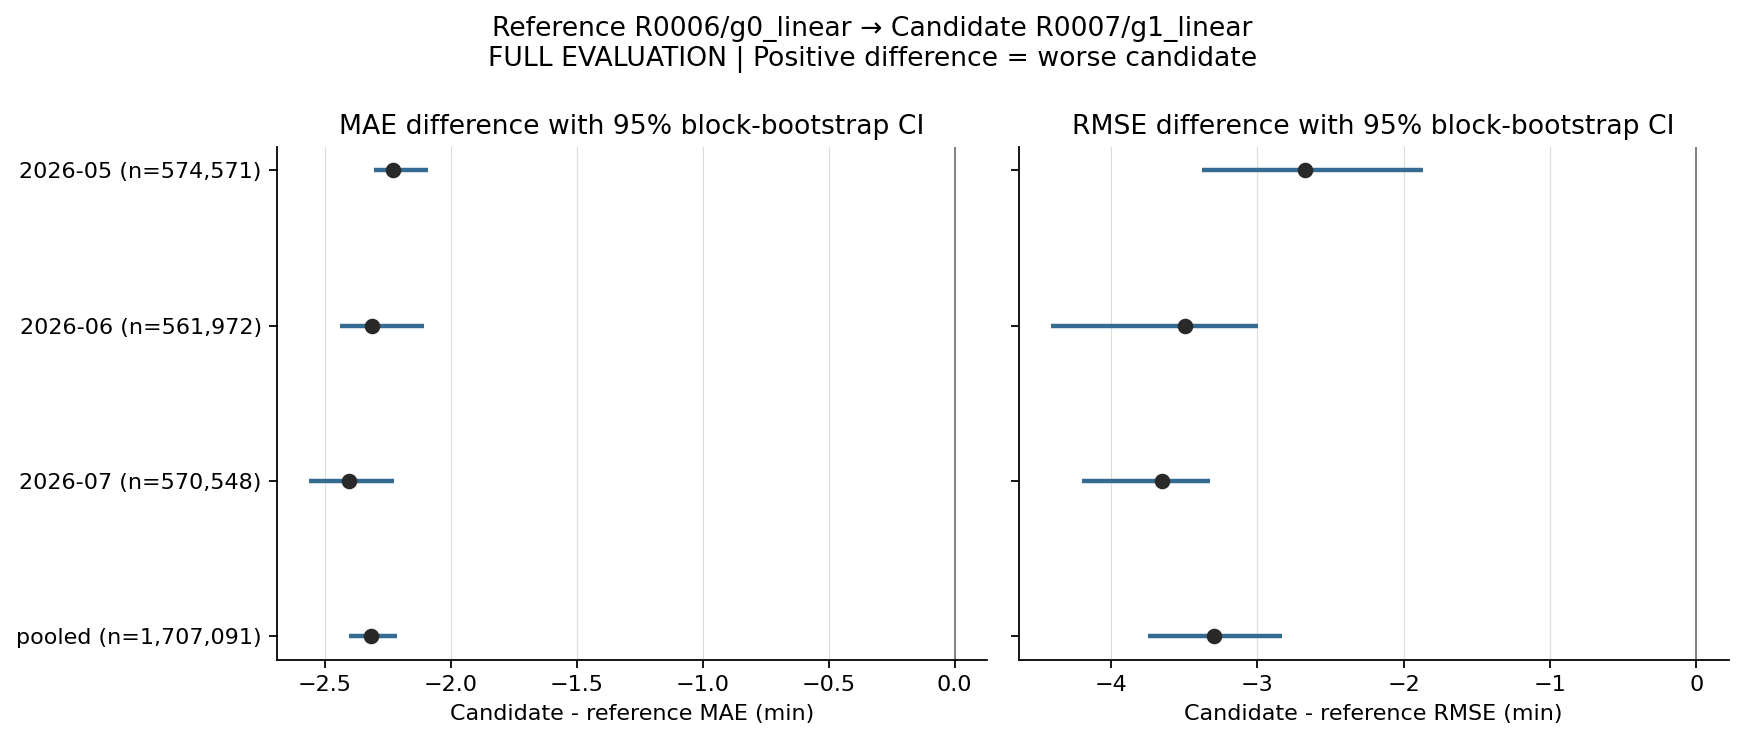

### 模型归档：R0009

运行状态：**completed**。

```json
{
  "feature_group": "G2",
  "model_name": "g2_family_linear",
  "model_type": "linear",
  "models": [
    "training_mean",
    "training_median",
    "carry_forward",
    "g2_family_linear"
  ],
  "features": [
    "airport_id",
    "route",
    "downstream_airline",
    "aircraft_family",
    "downstream_distance",
    "downstream_crs_elapsed_time",
    "downstream_day_of_week",
    "downstream_sched_hour",
    "scheduled_turnaround_minutes",
    "upstream_arr_delay_minutes",
    "tail_completed_24h_n",
    "tail_completed_24h_arr_delay_mean",
    "history_window_incomplete"
  ],
  "categorical_features": [
    "airport_id",
    "route",
    "downstream_airline",
    "aircraft_family"
  ],
  "numeric_features": [
    "downstream_distance",
    "downstream_crs_elapsed_time",
    "downstream_day_of_week",
    "downstream_sched_hour",
    "scheduled_turnaround_minutes",
    "upstream_arr_delay_minutes",
    "tail_completed_24h_n",
    "tail_completed_24h_arr_delay_mean",
    "history_window_incomplete"
  ],
  "model_params": {
    "copy_X": true,
    "fit_intercept": true,
    "n_jobs": 8,
    "positive": false,
    "tol": 1e-06
  },
  "effective_preprocessing": {
    "min_frequency": 20,
    "drop": "first",
    "sparse": true,
    "categorical_imputation": "constant __MISSING__; keep_empty_features=True",
    "numeric_imputation": "median; add_indicator=True; keep_empty_features=True",
    "numeric_scaling": "StandardScaler(with_mean=False), fixed across algorithms",
    "unknown_categories": "infrequent_if_exist"
  },
  "evaluation_rows": 1707091,
  "evaluation_ids_sha256": "db4e500797d62152fece891a62b9c171822e97e4dea76ab92efd587bcfa8d68c",
  "split_sha256": "4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018967420e7e24441a593"
}
```

**[metrics.csv](../experiments/runs/R0009/metrics.csv)**：完整表 6,644 行；当前条件 16 行。

,model,fold,group,value,n,mae,rmse,target_ge15_share,unit,absolute_error_sum,squared_error_sum,target_ge15_n
0,training_mean,2026-05,all,all,574571,17.969705,43.443239,0.207785,minutes,1.032487e+07,1.084396e+09,119387
411,training_median,2026-05,all,all,574571,13.209259,45.383891,0.207785,minutes,7.589657e+06,1.183442e+09,119387
822,carry_forward,2026-05,all,all,574571,14.173169,49.267137,0.207785,minutes,8.143492e+06,1.394628e+09,119387
1233,g2_family_linear,2026-05,all,all,574571,14.782844,40.418944,0.207785,minutes,8.493794e+06,9.386715e+08,119387
1644,training_mean,2026-06,all,all,561972,21.068890,50.817858,0.247952,minutes,1.184013e+07,1.451267e+09,139342
2059,training_median,2026-06,all,all,561972,16.995806,53.396380,0.247952,minutes,9.551167e+06,1.602280e+09,139342
2474,carry_forward,2026-06,all,all,561972,17.543874,56.830990,0.247952,minutes,9.859166e+06,1.815035e+09,139342
2889,g2_family_linear,2026-06,all,all,561972,17.345149,46.536036,0.247952,minutes,9.747488e+06,1.217008e+09,139342
3304,training_mean,2026-07,all,all,570548,23.718273,57.589119,0.272265,minutes,1.353241e+07,1.892226e+09,155340
3720,training_median,2026-07,all,all,570548,19.678702,60.592404,0.272265,minutes,1.122764e+07,2.094732e+09,155340


**[comparison_metrics.csv](../experiments/runs/R0009/comparison/comparison_metrics.csv)**：完整表 8 行；当前条件 8 行。

,scope,metric,n,calendar_dates,reference_error,candidate_error,difference_candidate_minus_reference,ci95_low,ci95_high,valid_bootstrap_repeats,unit,sample_scope
0,2026-05,mae,574571,31,14.790785,14.782844,-0.007940,-0.012248,-0.003740,1000,minutes,full_evaluation
1,2026-05,rmse,574571,31,40.424176,40.418944,-0.005232,-0.008355,-0.003355,1000,minutes,full_evaluation
2,2026-06,mae,561972,30,17.354639,17.345149,-0.009490,-0.011834,-0.007331,1000,minutes,full_evaluation
3,2026-06,rmse,561972,30,46.539443,46.536036,-0.003407,-0.005009,-0.001818,1000,minutes,full_evaluation
4,2026-07,mae,570548,31,19.647748,19.637015,-0.010733,-0.013227,-0.008168,1000,minutes,full_evaluation
5,2026-07,rmse,570548,31,53.045264,53.040538,-0.004726,-0.005817,-0.003210,1000,minutes,full_evaluation
6,pooled,mae,1707091,92,17.258108,17.248724,-0.009384,-0.011091,-0.007404,1000,minutes,full_evaluation
7,pooled,rmse,1707091,92,46.941039,46.936626,-0.004414,-0.005529,-0.003265,1000,minutes,full_evaluation


**[comparison.json](../experiments/runs/R0009/comparison/comparison.json)**

```json
{
  "reference_run": "R0007",
  "candidate_run": "R0009",
  "reference_model": "g1_linear",
  "candidate_model": "g2_family_linear",
  "parent_run_id": "R0007",
  "candidate_declared_parent": "R0007",
  "comparison_purpose": null,
  "align_rows": false,
  "candidate_status_at_comparison": "running",
  "allow_running_candidate": true,
  "evaluation_ids_sha256": "db4e500797d62152fece891a62b9c171822e97e4dea76ab92efd587bcfa8d68c",
  "split_sha256": "4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018967420e7e24441a593",
  "sample_scope": "full_evaluation",
  "full_evaluation_n": 1707091,
  "compared_n": 1707091,
  "compared_identity_set_sha256": "cb539627cfec0128f2fd808ee86124ee174250e0246c8054e7372968c8a56506",
  "common_sample_columns": null,
  "difference_definition": "candidate minus reference; positive is worse",
  "bootstrap": {
    "method": "paired non-circular moving UTC date blocks",
    "block_days": 7,
    "repeats": 1000,
    "seed": 42,
    "confidence_level": 0.95,
    "full_calendar": "2026-05-01 through 2026-07-31 UTC, including zero-sample dates",
    "monthly_intervals": "resample each monthly calendar separately",
    "pooled_interval": "resample the full validation calendar; blocks never cross date gaps",
    "empty_resamples": "Exclude only bootstrap replicates with sampled n=0; valid replicate counts are reported; no prediction rows are dropped",
    "weighting": "sum AE / sum n; sqrt(sum SE / sum n); same sampled dates for both models"
  },
  "interpretation": "Paired sampling uncertainty, not causal evidence; explicit subsets are supplementary comparisons",
  "outputs": [
    "comparison_daily_stats.csv",
    "comparison_metrics.csv",
    "comparison_error_differences.png",
    "comparison.json"
  ]
}
```

**[comparison_error_differences.png](../experiments/runs/R0009/comparison/comparison_error_differences.png)**

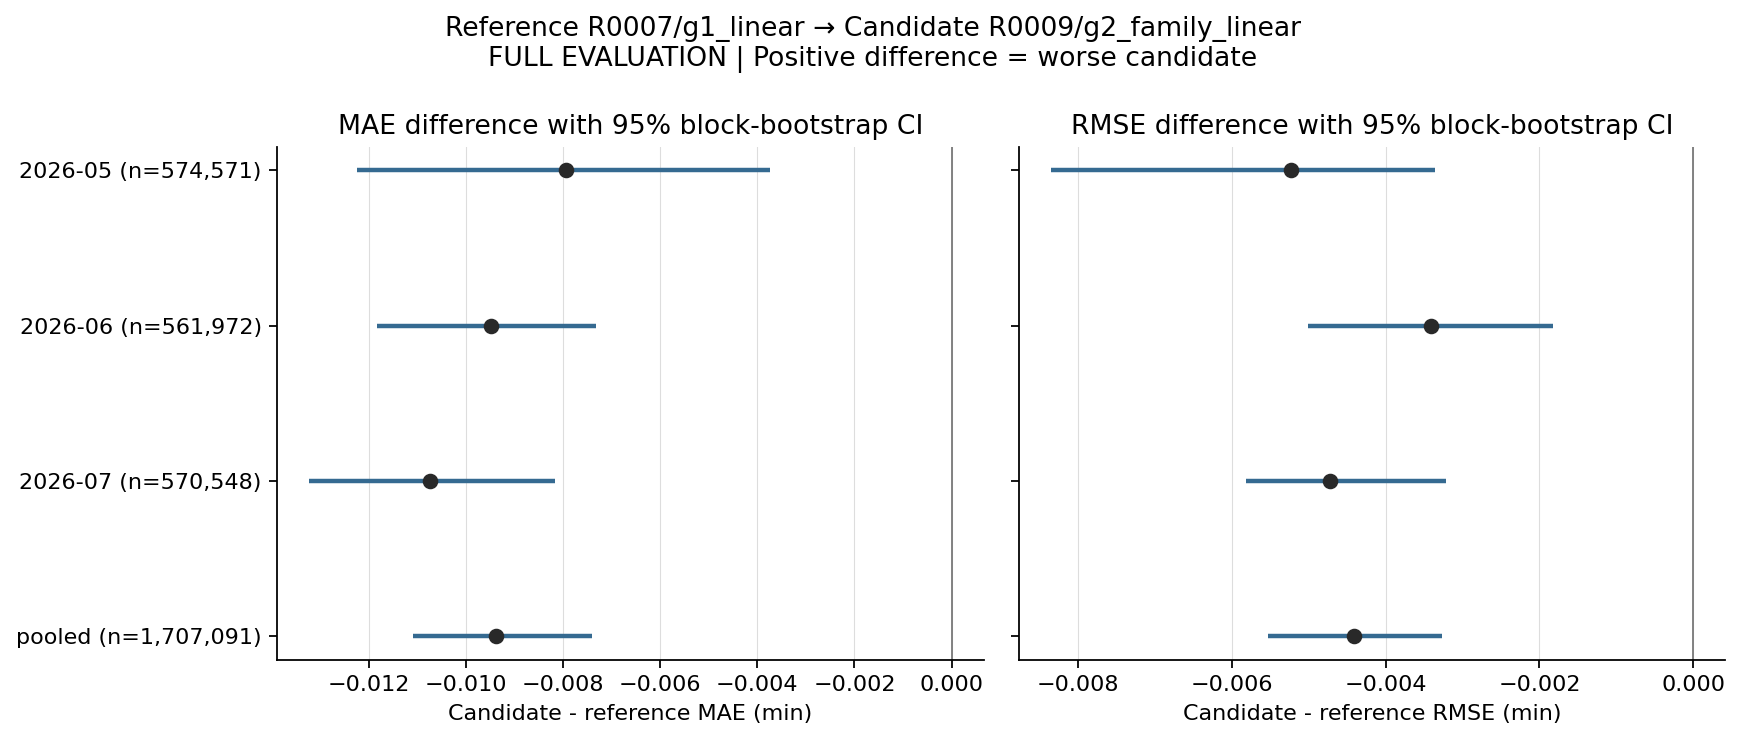

### 模型归档：R0010

运行状态：**completed**。

```json
{
  "feature_group": "G2_VARIANT",
  "model_name": "g2_variant_linear",
  "model_type": "linear",
  "models": [
    "training_mean",
    "training_median",
    "carry_forward",
    "g2_variant_linear"
  ],
  "features": [
    "airport_id",
    "route",
    "downstream_airline",
    "aircraft_variant",
    "downstream_distance",
    "downstream_crs_elapsed_time",
    "downstream_day_of_week",
    "downstream_sched_hour",
    "scheduled_turnaround_minutes",
    "upstream_arr_delay_minutes",
    "tail_completed_24h_n",
    "tail_completed_24h_arr_delay_mean",
    "history_window_incomplete"
  ],
  "categorical_features": [
    "airport_id",
    "route",
    "downstream_airline",
    "aircraft_variant"
  ],
  "numeric_features": [
    "downstream_distance",
    "downstream_crs_elapsed_time",
    "downstream_day_of_week",
    "downstream_sched_hour",
    "scheduled_turnaround_minutes",
    "upstream_arr_delay_minutes",
    "tail_completed_24h_n",
    "tail_completed_24h_arr_delay_mean",
    "history_window_incomplete"
  ],
  "model_params": {
    "copy_X": true,
    "fit_intercept": true,
    "n_jobs": 8,
    "positive": false,
    "tol": 1e-06
  },
  "effective_preprocessing": {
    "min_frequency": 20,
    "drop": "first",
    "sparse": true,
    "categorical_imputation": "constant __MISSING__; keep_empty_features=True",
    "numeric_imputation": "median; add_indicator=True; keep_empty_features=True",
    "numeric_scaling": "StandardScaler(with_mean=False), fixed across algorithms",
    "unknown_categories": "infrequent_if_exist"
  },
  "evaluation_rows": 1707091,
  "evaluation_ids_sha256": "db4e500797d62152fece891a62b9c171822e97e4dea76ab92efd587bcfa8d68c",
  "split_sha256": "4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018967420e7e24441a593"
}
```

**[metrics.csv](../experiments/runs/R0010/metrics.csv)**：完整表 6,388 行；当前条件 16 行。

,model,fold,group,value,n,mae,rmse,target_ge15_share,unit,absolute_error_sum,squared_error_sum,target_ge15_n
0,training_mean,2026-05,all,all,574571,17.969705,43.443239,0.207785,minutes,1.032487e+07,1.084396e+09,119387
395,training_median,2026-05,all,all,574571,13.209259,45.383891,0.207785,minutes,7.589657e+06,1.183442e+09,119387
790,carry_forward,2026-05,all,all,574571,14.173169,49.267137,0.207785,minutes,8.143492e+06,1.394628e+09,119387
1185,g2_variant_linear,2026-05,all,all,574571,14.781731,40.417052,0.207785,minutes,8.493154e+06,9.385836e+08,119387
1580,training_mean,2026-06,all,all,561972,21.068890,50.817858,0.247952,minutes,1.184013e+07,1.451267e+09,139342
1979,training_median,2026-06,all,all,561972,16.995806,53.396380,0.247952,minutes,9.551167e+06,1.602280e+09,139342
2378,carry_forward,2026-06,all,all,561972,17.543874,56.830990,0.247952,minutes,9.859166e+06,1.815035e+09,139342
2777,g2_variant_linear,2026-06,all,all,561972,17.343130,46.533232,0.247952,minutes,9.746353e+06,1.216861e+09,139342
3176,training_mean,2026-07,all,all,570548,23.718273,57.589119,0.272265,minutes,1.353241e+07,1.892226e+09,155340
3576,training_median,2026-07,all,all,570548,19.678702,60.592404,0.272265,minutes,1.122764e+07,2.094732e+09,155340


**[comparison_metrics.csv](../experiments/runs/R0010/comparison/comparison_metrics.csv)**：完整表 8 行；当前条件 8 行。

,scope,metric,n,calendar_dates,reference_error,candidate_error,difference_candidate_minus_reference,ci95_low,ci95_high,valid_bootstrap_repeats,unit,sample_scope
0,2026-05,mae,574571,31,14.782844,14.781731,-0.001114,-0.003036,0.001539,1000,minutes,full_evaluation
1,2026-05,rmse,574571,31,40.418944,40.417052,-0.001892,-0.003967,0.000553,1000,minutes,full_evaluation
2,2026-06,mae,561972,30,17.345149,17.343130,-0.002019,-0.004222,-0.000632,1000,minutes,full_evaluation
3,2026-06,rmse,561972,30,46.536036,46.533232,-0.002804,-0.004025,-0.001632,1000,minutes,full_evaluation
4,2026-07,mae,570548,31,19.637015,19.634907,-0.002108,-0.003532,0.001240,1000,minutes,full_evaluation
5,2026-07,rmse,570548,31,53.040538,53.036788,-0.003750,-0.006055,-0.000862,1000,minutes,full_evaluation
6,pooled,mae,1707091,92,17.248724,17.246980,-0.001744,-0.002985,-0.000161,1000,minutes,full_evaluation
7,pooled,rmse,1707091,92,46.936626,46.933746,-0.002880,-0.004080,-0.001551,1000,minutes,full_evaluation


**[comparison.json](../experiments/runs/R0010/comparison/comparison.json)**

```json
{
  "reference_run": "R0009",
  "candidate_run": "R0010",
  "reference_model": "g2_family_linear",
  "candidate_model": "g2_variant_linear",
  "parent_run_id": "R0009",
  "candidate_declared_parent": "R0009",
  "comparison_purpose": null,
  "align_rows": false,
  "candidate_status_at_comparison": "running",
  "allow_running_candidate": true,
  "evaluation_ids_sha256": "db4e500797d62152fece891a62b9c171822e97e4dea76ab92efd587bcfa8d68c",
  "split_sha256": "4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018967420e7e24441a593",
  "sample_scope": "full_evaluation",
  "full_evaluation_n": 1707091,
  "compared_n": 1707091,
  "compared_identity_set_sha256": "cb539627cfec0128f2fd808ee86124ee174250e0246c8054e7372968c8a56506",
  "common_sample_columns": null,
  "difference_definition": "candidate minus reference; positive is worse",
  "bootstrap": {
    "method": "paired non-circular moving UTC date blocks",
    "block_days": 7,
    "repeats": 1000,
    "seed": 42,
    "confidence_level": 0.95,
    "full_calendar": "2026-05-01 through 2026-07-31 UTC, including zero-sample dates",
    "monthly_intervals": "resample each monthly calendar separately",
    "pooled_interval": "resample the full validation calendar; blocks never cross date gaps",
    "empty_resamples": "Exclude only bootstrap replicates with sampled n=0; valid replicate counts are reported; no prediction rows are dropped",
    "weighting": "sum AE / sum n; sqrt(sum SE / sum n); same sampled dates for both models"
  },
  "interpretation": "Paired sampling uncertainty, not causal evidence; explicit subsets are supplementary comparisons",
  "outputs": [
    "comparison_daily_stats.csv",
    "comparison_metrics.csv",
    "comparison_error_differences.png",
    "comparison.json"
  ]
}
```

**[comparison_error_differences.png](../experiments/runs/R0010/comparison/comparison_error_differences.png)**

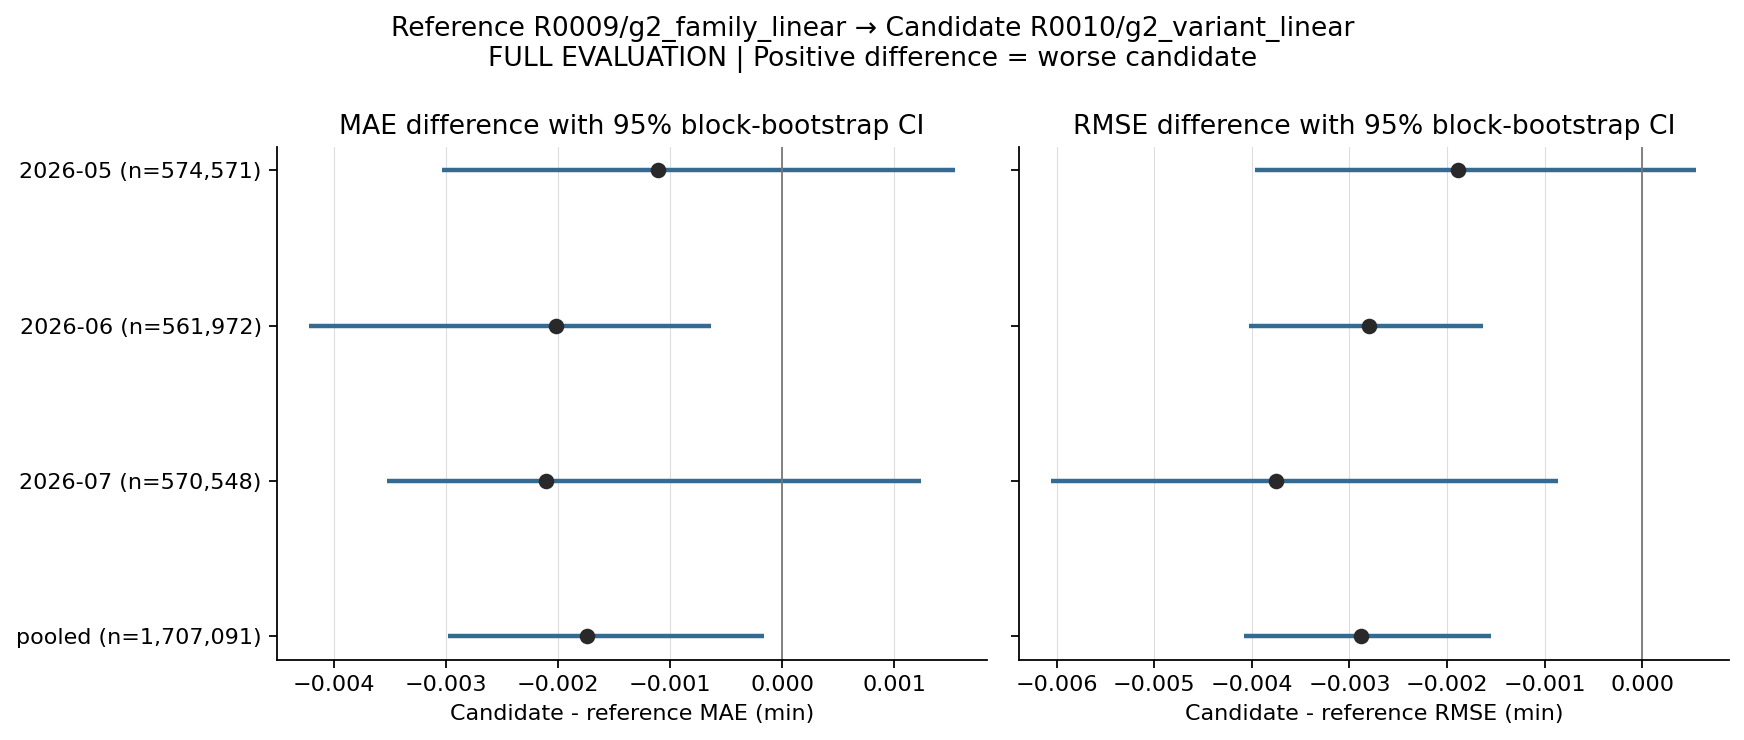

### 模型归档：R0012

运行状态：**completed**。

```json
{
  "feature_group": "G3",
  "model_name": "g3_linear",
  "model_type": "linear",
  "models": [
    "training_mean",
    "training_median",
    "carry_forward",
    "g3_linear"
  ],
  "features": [
    "airport_id",
    "route",
    "downstream_airline",
    "aircraft_family",
    "downstream_distance",
    "downstream_crs_elapsed_time",
    "downstream_day_of_week",
    "downstream_sched_hour",
    "scheduled_turnaround_minutes",
    "upstream_arr_delay_minutes",
    "tail_completed_24h_n",
    "tail_completed_24h_arr_delay_mean",
    "history_window_incomplete",
    "airport_departures_60m_n",
    "airport_departures_60m_delay_mean",
    "airport_planned_departures_next60m_n",
    "airport_planned_arrivals_next60m_n",
    "airport_history_window_incomplete"
  ],
  "categorical_features": [
    "airport_id",
    "route",
    "downstream_airline",
    "aircraft_family"
  ],
  "numeric_features": [
    "downstream_distance",
    "downstream_crs_elapsed_time",
    "downstream_day_of_week",
    "downstream_sched_hour",
    "scheduled_turnaround_minutes",
    "upstream_arr_delay_minutes",
    "tail_completed_24h_n",
    "tail_completed_24h_arr_delay_mean",
    "history_window_incomplete",
    "airport_departures_60m_n",
    "airport_departures_60m_delay_mean",
    "airport_planned_departures_next60m_n",
    "airport_planned_arrivals_next60m_n",
    "airport_history_window_incomplete"
  ],
  "model_params": {
    "copy_X": true,
    "fit_intercept": true,
    "n_jobs": 8,
    "positive": false,
    "tol": 1e-06
  },
  "effective_preprocessing": {
    "min_frequency": 20,
    "drop": "first",
    "sparse": true,
    "categorical_imputation": "constant __MISSING__; keep_empty_features=True",
    "numeric_imputation": "median; add_indicator=True; keep_empty_features=True",
    "numeric_scaling": "StandardScaler(with_mean=False), fixed across algorithms",
    "unknown_categories": "infrequent_if_exist"
  },
  "evaluation_rows": 1707091,
  "evaluation_ids_sha256": "db4e500797d62152fece891a62b9c171822e97e4dea76ab92efd587bcfa8d68c",
  "split_sha256": "4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018967420e7e24441a593"
}
```

**[metrics.csv](../experiments/runs/R0012/metrics.csv)**：完整表 6,644 行；当前条件 16 行。

,model,fold,group,value,n,mae,rmse,target_ge15_share,unit,absolute_error_sum,squared_error_sum,target_ge15_n
0,training_mean,2026-05,all,all,574571,17.969705,43.443239,0.207785,minutes,1.032487e+07,1.084396e+09,119387
411,training_median,2026-05,all,all,574571,13.209259,45.383891,0.207785,minutes,7.589657e+06,1.183442e+09,119387
822,carry_forward,2026-05,all,all,574571,14.173169,49.267137,0.207785,minutes,8.143492e+06,1.394628e+09,119387
1233,g3_linear,2026-05,all,all,574571,14.783665,40.398414,0.207785,minutes,8.494265e+06,9.377182e+08,119387
1644,training_mean,2026-06,all,all,561972,21.068890,50.817858,0.247952,minutes,1.184013e+07,1.451267e+09,139342
2059,training_median,2026-06,all,all,561972,16.995806,53.396380,0.247952,minutes,9.551167e+06,1.602280e+09,139342
2474,carry_forward,2026-06,all,all,561972,17.543874,56.830990,0.247952,minutes,9.859166e+06,1.815035e+09,139342
2889,g3_linear,2026-06,all,all,561972,17.361479,46.496505,0.247952,minutes,9.756665e+06,1.214941e+09,139342
3304,training_mean,2026-07,all,all,570548,23.718273,57.589119,0.272265,minutes,1.353241e+07,1.892226e+09,155340
3720,training_median,2026-07,all,all,570548,19.678702,60.592404,0.272265,minutes,1.122764e+07,2.094732e+09,155340


**[comparison_metrics.csv](../experiments/runs/R0012/comparison/comparison_metrics.csv)**：完整表 8 行；当前条件 8 行。

,scope,metric,n,calendar_dates,reference_error,candidate_error,difference_candidate_minus_reference,ci95_low,ci95_high,valid_bootstrap_repeats,unit,sample_scope
0,2026-05,mae,574571,31,14.782844,14.783665,0.000821,-0.025354,0.026625,1000,minutes,full_evaluation
1,2026-05,rmse,574571,31,40.418944,40.398414,-0.020529,-0.028052,-0.013365,1000,minutes,full_evaluation
2,2026-06,mae,561972,30,17.345149,17.361479,0.016330,0.004493,0.045028,1000,minutes,full_evaluation
3,2026-06,rmse,561972,30,46.536036,46.496505,-0.039531,-0.057673,-0.030025,1000,minutes,full_evaluation
4,2026-07,mae,570548,31,19.637015,19.712415,0.075400,0.064050,0.093966,1000,minutes,full_evaluation
5,2026-07,rmse,570548,31,53.040538,53.002527,-0.038011,-0.053547,-0.028148,1000,minutes,full_evaluation
6,pooled,mae,1707091,92,17.248724,17.279576,0.030852,0.008841,0.052244,1000,minutes,full_evaluation
7,pooled,rmse,1707091,92,46.936626,46.903417,-0.033208,-0.043025,-0.025057,1000,minutes,full_evaluation


**[comparison.json](../experiments/runs/R0012/comparison/comparison.json)**

```json
{
  "reference_run": "R0009",
  "candidate_run": "R0012",
  "reference_model": "g2_family_linear",
  "candidate_model": "g3_linear",
  "parent_run_id": "R0009",
  "candidate_declared_parent": "R0009",
  "comparison_purpose": null,
  "align_rows": false,
  "candidate_status_at_comparison": "running",
  "allow_running_candidate": true,
  "evaluation_ids_sha256": "db4e500797d62152fece891a62b9c171822e97e4dea76ab92efd587bcfa8d68c",
  "split_sha256": "4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018967420e7e24441a593",
  "sample_scope": "full_evaluation",
  "full_evaluation_n": 1707091,
  "compared_n": 1707091,
  "compared_identity_set_sha256": "cb539627cfec0128f2fd808ee86124ee174250e0246c8054e7372968c8a56506",
  "common_sample_columns": null,
  "difference_definition": "candidate minus reference; positive is worse",
  "bootstrap": {
    "method": "paired non-circular moving UTC date blocks",
    "block_days": 7,
    "repeats": 1000,
    "seed": 42,
    "confidence_level": 0.95,
    "full_calendar": "2026-05-01 through 2026-07-31 UTC, including zero-sample dates",
    "monthly_intervals": "resample each monthly calendar separately",
    "pooled_interval": "resample the full validation calendar; blocks never cross date gaps",
    "empty_resamples": "Exclude only bootstrap replicates with sampled n=0; valid replicate counts are reported; no prediction rows are dropped",
    "weighting": "sum AE / sum n; sqrt(sum SE / sum n); same sampled dates for both models"
  },
  "interpretation": "Paired sampling uncertainty, not causal evidence; explicit subsets are supplementary comparisons",
  "outputs": [
    "comparison_daily_stats.csv",
    "comparison_metrics.csv",
    "comparison_error_differences.png",
    "comparison.json"
  ]
}
```

**[comparison_error_differences.png](../experiments/runs/R0012/comparison/comparison_error_differences.png)**

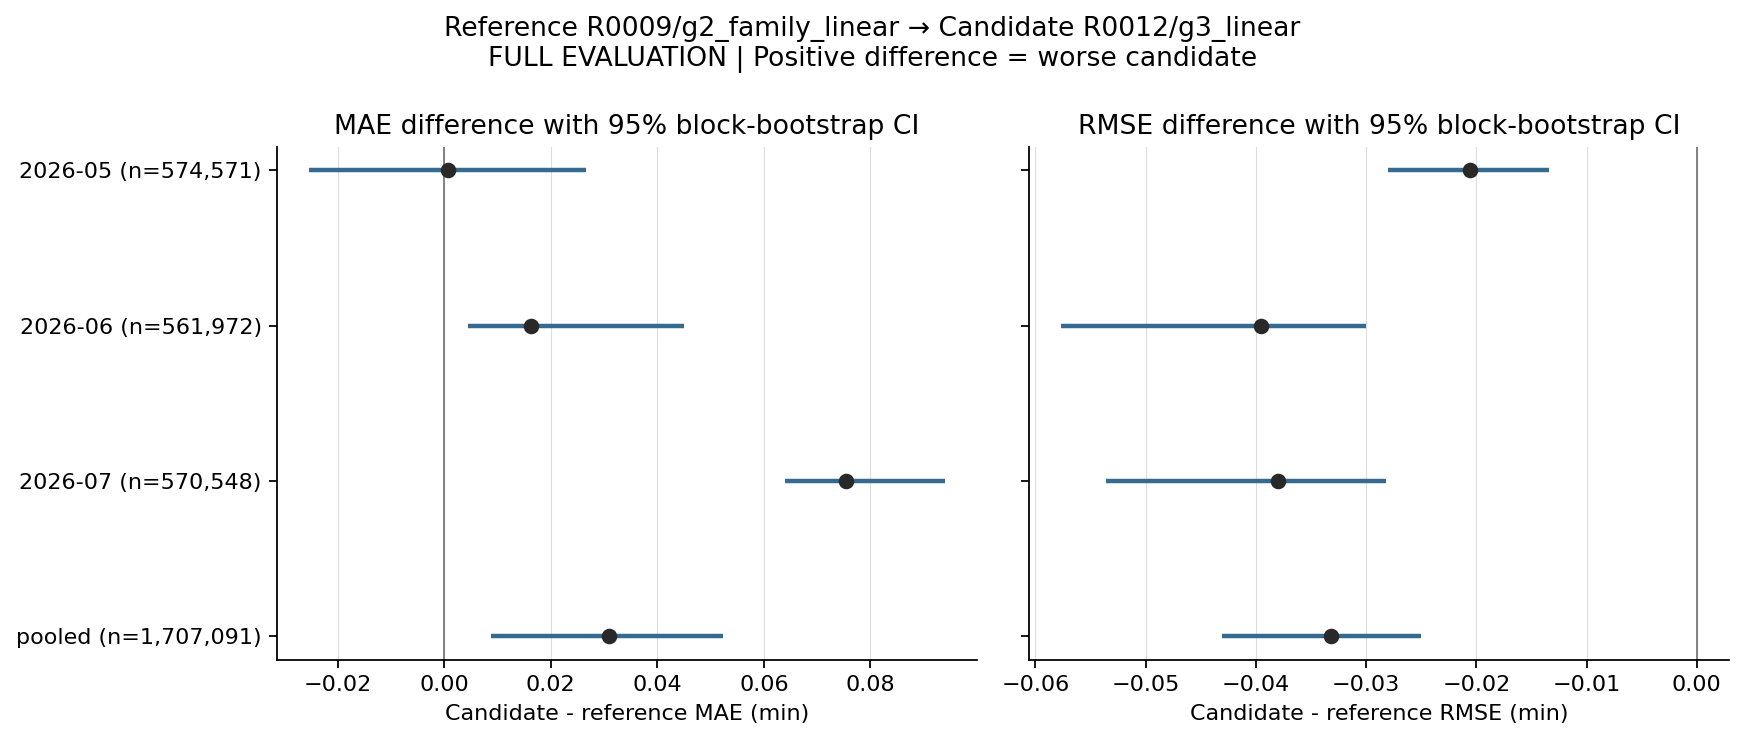

### 模型归档：R0015

运行状态：**completed**。

```json
{
  "feature_group": "G4A",
  "model_name": "g4a_linear",
  "model_type": "linear",
  "models": [
    "training_mean",
    "training_median",
    "carry_forward",
    "g4a_linear"
  ],
  "features": [
    "airport_id",
    "route",
    "downstream_airline",
    "aircraft_family",
    "downstream_distance",
    "downstream_crs_elapsed_time",
    "downstream_day_of_week",
    "downstream_sched_hour",
    "scheduled_turnaround_minutes",
    "upstream_arr_delay_minutes",
    "tail_completed_24h_n",
    "tail_completed_24h_arr_delay_mean",
    "history_window_incomplete",
    "airport_departures_60m_n",
    "airport_departures_60m_delay_mean",
    "airport_planned_departures_next60m_n",
    "airport_planned_arrivals_next60m_n",
    "airport_history_window_incomplete",
    "metar_wind_knots",
    "metar_gust_knots",
    "metar_visibility_miles",
    "metar_ceiling_ft",
    "metar_precip_amount_in",
    "metar_precip_flag",
    "metar_rain_flag",
    "metar_snow_flag",
    "metar_thunder_flag",
    "metar_age_minutes",
    "metar_missing",
    "metar_sky_reported",
    "metar_ceiling_reported",
    "metar_weather_codes_reported"
  ],
  "categorical_features": [
    "airport_id",
    "route",
    "downstream_airline",
    "aircraft_family"
  ],
  "numeric_features": [
    "downstream_distance",
    "downstream_crs_elapsed_time",
    "downstream_day_of_week",
    "downstream_sched_hour",
    "scheduled_turnaround_minutes",
    "upstream_arr_delay_minutes",
    "tail_completed_24h_n",
    "tail_completed_24h_arr_delay_mean",
    "history_window_incomplete",
    "airport_departures_60m_n",
    "airport_departures_60m_delay_mean",
    "airport_planned_departures_next60m_n",
    "airport_planned_arrivals_next60m_n",
    "airport_history_window_incomplete",
    "metar_wind_knots",
    "metar_gust_knots",
    "metar_visibility_miles",
    "metar_ceiling_ft",
    "metar_precip_amount_in",
    "metar_precip_flag",
    "metar_rain_flag",
    "metar_snow_flag",
    "metar_thunder_flag",
    "metar_age_minutes",
    "metar_missing",
    "metar_sky_reported",
    "metar_ceiling_reported",
    "metar_weather_codes_reported"
  ],
  "model_params": {
    "copy_X": true,
    "fit_intercept": true,
    "n_jobs": 8,
    "positive": false,
    "tol": 1e-06
  },
  "effective_preprocessing": {
    "min_frequency": 20,
    "drop": "first",
    "sparse": true,
    "categorical_imputation": "constant __MISSING__; keep_empty_features=True",
    "numeric_imputation": "median; add_indicator=True; keep_empty_features=True",
    "numeric_scaling": "StandardScaler(with_mean=False), fixed across algorithms",
    "unknown_categories": "infrequent_if_exist"
  },
  "evaluation_rows": 1707091,
  "evaluation_ids_sha256": "db4e500797d62152fece891a62b9c171822e97e4dea76ab92efd587bcfa8d68c",
  "split_sha256": "4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018967420e7e24441a593"
}
```

**[metrics.csv](../experiments/runs/R0015/metrics.csv)**：完整表 6,644 行；当前条件 16 行。

,model,fold,group,value,n,mae,rmse,target_ge15_share,unit,absolute_error_sum,squared_error_sum,target_ge15_n
0,training_mean,2026-05,all,all,574571,17.969705,43.443239,0.207785,minutes,1.032487e+07,1.084396e+09,119387
411,training_median,2026-05,all,all,574571,13.209259,45.383891,0.207785,minutes,7.589657e+06,1.183442e+09,119387
822,carry_forward,2026-05,all,all,574571,14.173169,49.267137,0.207785,minutes,8.143492e+06,1.394628e+09,119387
1233,g4a_linear,2026-05,all,all,574571,14.730302,40.372480,0.207785,minutes,8.463604e+06,9.365146e+08,119387
1644,training_mean,2026-06,all,all,561972,21.068890,50.817858,0.247952,minutes,1.184013e+07,1.451267e+09,139342
2059,training_median,2026-06,all,all,561972,16.995806,53.396380,0.247952,minutes,9.551167e+06,1.602280e+09,139342
2474,carry_forward,2026-06,all,all,561972,17.543874,56.830990,0.247952,minutes,9.859166e+06,1.815035e+09,139342
2889,g4a_linear,2026-06,all,all,561972,17.296282,46.459273,0.247952,minutes,9.720026e+06,1.212996e+09,139342
3304,training_mean,2026-07,all,all,570548,23.718273,57.589119,0.272265,minutes,1.353241e+07,1.892226e+09,155340
3720,training_median,2026-07,all,all,570548,19.678702,60.592404,0.272265,minutes,1.122764e+07,2.094732e+09,155340


**[comparison_metrics.csv](../experiments/runs/R0015/comparison/comparison_metrics.csv)**：完整表 8 行；当前条件 8 行。

,scope,metric,n,calendar_dates,reference_error,candidate_error,difference_candidate_minus_reference,ci95_low,ci95_high,valid_bootstrap_repeats,unit,sample_scope
0,2026-05,mae,574571,31,14.783665,14.730302,-0.053364,-0.078559,-0.005128,1000,minutes,full_evaluation
1,2026-05,rmse,574571,31,40.398414,40.372480,-0.025934,-0.036052,-0.013105,1000,minutes,full_evaluation
2,2026-06,mae,561972,30,17.361479,17.296282,-0.065197,-0.076960,-0.043536,1000,minutes,full_evaluation
3,2026-06,rmse,561972,30,46.496505,46.459273,-0.037231,-0.047703,-0.030827,1000,minutes,full_evaluation
4,2026-07,mae,570548,31,19.712415,19.633615,-0.078799,-0.085065,-0.065530,1000,minutes,full_evaluation
5,2026-07,rmse,570548,31,53.002527,52.948493,-0.054034,-0.081794,-0.033413,1000,minutes,full_evaluation
6,pooled,mae,1707091,92,17.279576,17.213816,-0.065760,-0.078964,-0.047485,1000,minutes,full_evaluation
7,pooled,rmse,1707091,92,46.903417,46.863342,-0.040076,-0.053456,-0.029436,1000,minutes,full_evaluation


**[comparison.json](../experiments/runs/R0015/comparison/comparison.json)**

```json
{
  "reference_run": "R0012",
  "candidate_run": "R0015",
  "reference_model": "g3_linear",
  "candidate_model": "g4a_linear",
  "parent_run_id": "R0012",
  "candidate_declared_parent": "R0012",
  "comparison_purpose": null,
  "align_rows": false,
  "candidate_status_at_comparison": "running",
  "allow_running_candidate": true,
  "evaluation_ids_sha256": "db4e500797d62152fece891a62b9c171822e97e4dea76ab92efd587bcfa8d68c",
  "split_sha256": "4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018967420e7e24441a593",
  "sample_scope": "full_evaluation",
  "full_evaluation_n": 1707091,
  "compared_n": 1707091,
  "compared_identity_set_sha256": "cb539627cfec0128f2fd808ee86124ee174250e0246c8054e7372968c8a56506",
  "common_sample_columns": null,
  "difference_definition": "candidate minus reference; positive is worse",
  "bootstrap": {
    "method": "paired non-circular moving UTC date blocks",
    "block_days": 7,
    "repeats": 1000,
    "seed": 42,
    "confidence_level": 0.95,
    "full_calendar": "2026-05-01 through 2026-07-31 UTC, including zero-sample dates",
    "monthly_intervals": "resample each monthly calendar separately",
    "pooled_interval": "resample the full validation calendar; blocks never cross date gaps",
    "empty_resamples": "Exclude only bootstrap replicates with sampled n=0; valid replicate counts are reported; no prediction rows are dropped",
    "weighting": "sum AE / sum n; sqrt(sum SE / sum n); same sampled dates for both models"
  },
  "interpretation": "Paired sampling uncertainty, not causal evidence; explicit subsets are supplementary comparisons",
  "outputs": [
    "comparison_daily_stats.csv",
    "comparison_metrics.csv",
    "comparison_error_differences.png",
    "comparison.json"
  ]
}
```

**[comparison_error_differences.png](../experiments/runs/R0015/comparison/comparison_error_differences.png)**

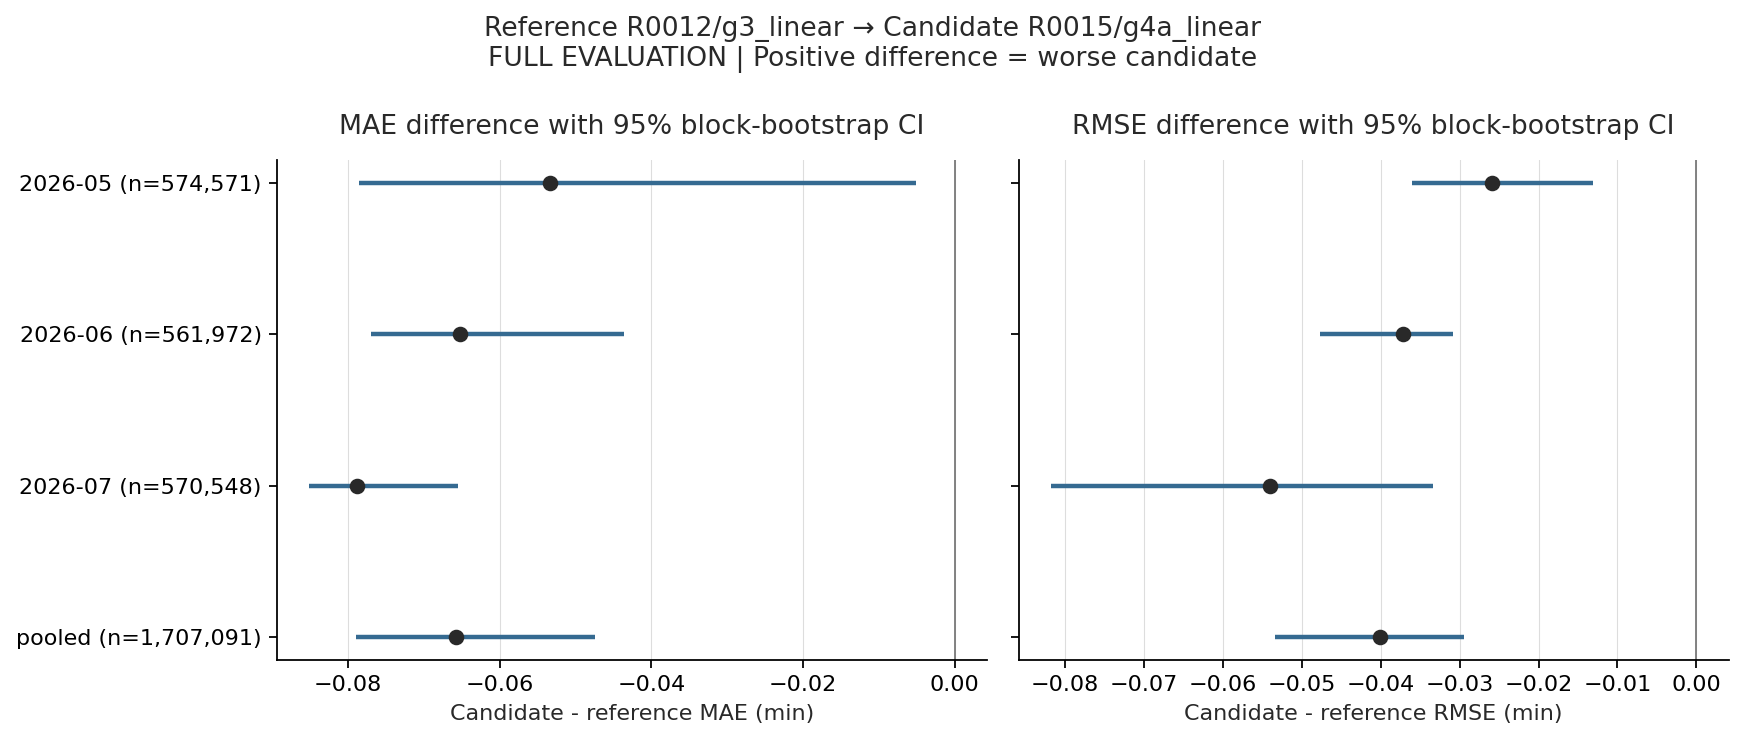

### 模型归档：R0017

运行状态：**completed**。

```json
{
  "feature_group": "G4B",
  "model_name": "g4b_linear",
  "model_type": "linear",
  "models": [
    "training_mean",
    "training_median",
    "carry_forward",
    "g4b_linear"
  ],
  "features": [
    "airport_id",
    "route",
    "downstream_airline",
    "aircraft_family",
    "downstream_distance",
    "downstream_crs_elapsed_time",
    "downstream_day_of_week",
    "downstream_sched_hour",
    "scheduled_turnaround_minutes",
    "upstream_arr_delay_minutes",
    "tail_completed_24h_n",
    "tail_completed_24h_arr_delay_mean",
    "history_window_incomplete",
    "airport_departures_60m_n",
    "airport_departures_60m_delay_mean",
    "airport_planned_departures_next60m_n",
    "airport_planned_arrivals_next60m_n",
    "airport_history_window_incomplete",
    "metar_wind_knots",
    "metar_gust_knots",
    "metar_visibility_miles",
    "metar_ceiling_ft",
    "metar_precip_amount_in",
    "metar_precip_flag",
    "metar_rain_flag",
    "metar_snow_flag",
    "metar_thunder_flag",
    "metar_age_minutes",
    "metar_missing",
    "metar_sky_reported",
    "metar_ceiling_reported",
    "metar_weather_codes_reported",
    "taf_bulletin_age_minutes",
    "taf_lead_minutes",
    "taf_missing",
    "taf_prevailing_wind_knots",
    "taf_prevailing_gust_knots",
    "taf_prevailing_visibility_miles",
    "taf_prevailing_ceiling_ft",
    "taf_prevailing_precip_flag",
    "taf_prevailing_rain_flag",
    "taf_prevailing_snow_flag",
    "taf_prevailing_thunder_flag",
    "taf_prevailing_segment_count",
    "taf_prevailing_missing",
    "taf_tempo_wind_knots",
    "taf_tempo_gust_knots",
    "taf_tempo_visibility_miles",
    "taf_tempo_ceiling_ft",
    "taf_tempo_precip_flag",
    "taf_tempo_rain_flag",
    "taf_tempo_snow_flag",
    "taf_tempo_thunder_flag",
    "taf_tempo_segment_count",
    "taf_tempo_missing",
    "taf_probability_wind_knots",
    "taf_probability_gust_knots",
    "taf_probability_visibility_miles",
    "taf_probability_ceiling_ft",
    "taf_probability_precip_flag",
    "taf_probability_rain_flag",
    "taf_probability_snow_flag",
    "taf_probability_thunder_flag",
    "taf_probability_segment_count",
    "taf_probability_missing"
  ],
  "categorical_features": [
    "airport_id",
    "route",
    "downstream_airline",
    "aircraft_family"
  ],
  "numeric_features": [
    "downstream_distance",
    "downstream_crs_elapsed_time",
    "downstream_day_of_week",
    "downstream_sched_hour",
    "scheduled_turnaround_minutes",
    "upstream_arr_delay_minutes",
    "tail_completed_24h_n",
    "tail_completed_24h_arr_delay_mean",
    "history_window_incomplete",
    "airport_departures_60m_n",
    "airport_departures_60m_delay_mean",
    "airport_planned_departures_next60m_n",
    "airport_planned_arrivals_next60m_n",
    "airport_history_window_incomplete",
    "metar_wind_knots",
    "metar_gust_knots",
    "metar_visibility_miles",
    "metar_ceiling_ft",
    "metar_precip_amount_in",
    "metar_precip_flag",
    "metar_rain_flag",
    "metar_snow_flag",
    "metar_thunder_flag",
    "metar_age_minutes",
    "metar_missing",
    "metar_sky_reported",
    "metar_ceiling_reported",
    "metar_weather_codes_reported",
    "taf_bulletin_age_minutes",
    "taf_lead_minutes",
    "taf_missing",
    "taf_prevailing_wind_knots",
    "taf_prevailing_gust_knots",
    "taf_prevailing_visibility_miles",
    "taf_prevailing_ceiling_ft",
    "taf_prevailing_precip_flag",
    "taf_prevailing_rain_flag",
    "taf_prevailing_snow_flag",
    "taf_prevailing_thunder_flag",
    "taf_prevailing_segment_count",
    "taf_prevailing_missing",
    "taf_tempo_wind_knots",
    "taf_tempo_gust_knots",
    "taf_tempo_visibility_miles",
    "taf_tempo_ceiling_ft",
    "taf_tempo_precip_flag",
    "taf_tempo_rain_flag",
    "taf_tempo_snow_flag",
    "taf_tempo_thunder_flag",
    "taf_tempo_segment_count",
    "taf_tempo_missing",
    "taf_probability_wind_knots",
    "taf_probability_gust_knots",
    "taf_probability_visibility_miles",
    "taf_probability_ceiling_ft",
    "taf_probability_precip_flag",
    "taf_probability_rain_flag",
    "taf_probability_snow_flag",
    "taf_probability_thunder_flag",
    "taf_probability_segment_count",
    "taf_probability_missing"
  ],
  "model_params": {
    "copy_X": true,
    "fit_intercept": true,
    "n_jobs": 8,
    "positive": false,
    "tol": 1e-06
  },
  "effective_preprocessing": {
    "min_frequency": 20,
    "drop": "first",
    "sparse": true,
    "categorical_imputation": "constant __MISSING__; keep_empty_features=True",
    "numeric_imputation": "median; add_indicator=True; keep_empty_features=True",
    "numeric_scaling": "StandardScaler(with_mean=False), fixed across algorithms",
    "unknown_categories": "infrequent_if_exist"
  },
  "evaluation_rows": 1707091,
  "evaluation_ids_sha256": "db4e500797d62152fece891a62b9c171822e97e4dea76ab92efd587bcfa8d68c",
  "split_sha256": "4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018967420e7e24441a593"
}
```

**[metrics.csv](../experiments/runs/R0017/metrics.csv)**：完整表 6,644 行；当前条件 16 行。

,model,fold,group,value,n,mae,rmse,target_ge15_share,unit,absolute_error_sum,squared_error_sum,target_ge15_n
0,training_mean,2026-05,all,all,574571,17.969705,43.443239,0.207785,minutes,1.032487e+07,1.084396e+09,119387
411,training_median,2026-05,all,all,574571,13.209259,45.383891,0.207785,minutes,7.589657e+06,1.183442e+09,119387
822,carry_forward,2026-05,all,all,574571,14.173169,49.267137,0.207785,minutes,8.143492e+06,1.394628e+09,119387
1233,g4b_linear,2026-05,all,all,574571,14.719032,38.936825,0.207785,minutes,8.457129e+06,8.710935e+08,119387
1644,training_mean,2026-06,all,all,561972,21.068890,50.817858,0.247952,minutes,1.184013e+07,1.451267e+09,139342
2059,training_median,2026-06,all,all,561972,16.995806,53.396380,0.247952,minutes,9.551167e+06,1.602280e+09,139342
2474,carry_forward,2026-06,all,all,561972,17.543874,56.830990,0.247952,minutes,9.859166e+06,1.815035e+09,139342
2889,g4b_linear,2026-06,all,all,561972,16.873523,44.323499,0.247952,minutes,9.482447e+06,1.104035e+09,139342
3304,training_mean,2026-07,all,all,570548,23.718273,57.589119,0.272265,minutes,1.353241e+07,1.892226e+09,155340
3720,training_median,2026-07,all,all,570548,19.678702,60.592404,0.272265,minutes,1.122764e+07,2.094732e+09,155340


...

**[comparison.json](../experiments/runs/R0017/common_weather/G4a_to_G4b/comparison.json)**

```json
{
  "reference_run": "R0015",
  "candidate_run": "R0017",
  "reference_model": "g4a_linear",
  "candidate_model": "g4b_linear",
  "parent_run_id": "R0015",
  "candidate_declared_parent": "R0015",
  "comparison_purpose": "Preregistered common IEM METAR source and TAF prevailing availability subset; no refitting",
  "align_rows": false,
  "candidate_status_at_comparison": "running",
  "allow_running_candidate": true,
  "evaluation_ids_sha256": "db4e500797d62152fece891a62b9c171822e97e4dea76ab92efd587bcfa8d68c",
  "split_sha256": "4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018967420e7e24441a593",
  "sample_scope": "explicit_subset",
  "full_evaluation_n": 1707091,
  "compared_n": 1017112,
  "compared_identity_set_sha256": "f60b5dbb159488b14d3c2d2f4c592e36d24899de9701cd232a53706dd58699a3",
  "common_sample_columns": null,
  "difference_definition": "candidate minus reference; positive is worse",
  "bootstrap": {
    "method": "paired non-circular moving UTC date blocks",
    "block_days": 7,
    "repeats": 1000,
    "seed": 42,
    "confidence_level": 0.95,
    "full_calendar": "2026-05-01 through 2026-07-31 UTC, including zero-sample dates",
    "monthly_intervals": "resample each monthly calendar separately",
    "pooled_interval": "resample the full validation calendar; blocks never cross date gaps",
    "empty_resamples": "Exclude only bootstrap replicates with sampled n=0; valid replicate counts are reported; no prediction rows are dropped",
    "weighting": "sum AE / sum n; sqrt(sum SE / sum n); same sampled dates for both models"
  },
  "interpretation": "Paired sampling uncertainty, not causal evidence; explicit subsets are supplementary comparisons",
  "outputs": [
    "comparison_daily_stats.csv",
    "comparison_metrics.csv",
    "comparison_error_differences.png",
    "comparison.json",
    "comparison_subset_ids.csv.gz"
  ]
}
```

**[comparison.json](../experiments/runs/R0017/comparison/comparison.json)**

```json
{
  "reference_run": "R0015",
  "candidate_run": "R0017",
  "reference_model": "g4a_linear",
  "candidate_model": "g4b_linear",
  "parent_run_id": "R0015",
  "candidate_declared_parent": "R0015",
  "comparison_purpose": null,
  "align_rows": false,
  "candidate_status_at_comparison": "running",
  "allow_running_candidate": true,
  "evaluation_ids_sha256": "db4e500797d62152fece891a62b9c171822e97e4dea76ab92efd587bcfa8d68c",
  "split_sha256": "4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018967420e7e24441a593",
  "sample_scope": "full_evaluation",
  "full_evaluation_n": 1707091,
  "compared_n": 1707091,
  "compared_identity_set_sha256": "cb539627cfec0128f2fd808ee86124ee174250e0246c8054e7372968c8a56506",
  "common_sample_columns": null,
  "difference_definition": "candidate minus reference; positive is worse",
  "bootstrap": {
    "method": "paired non-circular moving UTC date blocks",
    "block_days": 7,
    "repeats": 1000,
    "seed": 42,
    "confidence_level": 0.95,
    "full_calendar": "2026-05-01 through 2026-07-31 UTC, including zero-sample dates",
    "monthly_intervals": "resample each monthly calendar separately",
    "pooled_interval": "resample the full validation calendar; blocks never cross date gaps",
    "empty_resamples": "Exclude only bootstrap replicates with sampled n=0; valid replicate counts are reported; no prediction rows are dropped",
    "weighting": "sum AE / sum n; sqrt(sum SE / sum n); same sampled dates for both models"
  },
  "interpretation": "Paired sampling uncertainty, not causal evidence; explicit subsets are supplementary comparisons",
  "outputs": [
    "comparison_daily_stats.csv",
    "comparison_metrics.csv",
    "comparison_error_differences.png",
    "comparison.json"
  ]
}
```

**[comparison_error_differences.png](../experiments/runs/R0017/common_weather/G3_to_G4a/comparison_error_differences.png)**

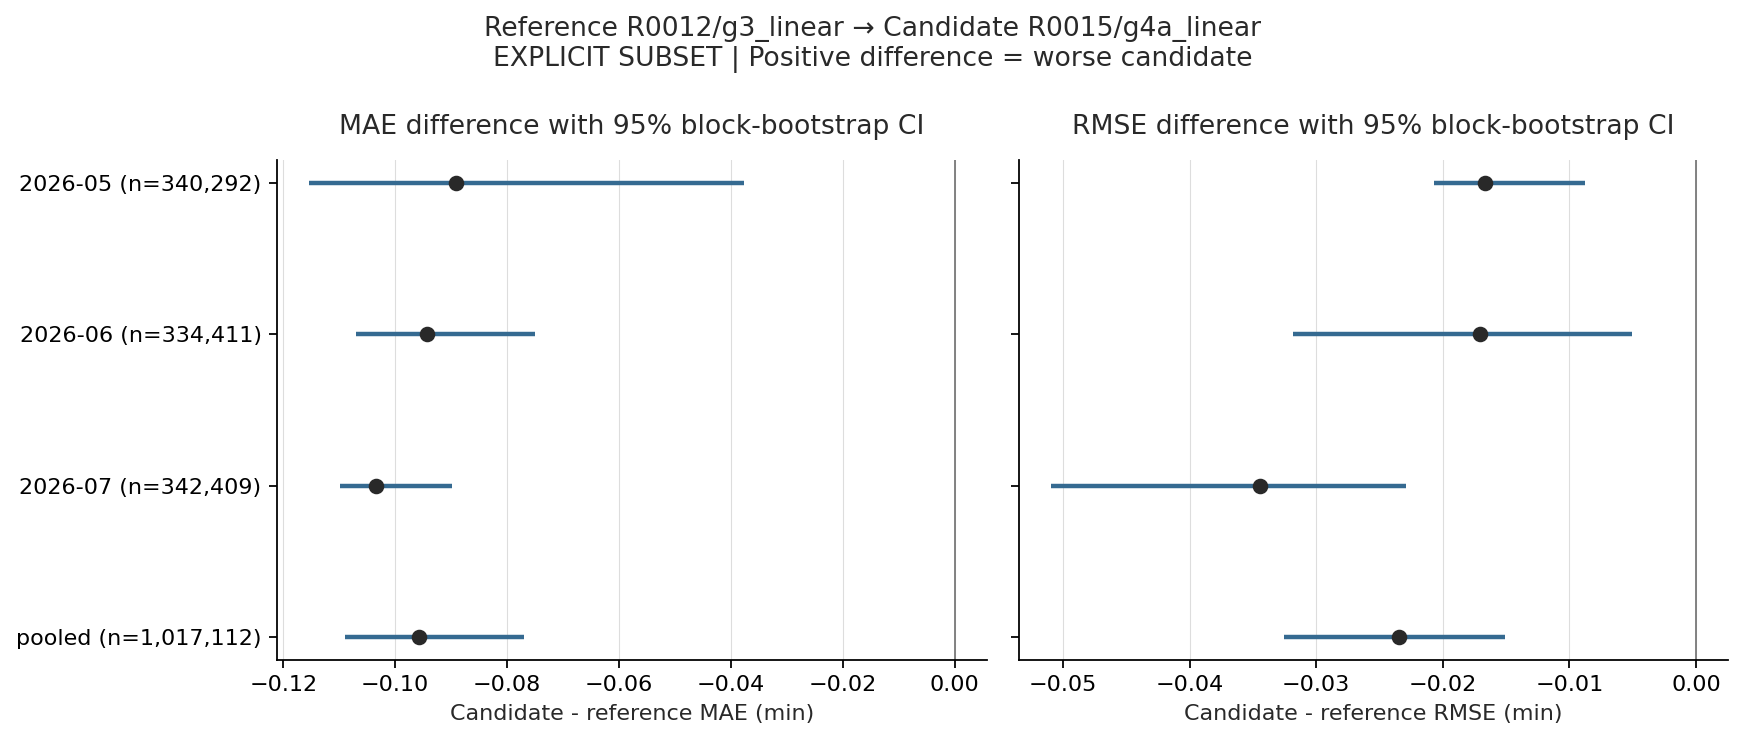

**[comparison_error_differences.png](../experiments/runs/R0017/common_weather/G3_to_G4b/comparison_error_differences.png)**

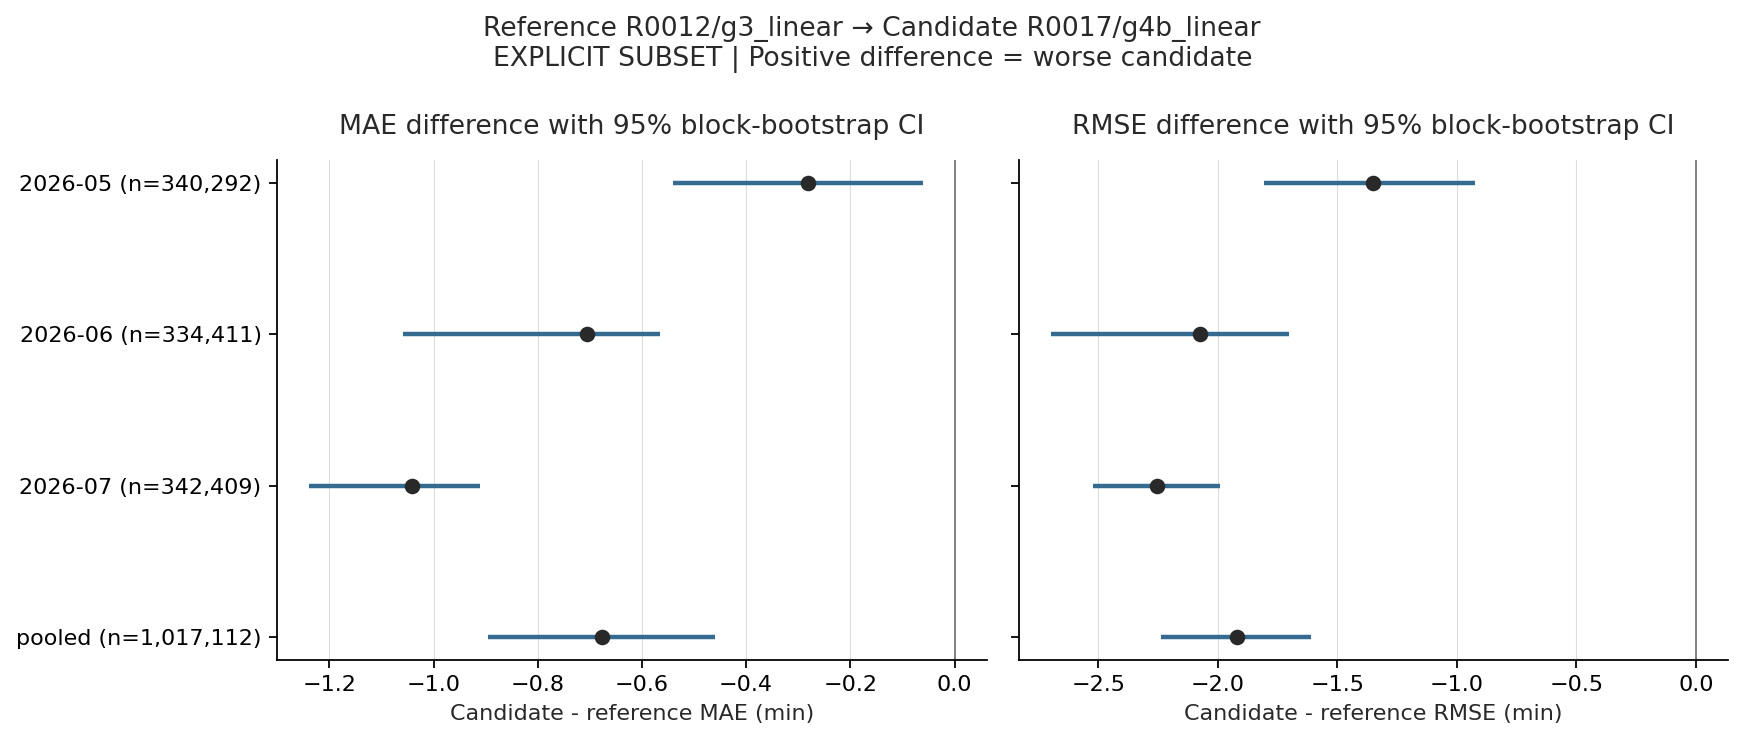

**[comparison_error_differences.png](../experiments/runs/R0017/common_weather/G4a_to_G4b/comparison_error_differences.png)**

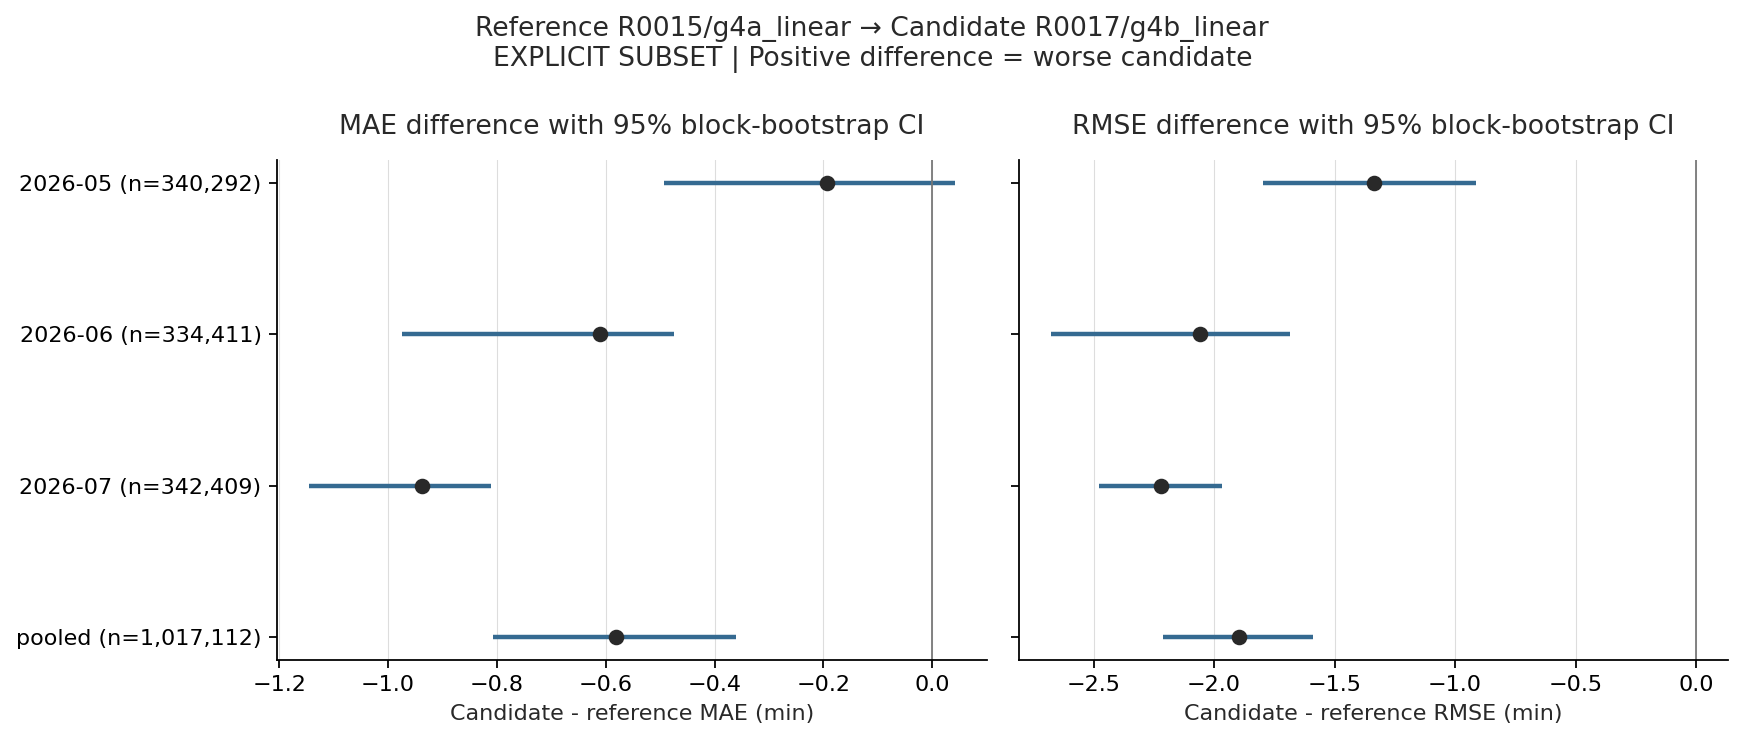

**[comparison_error_differences.png](../experiments/runs/R0017/comparison/comparison_error_differences.png)**

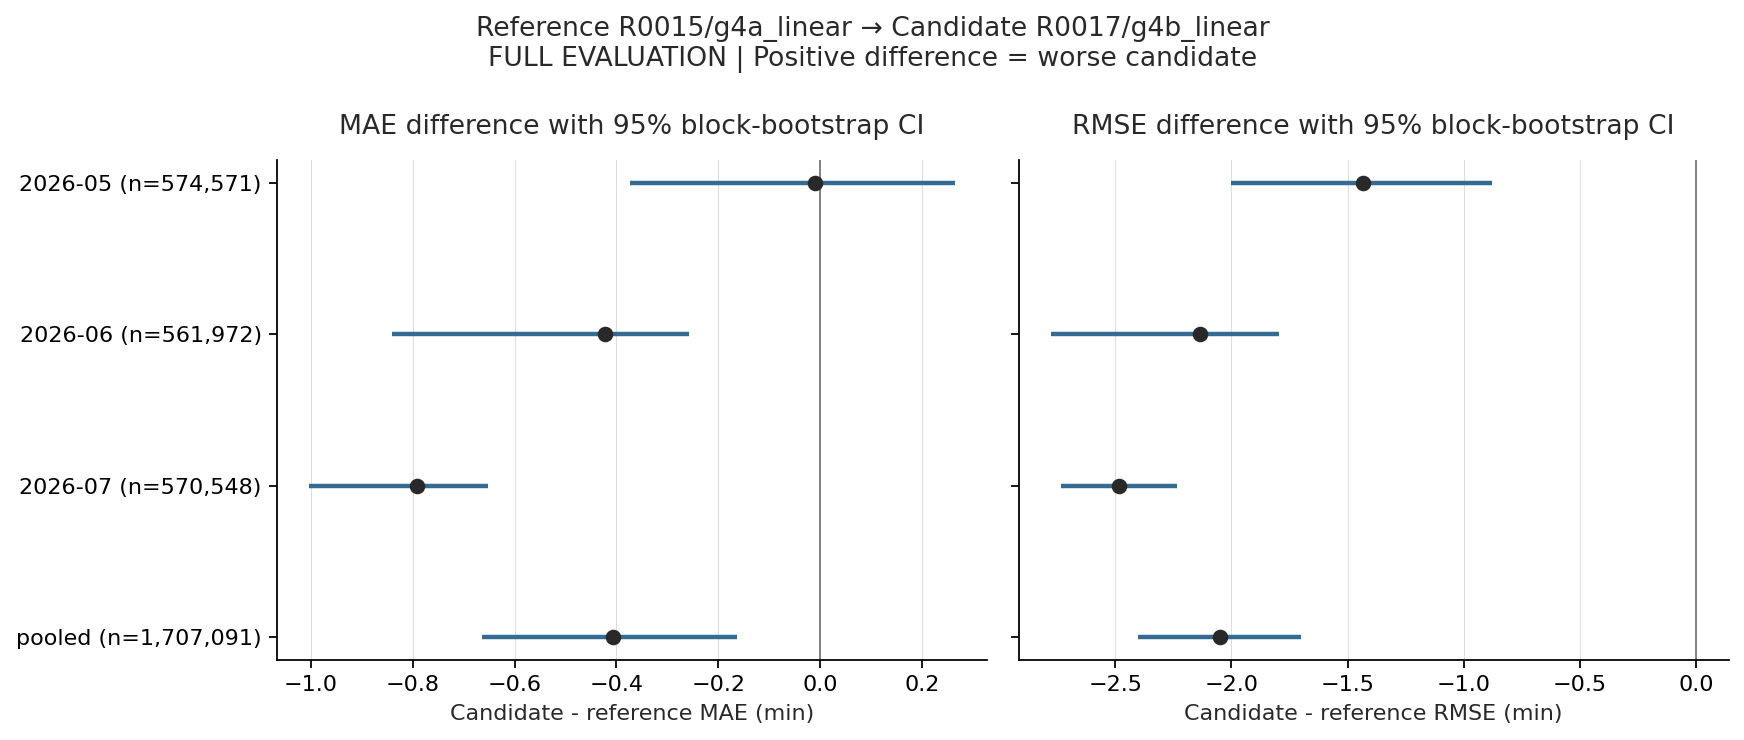

### 模型归档：R0019

运行状态：**completed**。

```json
{
  "feature_group": "G4B",
  "model_name": "g4b_noaa_linear",
  "model_type": "linear",
  "models": [
    "training_mean",
    "training_median",
    "carry_forward",
    "g4b_noaa_linear"
  ],
  "features": [
    "airport_id",
    "route",
    "downstream_airline",
    "aircraft_family",
    "downstream_distance",
    "downstream_crs_elapsed_time",
    "downstream_day_of_week",
    "downstream_sched_hour",
    "scheduled_turnaround_minutes",
    "upstream_arr_delay_minutes",
    "tail_completed_24h_n",
    "tail_completed_24h_arr_delay_mean",
    "history_window_incomplete",
    "airport_departures_60m_n",
    "airport_departures_60m_delay_mean",
    "airport_planned_departures_next60m_n",
    "airport_planned_arrivals_next60m_n",
    "airport_history_window_incomplete",
    "metar_wind_knots",
    "metar_gust_knots",
    "metar_visibility_miles",
    "metar_ceiling_ft",
    "metar_precip_amount_in",
    "metar_precip_flag",
    "metar_rain_flag",
    "metar_snow_flag",
    "metar_thunder_flag",
    "metar_age_minutes",
    "metar_missing",
    "metar_sky_reported",
    "metar_ceiling_reported",
    "metar_weather_codes_reported",
    "taf_bulletin_age_minutes",
    "taf_lead_minutes",
    "taf_missing",
    "taf_prevailing_wind_knots",
    "taf_prevailing_gust_knots",
    "taf_prevailing_visibility_miles",
    "taf_prevailing_ceiling_ft",
    "taf_prevailing_precip_flag",
    "taf_prevailing_rain_flag",
    "taf_prevailing_snow_flag",
    "taf_prevailing_thunder_flag",
    "taf_prevailing_segment_count",
    "taf_prevailing_missing",
    "taf_tempo_wind_knots",
    "taf_tempo_gust_knots",
    "taf_tempo_visibility_miles",
    "taf_tempo_ceiling_ft",
    "taf_tempo_precip_flag",
    "taf_tempo_rain_flag",
    "taf_tempo_snow_flag",
    "taf_tempo_thunder_flag",
    "taf_tempo_segment_count",
    "taf_tempo_missing",
    "taf_probability_wind_knots",
    "taf_probability_gust_knots",
    "taf_probability_visibility_miles",
    "taf_probability_ceiling_ft",
    "taf_probability_precip_flag",
    "taf_probability_rain_flag",
    "taf_probability_snow_flag",
    "taf_probability_thunder_flag",
    "taf_probability_segment_count",
    "taf_probability_missing"
  ],
  "categorical_features": [
    "airport_id",
    "route",
    "downstream_airline",
    "aircraft_family"
  ],
  "numeric_features": [
    "downstream_distance",
    "downstream_crs_elapsed_time",
    "downstream_day_of_week",
    "downstream_sched_hour",
    "scheduled_turnaround_minutes",
    "upstream_arr_delay_minutes",
    "tail_completed_24h_n",
    "tail_completed_24h_arr_delay_mean",
    "history_window_incomplete",
    "airport_departures_60m_n",
    "airport_departures_60m_delay_mean",
    "airport_planned_departures_next60m_n",
    "airport_planned_arrivals_next60m_n",
    "airport_history_window_incomplete",
    "metar_wind_knots",
    "metar_gust_knots",
    "metar_visibility_miles",
    "metar_ceiling_ft",
    "metar_precip_amount_in",
    "metar_precip_flag",
    "metar_rain_flag",
    "metar_snow_flag",
    "metar_thunder_flag",
    "metar_age_minutes",
    "metar_missing",
    "metar_sky_reported",
    "metar_ceiling_reported",
    "metar_weather_codes_reported",
    "taf_bulletin_age_minutes",
    "taf_lead_minutes",
    "taf_missing",
    "taf_prevailing_wind_knots",
    "taf_prevailing_gust_knots",
    "taf_prevailing_visibility_miles",
    "taf_prevailing_ceiling_ft",
    "taf_prevailing_precip_flag",
    "taf_prevailing_rain_flag",
    "taf_prevailing_snow_flag",
    "taf_prevailing_thunder_flag",
    "taf_prevailing_segment_count",
    "taf_prevailing_missing",
    "taf_tempo_wind_knots",
    "taf_tempo_gust_knots",
    "taf_tempo_visibility_miles",
    "taf_tempo_ceiling_ft",
    "taf_tempo_precip_flag",
    "taf_tempo_rain_flag",
    "taf_tempo_snow_flag",
    "taf_tempo_thunder_flag",
    "taf_tempo_segment_count",
    "taf_tempo_missing",
    "taf_probability_wind_knots",
    "taf_probability_gust_knots",
    "taf_probability_visibility_miles",
    "taf_probability_ceiling_ft",
    "taf_probability_precip_flag",
    "taf_probability_rain_flag",
    "taf_probability_snow_flag",
    "taf_probability_thunder_flag",
    "taf_probability_segment_count",
    "taf_probability_missing"
  ],
  "model_params": {
    "copy_X": true,
    "fit_intercept": true,
    "n_jobs": 8,
    "positive": false,
    "tol": 1e-06
  },
  "effective_preprocessing": {
    "min_frequency": 20,
    "drop": "first",
    "sparse": true,
    "categorical_imputation": "constant __MISSING__; keep_empty_features=True",
    "numeric_imputation": "median; add_indicator=True; keep_empty_features=True",
    "numeric_scaling": "StandardScaler(with_mean=False), fixed across algorithms",
    "unknown_categories": "infrequent_if_exist"
  },
  "evaluation_rows": 1707091,
  "evaluation_ids_sha256": "db4e500797d62152fece891a62b9c171822e97e4dea76ab92efd587bcfa8d68c",
  "split_sha256": "4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018967420e7e24441a593"
}
```

**[metrics.csv](../experiments/runs/R0019/metrics.csv)**：完整表 6,644 行；当前条件 16 行。

,model,fold,group,value,n,mae,rmse,target_ge15_share,unit,absolute_error_sum,squared_error_sum,target_ge15_n
0,training_mean,2026-05,all,all,574571,17.969705,43.443239,0.207785,minutes,1.032487e+07,1.084396e+09,119387
411,training_median,2026-05,all,all,574571,13.209259,45.383891,0.207785,minutes,7.589657e+06,1.183442e+09,119387
822,carry_forward,2026-05,all,all,574571,14.173169,49.267137,0.207785,minutes,8.143492e+06,1.394628e+09,119387
1233,g4b_noaa_linear,2026-05,all,all,574571,14.719032,38.936825,0.207785,minutes,8.457129e+06,8.710935e+08,119387
1644,training_mean,2026-06,all,all,561972,21.068890,50.817858,0.247952,minutes,1.184013e+07,1.451267e+09,139342
2059,training_median,2026-06,all,all,561972,16.995806,53.396380,0.247952,minutes,9.551167e+06,1.602280e+09,139342
2474,carry_forward,2026-06,all,all,561972,17.543874,56.830990,0.247952,minutes,9.859166e+06,1.815035e+09,139342
2889,g4b_noaa_linear,2026-06,all,all,561972,16.873523,44.323499,0.247952,minutes,9.482447e+06,1.104035e+09,139342
3304,training_mean,2026-07,all,all,570548,23.718273,57.589119,0.272265,minutes,1.353241e+07,1.892226e+09,155340
3720,training_median,2026-07,all,all,570548,19.678702,60.592404,0.272265,minutes,1.122764e+07,2.094732e+09,155340


**[comparison_metrics.csv](../experiments/runs/R0019/comparison/comparison_metrics.csv)**：完整表 8 行；当前条件 8 行。

,scope,metric,n,calendar_dates,reference_error,candidate_error,difference_candidate_minus_reference,ci95_low,ci95_high,valid_bootstrap_repeats,unit,sample_scope
0,2026-05,mae,574571,31,14.719032,14.719032,0.0,0.0,0.0,1000,minutes,full_evaluation
1,2026-05,rmse,574571,31,38.936825,38.936825,0.0,0.0,0.0,1000,minutes,full_evaluation
2,2026-06,mae,561972,30,16.873523,16.873523,0.0,0.0,0.0,1000,minutes,full_evaluation
3,2026-06,rmse,561972,30,44.323499,44.323499,0.0,0.0,0.0,1000,minutes,full_evaluation
4,2026-07,mae,570548,31,18.842982,18.842982,0.0,0.0,0.0,1000,minutes,full_evaluation
5,2026-07,rmse,570548,31,50.467114,50.467114,0.0,0.0,0.0,1000,minutes,full_evaluation
6,pooled,mae,1707091,92,16.806604,16.806604,0.0,0.0,0.0,1000,minutes,full_evaluation
7,pooled,rmse,1707091,92,44.813557,44.813557,0.0,0.0,0.0,1000,minutes,full_evaluation


**[comparison.json](../experiments/runs/R0019/comparison/comparison.json)**

```json
{
  "reference_run": "R0017",
  "candidate_run": "R0019",
  "reference_model": "g4b_linear",
  "candidate_model": "g4b_noaa_linear",
  "parent_run_id": "R0017",
  "candidate_declared_parent": "R0017",
  "comparison_purpose": null,
  "align_rows": false,
  "candidate_status_at_comparison": "running",
  "allow_running_candidate": true,
  "evaluation_ids_sha256": "db4e500797d62152fece891a62b9c171822e97e4dea76ab92efd587bcfa8d68c",
  "split_sha256": "4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018967420e7e24441a593",
  "sample_scope": "full_evaluation",
  "full_evaluation_n": 1707091,
  "compared_n": 1707091,
  "compared_identity_set_sha256": "cb539627cfec0128f2fd808ee86124ee174250e0246c8054e7372968c8a56506",
  "common_sample_columns": null,
  "difference_definition": "candidate minus reference; positive is worse",
  "bootstrap": {
    "method": "paired non-circular moving UTC date blocks",
    "block_days": 7,
    "repeats": 1000,
    "seed": 42,
    "confidence_level": 0.95,
    "full_calendar": "2026-05-01 through 2026-07-31 UTC, including zero-sample dates",
    "monthly_intervals": "resample each monthly calendar separately",
    "pooled_interval": "resample the full validation calendar; blocks never cross date gaps",
    "empty_resamples": "Exclude only bootstrap replicates with sampled n=0; valid replicate counts are reported; no prediction rows are dropped",
    "weighting": "sum AE / sum n; sqrt(sum SE / sum n); same sampled dates for both models"
  },
  "interpretation": "Paired sampling uncertainty, not causal evidence; explicit subsets are supplementary comparisons",
  "outputs": [
    "comparison_daily_stats.csv",
    "comparison_metrics.csv",
    "comparison_error_differences.png",
    "comparison.json"
  ]
}
```

**[comparison_error_differences.png](../experiments/runs/R0019/comparison/comparison_error_differences.png)**

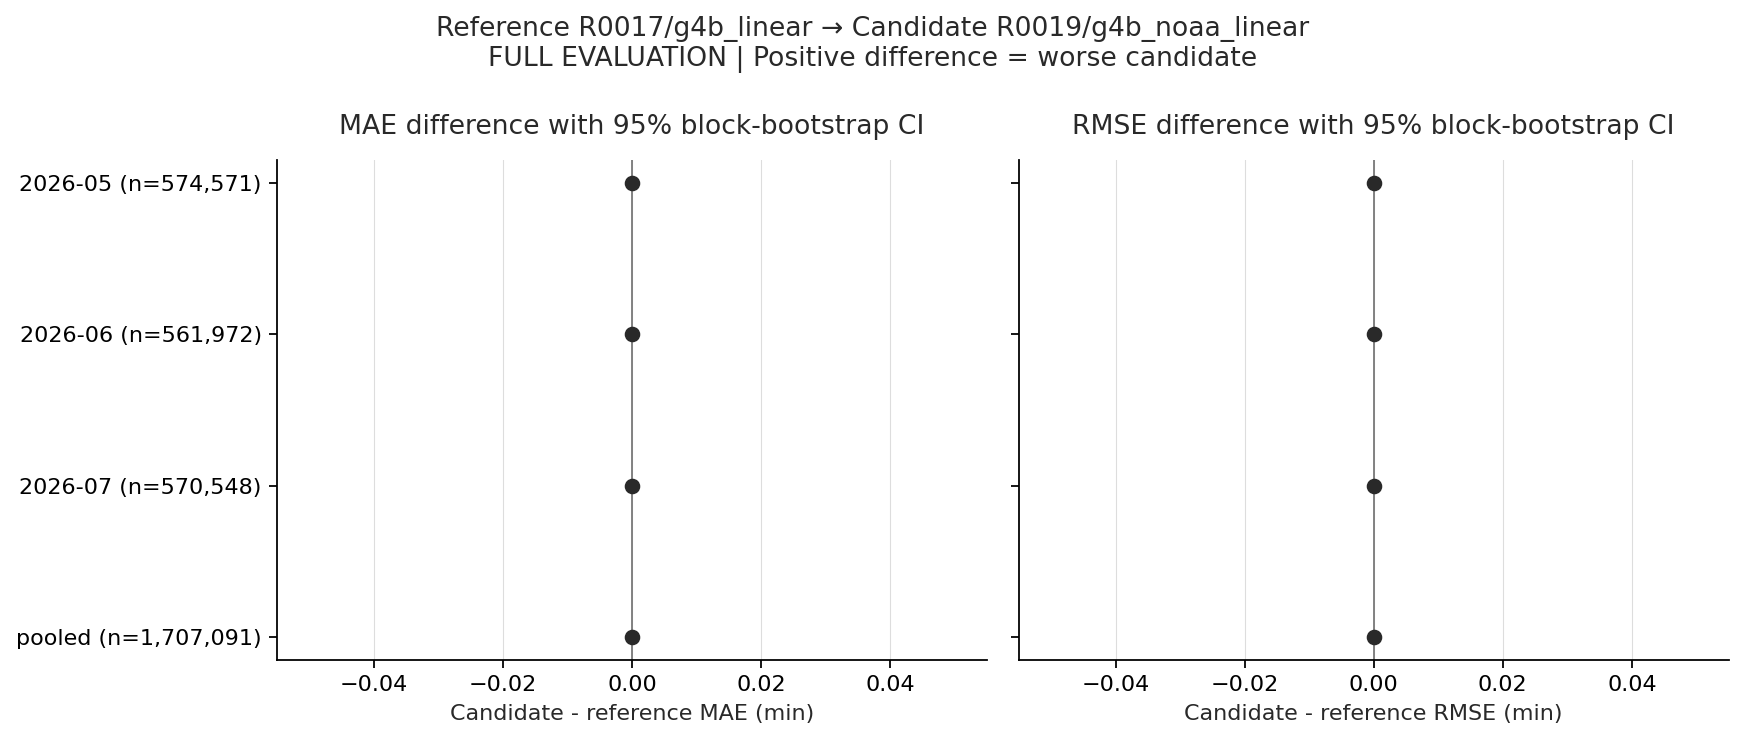

### 模型归档：R0021

运行状态：**completed**。

```json
{
  "feature_group": "G4B",
  "model_name": "dt_d8_l50",
  "model_type": "decision_tree",
  "models": [
    "dt_d8_l50"
  ],
  "features": [
    "airport_id",
    "route",
    "downstream_airline",
    "aircraft_family",
    "downstream_distance",
    "downstream_crs_elapsed_time",
    "downstream_day_of_week",
    "downstream_sched_hour",
    "scheduled_turnaround_minutes",
    "upstream_arr_delay_minutes",
    "tail_completed_24h_n",
    "tail_completed_24h_arr_delay_mean",
    "history_window_incomplete",
    "airport_departures_60m_n",
    "airport_departures_60m_delay_mean",
    "airport_planned_departures_next60m_n",
    "airport_planned_arrivals_next60m_n",
    "airport_history_window_incomplete",
    "metar_wind_knots",
    "metar_gust_knots",
    "metar_visibility_miles",
    "metar_ceiling_ft",
    "metar_precip_amount_in",
    "metar_precip_flag",
    "metar_rain_flag",
    "metar_snow_flag",
    "metar_thunder_flag",
    "metar_age_minutes",
    "metar_missing",
    "metar_sky_reported",
    "metar_ceiling_reported",
    "metar_weather_codes_reported",
    "taf_bulletin_age_minutes",
    "taf_lead_minutes",
    "taf_missing",
    "taf_prevailing_wind_knots",
    "taf_prevailing_gust_knots",
    "taf_prevailing_visibility_miles",
    "taf_prevailing_ceiling_ft",
    "taf_prevailing_precip_flag",
    "taf_prevailing_rain_flag",
    "taf_prevailing_snow_flag",
    "taf_prevailing_thunder_flag",
    "taf_prevailing_segment_count",
    "taf_prevailing_missing",
    "taf_tempo_wind_knots",
    "taf_tempo_gust_knots",
    "taf_tempo_visibility_miles",
    "taf_tempo_ceiling_ft",
    "taf_tempo_precip_flag",
    "taf_tempo_rain_flag",
    "taf_tempo_snow_flag",
    "taf_tempo_thunder_flag",
    "taf_tempo_segment_count",
    "taf_tempo_missing",
    "taf_probability_wind_knots",
    "taf_probability_gust_knots",
    "taf_probability_visibility_miles",
    "taf_probability_ceiling_ft",
    "taf_probability_precip_flag",
    "taf_probability_rain_flag",
    "taf_probability_snow_flag",
    "taf_probability_thunder_flag",
    "taf_probability_segment_count",
    "taf_probability_missing"
  ],
  "categorical_features": [
    "airport_id",
    "route",
    "downstream_airline",
    "aircraft_family"
  ],
  "numeric_features": [
    "downstream_distance",
    "downstream_crs_elapsed_time",
    "downstream_day_of_week",
    "downstream_sched_hour",
    "scheduled_turnaround_minutes",
    "upstream_arr_delay_minutes",
    "tail_completed_24h_n",
    "tail_completed_24h_arr_delay_mean",
    "history_window_incomplete",
    "airport_departures_60m_n",
    "airport_departures_60m_delay_mean",
    "airport_planned_departures_next60m_n",
    "airport_planned_arrivals_next60m_n",
    "airport_history_window_incomplete",
    "metar_wind_knots",
    "metar_gust_knots",
    "metar_visibility_miles",
    "metar_ceiling_ft",
    "metar_precip_amount_in",
    "metar_precip_flag",
    "metar_rain_flag",
    "metar_snow_flag",
    "metar_thunder_flag",
    "metar_age_minutes",
    "metar_missing",
    "metar_sky_reported",
    "metar_ceiling_reported",
    "metar_weather_codes_reported",
    "taf_bulletin_age_minutes",
    "taf_lead_minutes",
    "taf_missing",
    "taf_prevailing_wind_knots",
    "taf_prevailing_gust_knots",
    "taf_prevailing_visibility_miles",
    "taf_prevailing_ceiling_ft",
    "taf_prevailing_precip_flag",
    "taf_prevailing_rain_flag",
    "taf_prevailing_snow_flag",
    "taf_prevailing_thunder_flag",
    "taf_prevailing_segment_count",
    "taf_prevailing_missing",
    "taf_tempo_wind_knots",
    "taf_tempo_gust_knots",
    "taf_tempo_visibility_miles",
    "taf_tempo_ceiling_ft",
    "taf_tempo_precip_flag",
    "taf_tempo_rain_flag",
    "taf_tempo_snow_flag",
    "taf_tempo_thunder_flag",
    "taf_tempo_segment_count",
    "taf_tempo_missing",
    "taf_probability_wind_knots",
    "taf_probability_gust_knots",
    "taf_probability_visibility_miles",
    "taf_probability_ceiling_ft",
    "taf_probability_precip_flag",
    "taf_probability_rain_flag",
    "taf_probability_snow_flag",
    "taf_probability_thunder_flag",
    "taf_probability_segment_count",
    "taf_probability_missing"
  ],
  "model_params": {
    "ccp_alpha": 0.0,
    "criterion": "squared_error",
    "max_depth": 8,
    "max_features": null,
    "max_leaf_nodes": null,
    "min_impurity_decrease": 0.0,
    "min_samples_leaf": 50,
    "min_samples_split": 2,
    "min_weight_fraction_leaf": 0.0,
    "monotonic_cst": null,
    "random_state": 42,
    "splitter": "best"
  },
  "effective_preprocessing": {
    "min_frequency": 20,
    "drop": "first",
    "sparse": true,
    "categorical_imputation": "constant __MISSING__; keep_empty_features=True",
    "numeric_imputation": "median; add_indicator=True; keep_empty_features=True",
    "numeric_scaling": "StandardScaler(with_mean=False), fixed across algorithms",
    "unknown_categories": "infrequent_if_exist"
  },
  "evaluation_rows": 1707091,
  "evaluation_ids_sha256": "db4e500797d62152fece891a62b9c171822e97e4dea76ab92efd587bcfa8d68c",
  "split_sha256": "4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018967420e7e24441a593"
}
```

**[metrics.csv](../experiments/runs/R0021/metrics.csv)**：完整表 1,661 行；当前条件 4 行。

,model,fold,group,value,n,mae,rmse,target_ge15_share,unit,absolute_error_sum,squared_error_sum,target_ge15_n
0,dt_d8_l50,2026-05,all,all,574571,10.811177,36.261110,0.207785,minutes,6.211789e+06,7.554851e+08,119387
411,dt_d8_l50,2026-06,all,all,561972,12.514857,41.368201,0.247952,minutes,7.032999e+06,9.617185e+08,139342
826,dt_d8_l50,2026-07,all,all,570548,14.316326,47.637203,0.272265,minutes,8.168151e+06,1.294746e+09,155340
1625,dt_d8_l50,overall,all,all,1707091,12.543526,42.004472,0.242558,minutes,2.141294e+07,3.011950e+09,414069


**[comparison_metrics.csv](../experiments/runs/R0021/comparison/comparison_metrics.csv)**：完整表 8 行；当前条件 8 行。

,scope,metric,n,calendar_dates,reference_error,candidate_error,difference_candidate_minus_reference,ci95_low,ci95_high,valid_bootstrap_repeats,unit,sample_scope
0,2026-05,mae,574571,31,14.719032,10.811177,-3.907855,-4.318581,-3.528905,1000,minutes,full_evaluation
1,2026-05,rmse,574571,31,38.936825,36.261110,-2.675715,-2.977175,-2.364172,1000,minutes,full_evaluation
2,2026-06,mae,561972,30,16.873523,12.514857,-4.358665,-4.977596,-4.084281,1000,minutes,full_evaluation
3,2026-06,rmse,561972,30,44.323499,41.368201,-2.955297,-3.511152,-2.716243,1000,minutes,full_evaluation
4,2026-07,mae,570548,31,18.842982,14.316326,-4.526656,-4.682999,-4.391150,1000,minutes,full_evaluation
5,2026-07,rmse,570548,31,50.467114,47.637203,-2.829911,-3.030342,-2.643228,1000,minutes,full_evaluation
6,pooled,mae,1707091,92,16.806604,12.543526,-4.263078,-4.544568,-4.014552,1000,minutes,full_evaluation
7,pooled,rmse,1707091,92,44.813557,42.004472,-2.809085,-3.027122,-2.603149,1000,minutes,full_evaluation


**[comparison.json](../experiments/runs/R0021/comparison/comparison.json)**

```json
{
  "reference_run": "R0017",
  "candidate_run": "R0021",
  "reference_model": "g4b_linear",
  "candidate_model": "dt_d8_l50",
  "parent_run_id": "R0017",
  "candidate_declared_parent": "R0017",
  "comparison_purpose": null,
  "align_rows": false,
  "candidate_status_at_comparison": "running",
  "allow_running_candidate": true,
  "evaluation_ids_sha256": "db4e500797d62152fece891a62b9c171822e97e4dea76ab92efd587bcfa8d68c",
  "split_sha256": "4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018967420e7e24441a593",
  "sample_scope": "full_evaluation",
  "full_evaluation_n": 1707091,
  "compared_n": 1707091,
  "compared_identity_set_sha256": "cb539627cfec0128f2fd808ee86124ee174250e0246c8054e7372968c8a56506",
  "common_sample_columns": null,
  "difference_definition": "candidate minus reference; positive is worse",
  "bootstrap": {
    "method": "paired non-circular moving UTC date blocks",
    "block_days": 7,
    "repeats": 1000,
    "seed": 42,
    "confidence_level": 0.95,
    "full_calendar": "2026-05-01 through 2026-07-31 UTC, including zero-sample dates",
    "monthly_intervals": "resample each monthly calendar separately",
    "pooled_interval": "resample the full validation calendar; blocks never cross date gaps",
    "empty_resamples": "Exclude only bootstrap replicates with sampled n=0; valid replicate counts are reported; no prediction rows are dropped",
    "weighting": "sum AE / sum n; sqrt(sum SE / sum n); same sampled dates for both models"
  },
  "interpretation": "Paired sampling uncertainty, not causal evidence; explicit subsets are supplementary comparisons",
  "outputs": [
    "comparison_daily_stats.csv",
    "comparison_metrics.csv",
    "comparison_error_differences.png",
    "comparison.json"
  ]
}
```

**[comparison_error_differences.png](../experiments/runs/R0021/comparison/comparison_error_differences.png)**

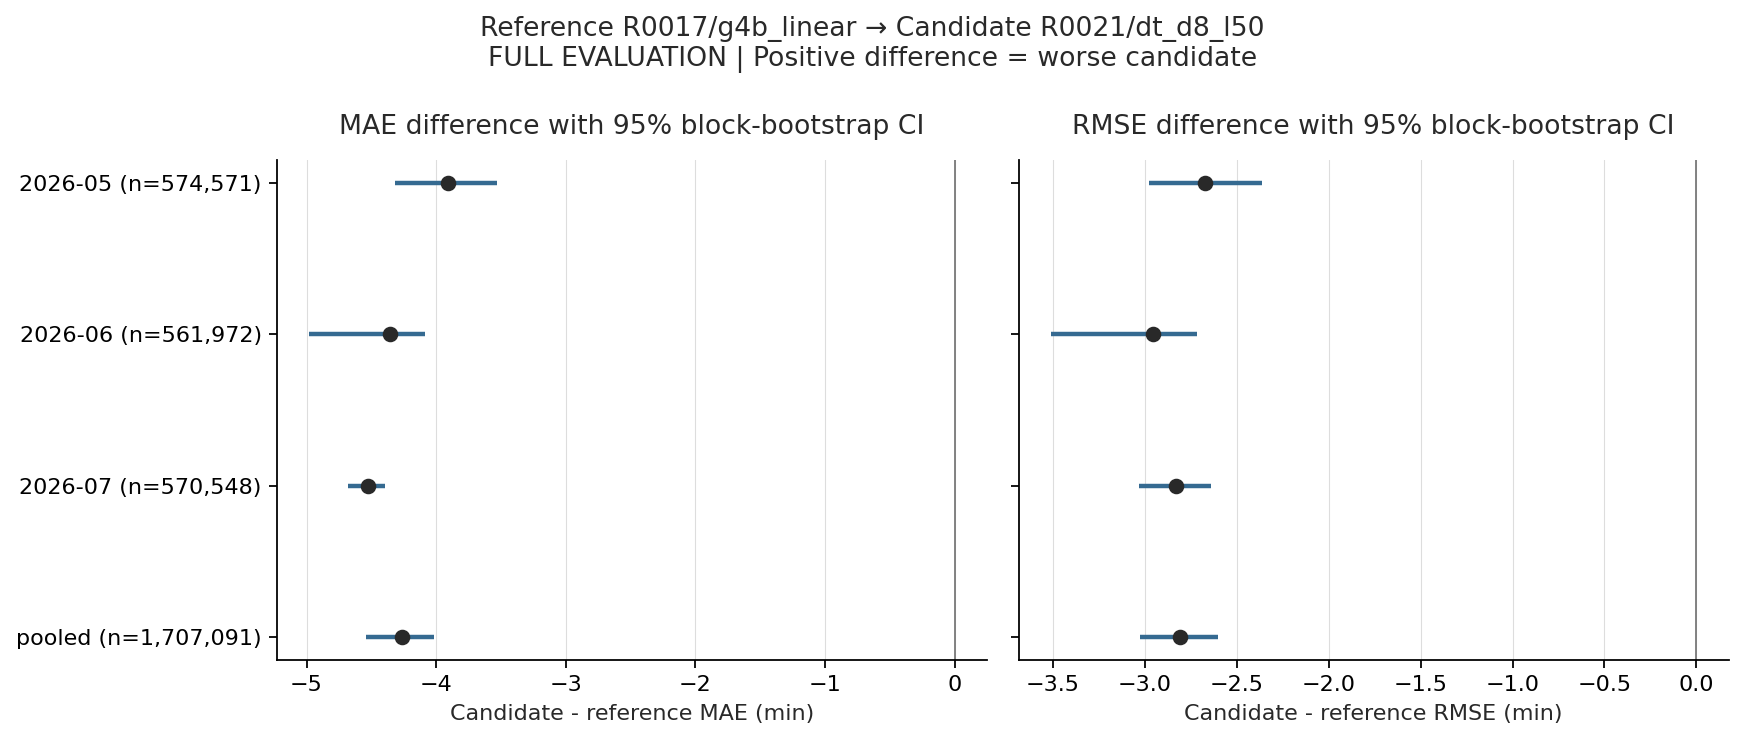

### 模型归档：R0022

运行状态：**completed**。

```json
{
  "feature_group": "G4B",
  "model_name": "dt_d8_l200",
  "model_type": "decision_tree",
  "models": [
    "dt_d8_l200"
  ],
  "features": [
    "airport_id",
    "route",
    "downstream_airline",
    "aircraft_family",
    "downstream_distance",
    "downstream_crs_elapsed_time",
    "downstream_day_of_week",
    "downstream_sched_hour",
    "scheduled_turnaround_minutes",
    "upstream_arr_delay_minutes",
    "tail_completed_24h_n",
    "tail_completed_24h_arr_delay_mean",
    "history_window_incomplete",
    "airport_departures_60m_n",
    "airport_departures_60m_delay_mean",
    "airport_planned_departures_next60m_n",
    "airport_planned_arrivals_next60m_n",
    "airport_history_window_incomplete",
    "metar_wind_knots",
    "metar_gust_knots",
    "metar_visibility_miles",
    "metar_ceiling_ft",
    "metar_precip_amount_in",
    "metar_precip_flag",
    "metar_rain_flag",
    "metar_snow_flag",
    "metar_thunder_flag",
    "metar_age_minutes",
    "metar_missing",
    "metar_sky_reported",
    "metar_ceiling_reported",
    "metar_weather_codes_reported",
    "taf_bulletin_age_minutes",
    "taf_lead_minutes",
    "taf_missing",
    "taf_prevailing_wind_knots",
    "taf_prevailing_gust_knots",
    "taf_prevailing_visibility_miles",
    "taf_prevailing_ceiling_ft",
    "taf_prevailing_precip_flag",
    "taf_prevailing_rain_flag",
    "taf_prevailing_snow_flag",
    "taf_prevailing_thunder_flag",
    "taf_prevailing_segment_count",
    "taf_prevailing_missing",
    "taf_tempo_wind_knots",
    "taf_tempo_gust_knots",
    "taf_tempo_visibility_miles",
    "taf_tempo_ceiling_ft",
    "taf_tempo_precip_flag",
    "taf_tempo_rain_flag",
    "taf_tempo_snow_flag",
    "taf_tempo_thunder_flag",
    "taf_tempo_segment_count",
    "taf_tempo_missing",
    "taf_probability_wind_knots",
    "taf_probability_gust_knots",
    "taf_probability_visibility_miles",
    "taf_probability_ceiling_ft",
    "taf_probability_precip_flag",
    "taf_probability_rain_flag",
    "taf_probability_snow_flag",
    "taf_probability_thunder_flag",
    "taf_probability_segment_count",
    "taf_probability_missing"
  ],
  "categorical_features": [
    "airport_id",
    "route",
    "downstream_airline",
    "aircraft_family"
  ],
  "numeric_features": [
    "downstream_distance",
    "downstream_crs_elapsed_time",
    "downstream_day_of_week",
    "downstream_sched_hour",
    "scheduled_turnaround_minutes",
    "upstream_arr_delay_minutes",
    "tail_completed_24h_n",
    "tail_completed_24h_arr_delay_mean",
    "history_window_incomplete",
    "airport_departures_60m_n",
    "airport_departures_60m_delay_mean",
    "airport_planned_departures_next60m_n",
    "airport_planned_arrivals_next60m_n",
    "airport_history_window_incomplete",
    "metar_wind_knots",
    "metar_gust_knots",
    "metar_visibility_miles",
    "metar_ceiling_ft",
    "metar_precip_amount_in",
    "metar_precip_flag",
    "metar_rain_flag",
    "metar_snow_flag",
    "metar_thunder_flag",
    "metar_age_minutes",
    "metar_missing",
    "metar_sky_reported",
    "metar_ceiling_reported",
    "metar_weather_codes_reported",
    "taf_bulletin_age_minutes",
    "taf_lead_minutes",
    "taf_missing",
    "taf_prevailing_wind_knots",
    "taf_prevailing_gust_knots",
    "taf_prevailing_visibility_miles",
    "taf_prevailing_ceiling_ft",
    "taf_prevailing_precip_flag",
    "taf_prevailing_rain_flag",
    "taf_prevailing_snow_flag",
    "taf_prevailing_thunder_flag",
    "taf_prevailing_segment_count",
    "taf_prevailing_missing",
    "taf_tempo_wind_knots",
    "taf_tempo_gust_knots",
    "taf_tempo_visibility_miles",
    "taf_tempo_ceiling_ft",
    "taf_tempo_precip_flag",
    "taf_tempo_rain_flag",
    "taf_tempo_snow_flag",
    "taf_tempo_thunder_flag",
    "taf_tempo_segment_count",
    "taf_tempo_missing",
    "taf_probability_wind_knots",
    "taf_probability_gust_knots",
    "taf_probability_visibility_miles",
    "taf_probability_ceiling_ft",
    "taf_probability_precip_flag",
    "taf_probability_rain_flag",
    "taf_probability_snow_flag",
    "taf_probability_thunder_flag",
    "taf_probability_segment_count",
    "taf_probability_missing"
  ],
  "model_params": {
    "ccp_alpha": 0.0,
    "criterion": "squared_error",
    "max_depth": 8,
    "max_features": null,
    "max_leaf_nodes": null,
    "min_impurity_decrease": 0.0,
    "min_samples_leaf": 200,
    "min_samples_split": 2,
    "min_weight_fraction_leaf": 0.0,
    "monotonic_cst": null,
    "random_state": 42,
    "splitter": "best"
  },
  "effective_preprocessing": {
    "min_frequency": 20,
    "drop": "first",
    "sparse": true,
    "categorical_imputation": "constant __MISSING__; keep_empty_features=True",
    "numeric_imputation": "median; add_indicator=True; keep_empty_features=True",
    "numeric_scaling": "StandardScaler(with_mean=False), fixed across algorithms",
    "unknown_categories": "infrequent_if_exist"
  },
  "evaluation_rows": 1707091,
  "evaluation_ids_sha256": "db4e500797d62152fece891a62b9c171822e97e4dea76ab92efd587bcfa8d68c",
  "split_sha256": "4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018967420e7e24441a593"
}
```

**[metrics.csv](../experiments/runs/R0022/metrics.csv)**：完整表 1,661 行；当前条件 4 行。

,model,fold,group,value,n,mae,rmse,target_ge15_share,unit,absolute_error_sum,squared_error_sum,target_ge15_n
0,dt_d8_l200,2026-05,all,all,574571,10.855546,36.478236,0.207785,minutes,6.237282e+06,7.645596e+08,119387
411,dt_d8_l200,2026-06,all,all,561972,12.532711,41.555339,0.247952,minutes,7.043033e+06,9.704392e+08,139342
826,dt_d8_l200,2026-07,all,all,570548,14.365842,47.775574,0.272265,minutes,8.196402e+06,1.302279e+09,155340
1625,dt_d8_l200,overall,all,all,1707091,12.580886,42.180713,0.242558,minutes,2.147672e+07,3.037278e+09,414069


**[comparison_metrics.csv](../experiments/runs/R0022/comparison/comparison_metrics.csv)**：完整表 8 行；当前条件 8 行。

,scope,metric,n,calendar_dates,reference_error,candidate_error,difference_candidate_minus_reference,ci95_low,ci95_high,valid_bootstrap_repeats,unit,sample_scope
0,2026-05,mae,574571,31,10.811177,10.855546,0.044369,0.015282,0.077046,1000,minutes,full_evaluation
1,2026-05,rmse,574571,31,36.261110,36.478236,0.217126,0.055779,0.358850,1000,minutes,full_evaluation
2,2026-06,mae,561972,30,12.514857,12.532711,0.017854,0.010070,0.034569,1000,minutes,full_evaluation
3,2026-06,rmse,561972,30,41.368201,41.555339,0.187138,0.131016,0.260605,1000,minutes,full_evaluation
4,2026-07,mae,570548,31,14.316326,14.365842,0.049515,0.038372,0.056908,1000,minutes,full_evaluation
5,2026-07,rmse,570548,31,47.637203,47.775574,0.138371,0.101520,0.166038,1000,minutes,full_evaluation
6,pooled,mae,1707091,92,12.543526,12.580886,0.037360,0.023652,0.049634,1000,minutes,full_evaluation
7,pooled,rmse,1707091,92,42.004472,42.180713,0.176241,0.127427,0.233645,1000,minutes,full_evaluation


**[comparison.json](../experiments/runs/R0022/comparison/comparison.json)**

```json
{
  "reference_run": "R0021",
  "candidate_run": "R0022",
  "reference_model": "dt_d8_l50",
  "candidate_model": "dt_d8_l200",
  "parent_run_id": "R0021",
  "candidate_declared_parent": "R0021",
  "comparison_purpose": null,
  "align_rows": false,
  "candidate_status_at_comparison": "running",
  "allow_running_candidate": true,
  "evaluation_ids_sha256": "db4e500797d62152fece891a62b9c171822e97e4dea76ab92efd587bcfa8d68c",
  "split_sha256": "4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018967420e7e24441a593",
  "sample_scope": "full_evaluation",
  "full_evaluation_n": 1707091,
  "compared_n": 1707091,
  "compared_identity_set_sha256": "cb539627cfec0128f2fd808ee86124ee174250e0246c8054e7372968c8a56506",
  "common_sample_columns": null,
  "difference_definition": "candidate minus reference; positive is worse",
  "bootstrap": {
    "method": "paired non-circular moving UTC date blocks",
    "block_days": 7,
    "repeats": 1000,
    "seed": 42,
    "confidence_level": 0.95,
    "full_calendar": "2026-05-01 through 2026-07-31 UTC, including zero-sample dates",
    "monthly_intervals": "resample each monthly calendar separately",
    "pooled_interval": "resample the full validation calendar; blocks never cross date gaps",
    "empty_resamples": "Exclude only bootstrap replicates with sampled n=0; valid replicate counts are reported; no prediction rows are dropped",
    "weighting": "sum AE / sum n; sqrt(sum SE / sum n); same sampled dates for both models"
  },
  "interpretation": "Paired sampling uncertainty, not causal evidence; explicit subsets are supplementary comparisons",
  "outputs": [
    "comparison_daily_stats.csv",
    "comparison_metrics.csv",
    "comparison_error_differences.png",
    "comparison.json"
  ]
}
```

**[comparison_error_differences.png](../experiments/runs/R0022/comparison/comparison_error_differences.png)**

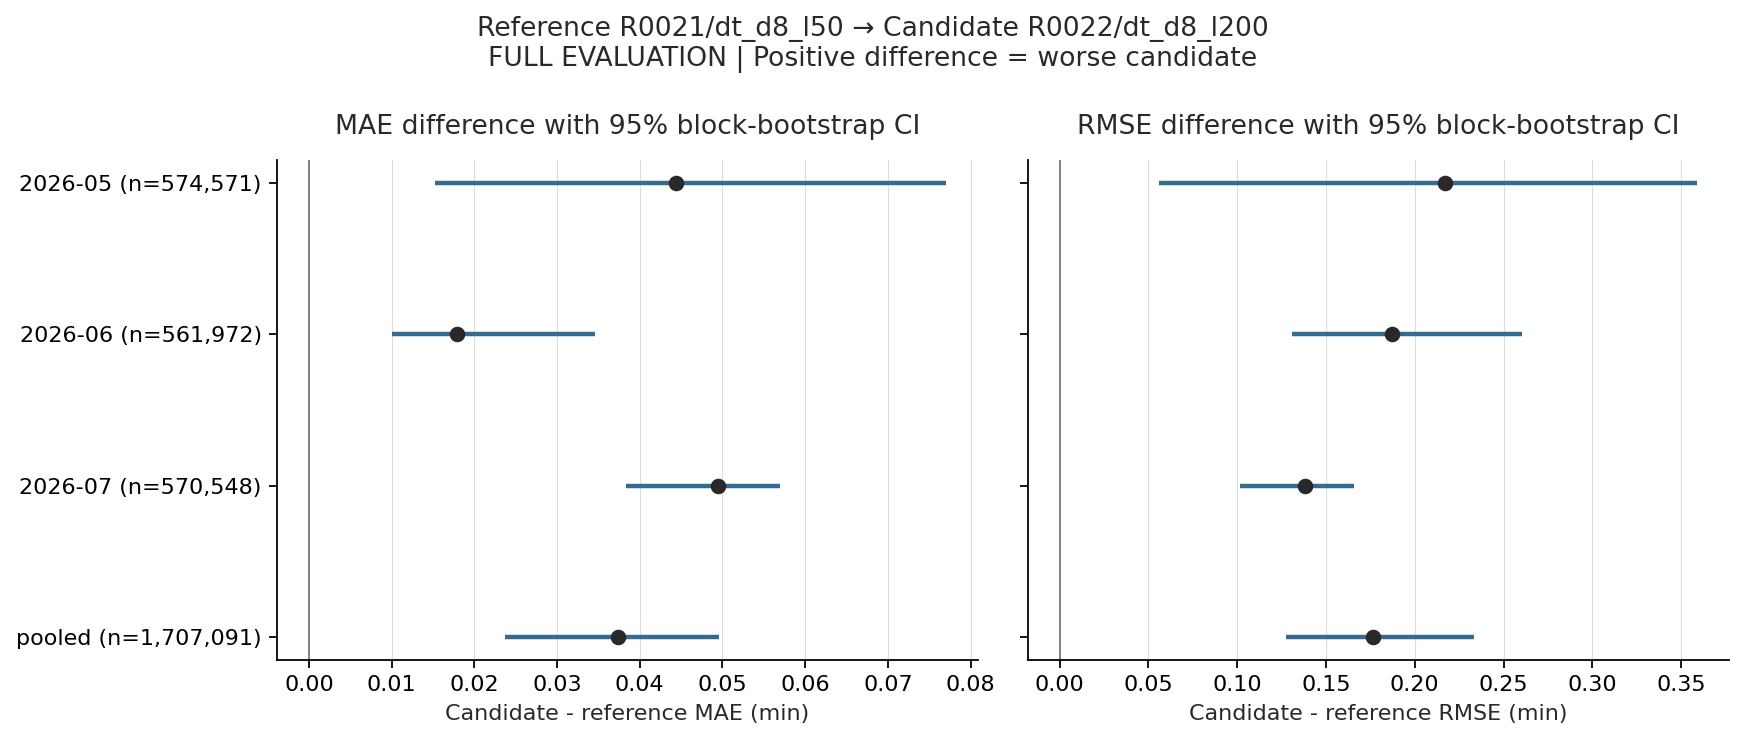

### 模型归档：R0023

运行状态：**completed**。

```json
{
  "feature_group": "G4B",
  "model_name": "dt_d16_l200",
  "model_type": "decision_tree",
  "models": [
    "dt_d16_l200"
  ],
  "features": [
    "airport_id",
    "route",
    "downstream_airline",
    "aircraft_family",
    "downstream_distance",
    "downstream_crs_elapsed_time",
    "downstream_day_of_week",
    "downstream_sched_hour",
    "scheduled_turnaround_minutes",
    "upstream_arr_delay_minutes",
    "tail_completed_24h_n",
    "tail_completed_24h_arr_delay_mean",
    "history_window_incomplete",
    "airport_departures_60m_n",
    "airport_departures_60m_delay_mean",
    "airport_planned_departures_next60m_n",
    "airport_planned_arrivals_next60m_n",
    "airport_history_window_incomplete",
    "metar_wind_knots",
    "metar_gust_knots",
    "metar_visibility_miles",
    "metar_ceiling_ft",
    "metar_precip_amount_in",
    "metar_precip_flag",
    "metar_rain_flag",
    "metar_snow_flag",
    "metar_thunder_flag",
    "metar_age_minutes",
    "metar_missing",
    "metar_sky_reported",
    "metar_ceiling_reported",
    "metar_weather_codes_reported",
    "taf_bulletin_age_minutes",
    "taf_lead_minutes",
    "taf_missing",
    "taf_prevailing_wind_knots",
    "taf_prevailing_gust_knots",
    "taf_prevailing_visibility_miles",
    "taf_prevailing_ceiling_ft",
    "taf_prevailing_precip_flag",
    "taf_prevailing_rain_flag",
    "taf_prevailing_snow_flag",
    "taf_prevailing_thunder_flag",
    "taf_prevailing_segment_count",
    "taf_prevailing_missing",
    "taf_tempo_wind_knots",
    "taf_tempo_gust_knots",
    "taf_tempo_visibility_miles",
    "taf_tempo_ceiling_ft",
    "taf_tempo_precip_flag",
    "taf_tempo_rain_flag",
    "taf_tempo_snow_flag",
    "taf_tempo_thunder_flag",
    "taf_tempo_segment_count",
    "taf_tempo_missing",
    "taf_probability_wind_knots",
    "taf_probability_gust_knots",
    "taf_probability_visibility_miles",
    "taf_probability_ceiling_ft",
    "taf_probability_precip_flag",
    "taf_probability_rain_flag",
    "taf_probability_snow_flag",
    "taf_probability_thunder_flag",
    "taf_probability_segment_count",
    "taf_probability_missing"
  ],
  "categorical_features": [
    "airport_id",
    "route",
    "downstream_airline",
    "aircraft_family"
  ],
  "numeric_features": [
    "downstream_distance",
    "downstream_crs_elapsed_time",
    "downstream_day_of_week",
    "downstream_sched_hour",
    "scheduled_turnaround_minutes",
    "upstream_arr_delay_minutes",
    "tail_completed_24h_n",
    "tail_completed_24h_arr_delay_mean",
    "history_window_incomplete",
    "airport_departures_60m_n",
    "airport_departures_60m_delay_mean",
    "airport_planned_departures_next60m_n",
    "airport_planned_arrivals_next60m_n",
    "airport_history_window_incomplete",
    "metar_wind_knots",
    "metar_gust_knots",
    "metar_visibility_miles",
    "metar_ceiling_ft",
    "metar_precip_amount_in",
    "metar_precip_flag",
    "metar_rain_flag",
    "metar_snow_flag",
    "metar_thunder_flag",
    "metar_age_minutes",
    "metar_missing",
    "metar_sky_reported",
    "metar_ceiling_reported",
    "metar_weather_codes_reported",
    "taf_bulletin_age_minutes",
    "taf_lead_minutes",
    "taf_missing",
    "taf_prevailing_wind_knots",
    "taf_prevailing_gust_knots",
    "taf_prevailing_visibility_miles",
    "taf_prevailing_ceiling_ft",
    "taf_prevailing_precip_flag",
    "taf_prevailing_rain_flag",
    "taf_prevailing_snow_flag",
    "taf_prevailing_thunder_flag",
    "taf_prevailing_segment_count",
    "taf_prevailing_missing",
    "taf_tempo_wind_knots",
    "taf_tempo_gust_knots",
    "taf_tempo_visibility_miles",
    "taf_tempo_ceiling_ft",
    "taf_tempo_precip_flag",
    "taf_tempo_rain_flag",
    "taf_tempo_snow_flag",
    "taf_tempo_thunder_flag",
    "taf_tempo_segment_count",
    "taf_tempo_missing",
    "taf_probability_wind_knots",
    "taf_probability_gust_knots",
    "taf_probability_visibility_miles",
    "taf_probability_ceiling_ft",
    "taf_probability_precip_flag",
    "taf_probability_rain_flag",
    "taf_probability_snow_flag",
    "taf_probability_thunder_flag",
    "taf_probability_segment_count",
    "taf_probability_missing"
  ],
  "model_params": {
    "ccp_alpha": 0.0,
    "criterion": "squared_error",
    "max_depth": 16,
    "max_features": null,
    "max_leaf_nodes": null,
    "min_impurity_decrease": 0.0,
    "min_samples_leaf": 200,
    "min_samples_split": 2,
    "min_weight_fraction_leaf": 0.0,
    "monotonic_cst": null,
    "random_state": 42,
    "splitter": "best"
  },
  "effective_preprocessing": {
    "min_frequency": 20,
    "drop": "first",
    "sparse": true,
    "categorical_imputation": "constant __MISSING__; keep_empty_features=True",
    "numeric_imputation": "median; add_indicator=True; keep_empty_features=True",
    "numeric_scaling": "StandardScaler(with_mean=False), fixed across algorithms",
    "unknown_categories": "infrequent_if_exist"
  },
  "evaluation_rows": 1707091,
  "evaluation_ids_sha256": "db4e500797d62152fece891a62b9c171822e97e4dea76ab92efd587bcfa8d68c",
  "split_sha256": "4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018967420e7e24441a593"
}
```

**[metrics.csv](../experiments/runs/R0023/metrics.csv)**：完整表 1,661 行；当前条件 4 行。

,model,fold,group,value,n,mae,rmse,target_ge15_share,unit,absolute_error_sum,squared_error_sum,target_ge15_n
0,dt_d16_l200,2026-05,all,all,574571,10.759921,36.530559,0.207785,minutes,6.182339e+06,7.667545e+08,119387
411,dt_d16_l200,2026-06,all,all,561972,12.426493,41.516605,0.247952,minutes,6.983341e+06,9.686310e+08,139342
826,dt_d16_l200,2026-07,all,all,570548,14.279797,47.679490,0.272265,minutes,8.147310e+06,1.297046e+09,155340
1625,dt_d16_l200,overall,all,all,1707091,12.484975,42.147048,0.242558,minutes,2.131299e+07,3.032432e+09,414069


**[comparison_metrics.csv](../experiments/runs/R0023/comparison/comparison_metrics.csv)**：完整表 8 行；当前条件 8 行。

,scope,metric,n,calendar_dates,reference_error,candidate_error,difference_candidate_minus_reference,ci95_low,ci95_high,valid_bootstrap_repeats,unit,sample_scope
0,2026-05,mae,574571,31,10.855546,10.759921,-0.095625,-0.135368,-0.043663,1000,minutes,full_evaluation
1,2026-05,rmse,574571,31,36.478236,36.530559,0.052323,0.038487,0.062717,1000,minutes,full_evaluation
2,2026-06,mae,561972,30,12.532711,12.426493,-0.106219,-0.138378,-0.059355,1000,minutes,full_evaluation
3,2026-06,rmse,561972,30,41.555339,41.516605,-0.038734,-0.069776,-0.024915,1000,minutes,full_evaluation
4,2026-07,mae,570548,31,14.365842,14.279797,-0.086045,-0.108594,-0.043345,1000,minutes,full_evaluation
5,2026-07,rmse,570548,31,47.775574,47.679490,-0.096083,-0.131761,-0.061529,1000,minutes,full_evaluation
6,pooled,mae,1707091,92,12.580886,12.484975,-0.095910,-0.118778,-0.070505,1000,minutes,full_evaluation
7,pooled,rmse,1707091,92,42.180713,42.147048,-0.033665,-0.069517,0.003137,1000,minutes,full_evaluation


**[comparison.json](../experiments/runs/R0023/comparison/comparison.json)**

```json
{
  "reference_run": "R0022",
  "candidate_run": "R0023",
  "reference_model": "dt_d8_l200",
  "candidate_model": "dt_d16_l200",
  "parent_run_id": "R0022",
  "candidate_declared_parent": "R0022",
  "comparison_purpose": null,
  "align_rows": false,
  "candidate_status_at_comparison": "running",
  "allow_running_candidate": true,
  "evaluation_ids_sha256": "db4e500797d62152fece891a62b9c171822e97e4dea76ab92efd587bcfa8d68c",
  "split_sha256": "4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018967420e7e24441a593",
  "sample_scope": "full_evaluation",
  "full_evaluation_n": 1707091,
  "compared_n": 1707091,
  "compared_identity_set_sha256": "cb539627cfec0128f2fd808ee86124ee174250e0246c8054e7372968c8a56506",
  "common_sample_columns": null,
  "difference_definition": "candidate minus reference; positive is worse",
  "bootstrap": {
    "method": "paired non-circular moving UTC date blocks",
    "block_days": 7,
    "repeats": 1000,
    "seed": 42,
    "confidence_level": 0.95,
    "full_calendar": "2026-05-01 through 2026-07-31 UTC, including zero-sample dates",
    "monthly_intervals": "resample each monthly calendar separately",
    "pooled_interval": "resample the full validation calendar; blocks never cross date gaps",
    "empty_resamples": "Exclude only bootstrap replicates with sampled n=0; valid replicate counts are reported; no prediction rows are dropped",
    "weighting": "sum AE / sum n; sqrt(sum SE / sum n); same sampled dates for both models"
  },
  "interpretation": "Paired sampling uncertainty, not causal evidence; explicit subsets are supplementary comparisons",
  "outputs": [
    "comparison_daily_stats.csv",
    "comparison_metrics.csv",
    "comparison_error_differences.png",
    "comparison.json"
  ]
}
```

**[comparison_error_differences.png](../experiments/runs/R0023/comparison/comparison_error_differences.png)**

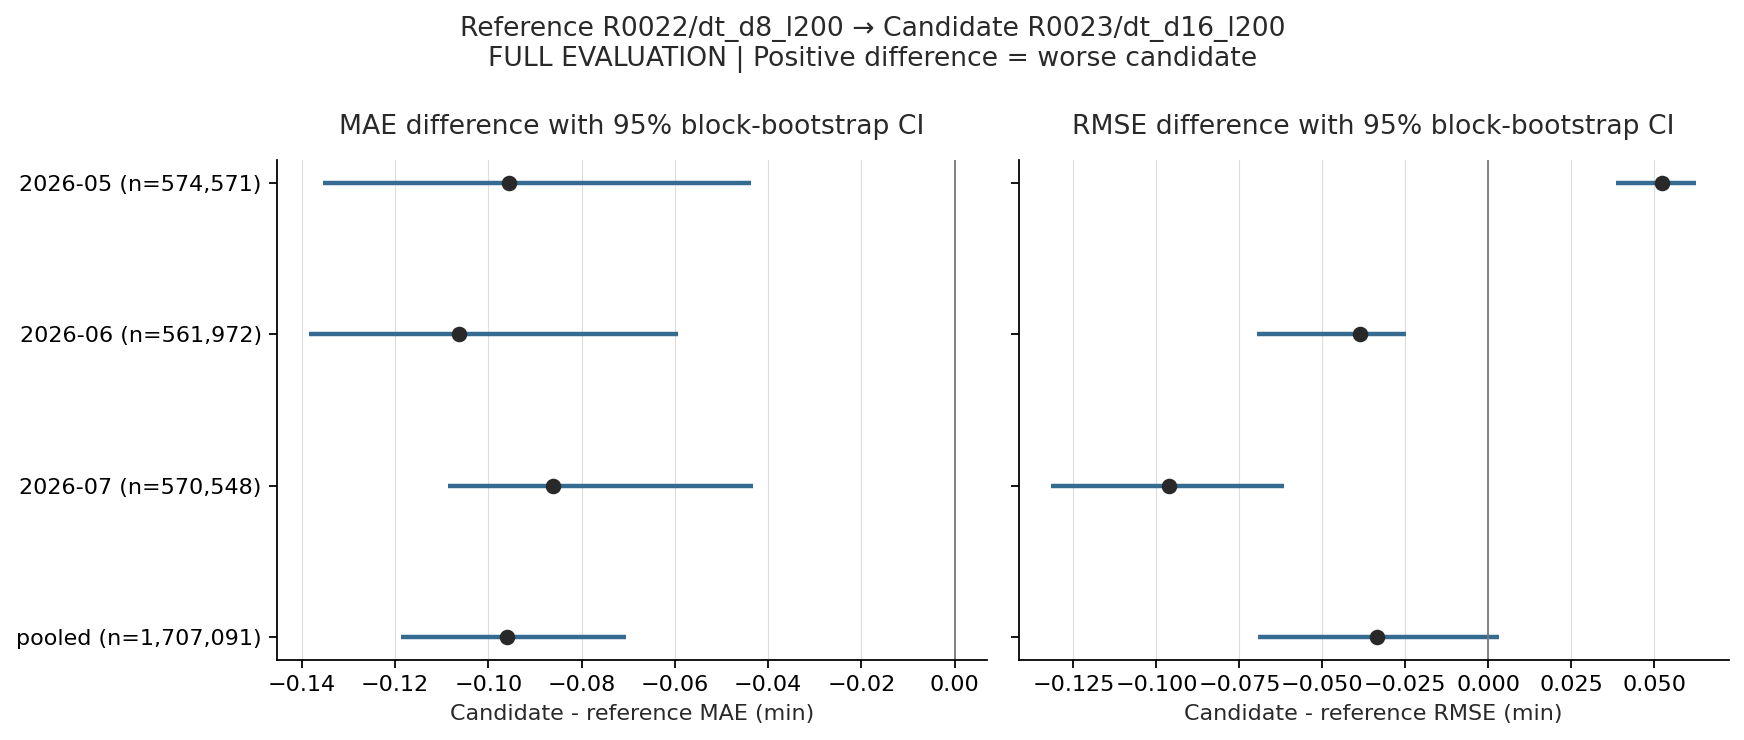

### 模型归档：R0024

运行状态：**completed**。

```json
{
  "feature_group": "G4B",
  "model_name": "dt_d16_l50",
  "model_type": "decision_tree",
  "models": [
    "dt_d16_l50"
  ],
  "features": [
    "airport_id",
    "route",
    "downstream_airline",
    "aircraft_family",
    "downstream_distance",
    "downstream_crs_elapsed_time",
    "downstream_day_of_week",
    "downstream_sched_hour",
    "scheduled_turnaround_minutes",
    "upstream_arr_delay_minutes",
    "tail_completed_24h_n",
    "tail_completed_24h_arr_delay_mean",
    "history_window_incomplete",
    "airport_departures_60m_n",
    "airport_departures_60m_delay_mean",
    "airport_planned_departures_next60m_n",
    "airport_planned_arrivals_next60m_n",
    "airport_history_window_incomplete",
    "metar_wind_knots",
    "metar_gust_knots",
    "metar_visibility_miles",
    "metar_ceiling_ft",
    "metar_precip_amount_in",
    "metar_precip_flag",
    "metar_rain_flag",
    "metar_snow_flag",
    "metar_thunder_flag",
    "metar_age_minutes",
    "metar_missing",
    "metar_sky_reported",
    "metar_ceiling_reported",
    "metar_weather_codes_reported",
    "taf_bulletin_age_minutes",
    "taf_lead_minutes",
    "taf_missing",
    "taf_prevailing_wind_knots",
    "taf_prevailing_gust_knots",
    "taf_prevailing_visibility_miles",
    "taf_prevailing_ceiling_ft",
    "taf_prevailing_precip_flag",
    "taf_prevailing_rain_flag",
    "taf_prevailing_snow_flag",
    "taf_prevailing_thunder_flag",
    "taf_prevailing_segment_count",
    "taf_prevailing_missing",
    "taf_tempo_wind_knots",
    "taf_tempo_gust_knots",
    "taf_tempo_visibility_miles",
    "taf_tempo_ceiling_ft",
    "taf_tempo_precip_flag",
    "taf_tempo_rain_flag",
    "taf_tempo_snow_flag",
    "taf_tempo_thunder_flag",
    "taf_tempo_segment_count",
    "taf_tempo_missing",
    "taf_probability_wind_knots",
    "taf_probability_gust_knots",
    "taf_probability_visibility_miles",
    "taf_probability_ceiling_ft",
    "taf_probability_precip_flag",
    "taf_probability_rain_flag",
    "taf_probability_snow_flag",
    "taf_probability_thunder_flag",
    "taf_probability_segment_count",
    "taf_probability_missing"
  ],
  "categorical_features": [
    "airport_id",
    "route",
    "downstream_airline",
    "aircraft_family"
  ],
  "numeric_features": [
    "downstream_distance",
    "downstream_crs_elapsed_time",
    "downstream_day_of_week",
    "downstream_sched_hour",
    "scheduled_turnaround_minutes",
    "upstream_arr_delay_minutes",
    "tail_completed_24h_n",
    "tail_completed_24h_arr_delay_mean",
    "history_window_incomplete",
    "airport_departures_60m_n",
    "airport_departures_60m_delay_mean",
    "airport_planned_departures_next60m_n",
    "airport_planned_arrivals_next60m_n",
    "airport_history_window_incomplete",
    "metar_wind_knots",
    "metar_gust_knots",
    "metar_visibility_miles",
    "metar_ceiling_ft",
    "metar_precip_amount_in",
    "metar_precip_flag",
    "metar_rain_flag",
    "metar_snow_flag",
    "metar_thunder_flag",
    "metar_age_minutes",
    "metar_missing",
    "metar_sky_reported",
    "metar_ceiling_reported",
    "metar_weather_codes_reported",
    "taf_bulletin_age_minutes",
    "taf_lead_minutes",
    "taf_missing",
    "taf_prevailing_wind_knots",
    "taf_prevailing_gust_knots",
    "taf_prevailing_visibility_miles",
    "taf_prevailing_ceiling_ft",
    "taf_prevailing_precip_flag",
    "taf_prevailing_rain_flag",
    "taf_prevailing_snow_flag",
    "taf_prevailing_thunder_flag",
    "taf_prevailing_segment_count",
    "taf_prevailing_missing",
    "taf_tempo_wind_knots",
    "taf_tempo_gust_knots",
    "taf_tempo_visibility_miles",
    "taf_tempo_ceiling_ft",
    "taf_tempo_precip_flag",
    "taf_tempo_rain_flag",
    "taf_tempo_snow_flag",
    "taf_tempo_thunder_flag",
    "taf_tempo_segment_count",
    "taf_tempo_missing",
    "taf_probability_wind_knots",
    "taf_probability_gust_knots",
    "taf_probability_visibility_miles",
    "taf_probability_ceiling_ft",
    "taf_probability_precip_flag",
    "taf_probability_rain_flag",
    "taf_probability_snow_flag",
    "taf_probability_thunder_flag",
    "taf_probability_segment_count",
    "taf_probability_missing"
  ],
  "model_params": {
    "ccp_alpha": 0.0,
    "criterion": "squared_error",
    "max_depth": 16,
    "max_features": null,
    "max_leaf_nodes": null,
    "min_impurity_decrease": 0.0,
    "min_samples_leaf": 50,
    "min_samples_split": 2,
    "min_weight_fraction_leaf": 0.0,
    "monotonic_cst": null,
    "random_state": 42,
    "splitter": "best"
  },
  "effective_preprocessing": {
    "min_frequency": 20,
    "drop": "first",
    "sparse": true,
    "categorical_imputation": "constant __MISSING__; keep_empty_features=True",
    "numeric_imputation": "median; add_indicator=True; keep_empty_features=True",
    "numeric_scaling": "StandardScaler(with_mean=False), fixed across algorithms",
    "unknown_categories": "infrequent_if_exist"
  },
  "evaluation_rows": 1707091,
  "evaluation_ids_sha256": "db4e500797d62152fece891a62b9c171822e97e4dea76ab92efd587bcfa8d68c",
  "split_sha256": "4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018967420e7e24441a593"
}
```

**[metrics.csv](../experiments/runs/R0024/metrics.csv)**：完整表 1,661 行；当前条件 4 行。

,model,fold,group,value,n,mae,rmse,target_ge15_share,unit,absolute_error_sum,squared_error_sum,target_ge15_n
0,dt_d16_l50,2026-05,all,all,574571,10.745832,36.422568,0.207785,minutes,6.174243e+06,7.622279e+08,119387
411,dt_d16_l50,2026-06,all,all,561972,12.494420,41.515187,0.247952,minutes,7.021514e+06,9.685648e+08,139342
826,dt_d16_l50,2026-07,all,all,570548,14.330968,47.703835,0.272265,minutes,8.176505e+06,1.298371e+09,155340
1625,dt_d16_l50,overall,all,all,1707091,12.519697,42.124332,0.242558,minutes,2.137226e+07,3.029164e+09,414069


**[comparison_metrics.csv](../experiments/runs/R0024/comparison/comparison_metrics.csv)**：完整表 8 行；当前条件 8 行。

,scope,metric,n,calendar_dates,reference_error,candidate_error,difference_candidate_minus_reference,ci95_low,ci95_high,valid_bootstrap_repeats,unit,sample_scope
0,2026-05,mae,574571,31,10.759921,10.745832,-0.014089,-0.043315,0.010433,1000,minutes,full_evaluation
1,2026-05,rmse,574571,31,36.530559,36.422568,-0.107992,-0.245103,0.042670,1000,minutes,full_evaluation
2,2026-06,mae,561972,30,12.426493,12.494420,0.067928,0.051548,0.098297,1000,minutes,full_evaluation
3,2026-06,rmse,561972,30,41.516605,41.515187,-0.001419,-0.059837,0.067927,1000,minutes,full_evaluation
4,2026-07,mae,570548,31,14.279797,14.330968,0.051171,0.038957,0.081634,1000,minutes,full_evaluation
5,2026-07,rmse,570548,31,47.679490,47.703835,0.024345,-0.016341,0.098884,1000,minutes,full_evaluation
6,pooled,mae,1707091,92,12.484975,12.519697,0.034722,0.011718,0.060966,1000,minutes,full_evaluation
7,pooled,rmse,1707091,92,42.147048,42.124332,-0.022717,-0.086026,0.029357,1000,minutes,full_evaluation


**[comparison.json](../experiments/runs/R0024/comparison/comparison.json)**

```json
{
  "reference_run": "R0023",
  "candidate_run": "R0024",
  "reference_model": "dt_d16_l200",
  "candidate_model": "dt_d16_l50",
  "parent_run_id": "R0023",
  "candidate_declared_parent": "R0023",
  "comparison_purpose": null,
  "align_rows": false,
  "candidate_status_at_comparison": "running",
  "allow_running_candidate": true,
  "evaluation_ids_sha256": "db4e500797d62152fece891a62b9c171822e97e4dea76ab92efd587bcfa8d68c",
  "split_sha256": "4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018967420e7e24441a593",
  "sample_scope": "full_evaluation",
  "full_evaluation_n": 1707091,
  "compared_n": 1707091,
  "compared_identity_set_sha256": "cb539627cfec0128f2fd808ee86124ee174250e0246c8054e7372968c8a56506",
  "common_sample_columns": null,
  "difference_definition": "candidate minus reference; positive is worse",
  "bootstrap": {
    "method": "paired non-circular moving UTC date blocks",
    "block_days": 7,
    "repeats": 1000,
    "seed": 42,
    "confidence_level": 0.95,
    "full_calendar": "2026-05-01 through 2026-07-31 UTC, including zero-sample dates",
    "monthly_intervals": "resample each monthly calendar separately",
    "pooled_interval": "resample the full validation calendar; blocks never cross date gaps",
    "empty_resamples": "Exclude only bootstrap replicates with sampled n=0; valid replicate counts are reported; no prediction rows are dropped",
    "weighting": "sum AE / sum n; sqrt(sum SE / sum n); same sampled dates for both models"
  },
  "interpretation": "Paired sampling uncertainty, not causal evidence; explicit subsets are supplementary comparisons",
  "outputs": [
    "comparison_daily_stats.csv",
    "comparison_metrics.csv",
    "comparison_error_differences.png",
    "comparison.json"
  ]
}
```

**[comparison_error_differences.png](../experiments/runs/R0024/comparison/comparison_error_differences.png)**

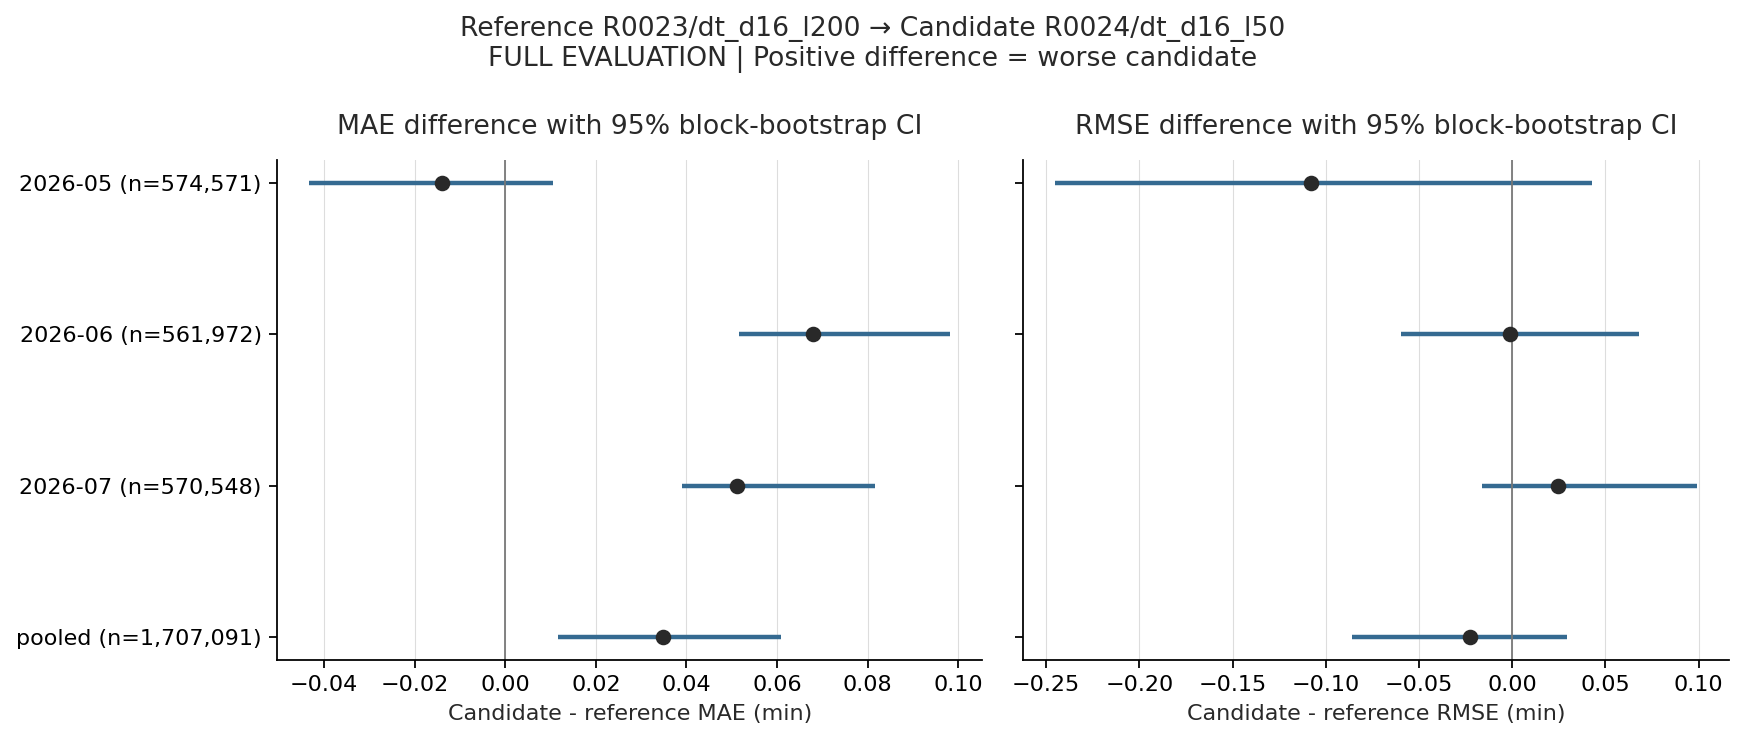

### 模型归档：R0025

运行状态：**completed**。

```json
{
  "feature_group": "G4B",
  "model_name": "rf_d16_l50",
  "model_type": "random_forest",
  "models": [
    "rf_d16_l50"
  ],
  "features": [
    "airport_id",
    "route",
    "downstream_airline",
    "aircraft_family",
    "downstream_distance",
    "downstream_crs_elapsed_time",
    "downstream_day_of_week",
    "downstream_sched_hour",
    "scheduled_turnaround_minutes",
    "upstream_arr_delay_minutes",
    "tail_completed_24h_n",
    "tail_completed_24h_arr_delay_mean",
    "history_window_incomplete",
    "airport_departures_60m_n",
    "airport_departures_60m_delay_mean",
    "airport_planned_departures_next60m_n",
    "airport_planned_arrivals_next60m_n",
    "airport_history_window_incomplete",
    "metar_wind_knots",
    "metar_gust_knots",
    "metar_visibility_miles",
    "metar_ceiling_ft",
    "metar_precip_amount_in",
    "metar_precip_flag",
    "metar_rain_flag",
    "metar_snow_flag",
    "metar_thunder_flag",
    "metar_age_minutes",
    "metar_missing",
    "metar_sky_reported",
    "metar_ceiling_reported",
    "metar_weather_codes_reported",
    "taf_bulletin_age_minutes",
    "taf_lead_minutes",
    "taf_missing",
    "taf_prevailing_wind_knots",
    "taf_prevailing_gust_knots",
    "taf_prevailing_visibility_miles",
    "taf_prevailing_ceiling_ft",
    "taf_prevailing_precip_flag",
    "taf_prevailing_rain_flag",
    "taf_prevailing_snow_flag",
    "taf_prevailing_thunder_flag",
    "taf_prevailing_segment_count",
    "taf_prevailing_missing",
    "taf_tempo_wind_knots",
    "taf_tempo_gust_knots",
    "taf_tempo_visibility_miles",
    "taf_tempo_ceiling_ft",
    "taf_tempo_precip_flag",
    "taf_tempo_rain_flag",
    "taf_tempo_snow_flag",
    "taf_tempo_thunder_flag",
    "taf_tempo_segment_count",
    "taf_tempo_missing",
    "taf_probability_wind_knots",
    "taf_probability_gust_knots",
    "taf_probability_visibility_miles",
    "taf_probability_ceiling_ft",
    "taf_probability_precip_flag",
    "taf_probability_rain_flag",
    "taf_probability_snow_flag",
    "taf_probability_thunder_flag",
    "taf_probability_segment_count",
    "taf_probability_missing"
  ],
  "categorical_features": [
    "airport_id",
    "route",
    "downstream_airline",
    "aircraft_family"
  ],
  "numeric_features": [
    "downstream_distance",
    "downstream_crs_elapsed_time",
    "downstream_day_of_week",
    "downstream_sched_hour",
    "scheduled_turnaround_minutes",
    "upstream_arr_delay_minutes",
    "tail_completed_24h_n",
    "tail_completed_24h_arr_delay_mean",
    "history_window_incomplete",
    "airport_departures_60m_n",
    "airport_departures_60m_delay_mean",
    "airport_planned_departures_next60m_n",
    "airport_planned_arrivals_next60m_n",
    "airport_history_window_incomplete",
    "metar_wind_knots",
    "metar_gust_knots",
    "metar_visibility_miles",
    "metar_ceiling_ft",
    "metar_precip_amount_in",
    "metar_precip_flag",
    "metar_rain_flag",
    "metar_snow_flag",
    "metar_thunder_flag",
    "metar_age_minutes",
    "metar_missing",
    "metar_sky_reported",
    "metar_ceiling_reported",
    "metar_weather_codes_reported",
    "taf_bulletin_age_minutes",
    "taf_lead_minutes",
    "taf_missing",
    "taf_prevailing_wind_knots",
    "taf_prevailing_gust_knots",
    "taf_prevailing_visibility_miles",
    "taf_prevailing_ceiling_ft",
    "taf_prevailing_precip_flag",
    "taf_prevailing_rain_flag",
    "taf_prevailing_snow_flag",
    "taf_prevailing_thunder_flag",
    "taf_prevailing_segment_count",
    "taf_prevailing_missing",
    "taf_tempo_wind_knots",
    "taf_tempo_gust_knots",
    "taf_tempo_visibility_miles",
    "taf_tempo_ceiling_ft",
    "taf_tempo_precip_flag",
    "taf_tempo_rain_flag",
    "taf_tempo_snow_flag",
    "taf_tempo_thunder_flag",
    "taf_tempo_segment_count",
    "taf_tempo_missing",
    "taf_probability_wind_knots",
    "taf_probability_gust_knots",
    "taf_probability_visibility_miles",
    "taf_probability_ceiling_ft",
    "taf_probability_precip_flag",
    "taf_probability_rain_flag",
    "taf_probability_snow_flag",
    "taf_probability_thunder_flag",
    "taf_probability_segment_count",
    "taf_probability_missing"
  ],
  "model_params": {
    "bootstrap": true,
    "ccp_alpha": 0.0,
    "criterion": "squared_error",
    "max_depth": 16,
    "max_features": 0.5,
    "max_leaf_nodes": null,
    "max_samples": null,
    "min_impurity_decrease": 0.0,
    "min_samples_leaf": 50,
    "min_samples_split": 2,
    "min_weight_fraction_leaf": 0.0,
    "monotonic_cst": null,
    "n_estimators": 200,
    "n_jobs": 8,
    "oob_score": false,
    "random_state": 42,
    "verbose": 0,
    "warm_start": false
  },
  "effective_preprocessing": {
    "min_frequency": 20,
    "drop": "first",
    "sparse": true,
    "categorical_imputation": "constant __MISSING__; keep_empty_features=True",
    "numeric_imputation": "median; add_indicator=True; keep_empty_features=True",
    "numeric_scaling": "StandardScaler(with_mean=False), fixed across algorithms",
    "unknown_categories": "infrequent_if_exist"
  },
  "evaluation_rows": 1707091,
  "evaluation_ids_sha256": "db4e500797d62152fece891a62b9c171822e97e4dea76ab92efd587bcfa8d68c",
  "split_sha256": "4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018967420e7e24441a593"
}
```

**[metrics.csv](../experiments/runs/R0025/metrics.csv)**：完整表 1,661 行；当前条件 4 行。

,model,fold,group,value,n,mae,rmse,target_ge15_share,unit,absolute_error_sum,squared_error_sum,target_ge15_n
0,rf_d16_l50,2026-05,all,all,574571,10.462333,36.124997,0.207785,minutes,6.011353e+06,7.498240e+08,119387
411,rf_d16_l50,2026-06,all,all,561972,12.144760,41.169029,0.247952,minutes,6.825015e+06,9.524801e+08,139342
826,rf_d16_l50,2026-07,all,all,570548,13.897443,47.281023,0.272265,minutes,7.929158e+06,1.275457e+09,155340
1625,rf_d16_l50,overall,all,all,1707091,12.164276,41.765397,0.242558,minutes,2.076553e+07,2.977761e+09,414069


**[comparison_metrics.csv](../experiments/runs/R0025/comparison/comparison_metrics.csv)**：完整表 8 行；当前条件 8 行。

,scope,metric,n,calendar_dates,reference_error,candidate_error,difference_candidate_minus_reference,ci95_low,ci95_high,valid_bootstrap_repeats,unit,sample_scope
0,2026-05,mae,574571,31,10.745832,10.462333,-0.283499,-0.345875,-0.240278,1000,minutes,full_evaluation
1,2026-05,rmse,574571,31,36.422568,36.124997,-0.297571,-0.389229,-0.220995,1000,minutes,full_evaluation
2,2026-06,mae,561972,30,12.494420,12.144760,-0.349661,-0.447696,-0.313601,1000,minutes,full_evaluation
3,2026-06,rmse,561972,30,41.515187,41.169029,-0.346158,-0.415284,-0.308507,1000,minutes,full_evaluation
4,2026-07,mae,570548,31,14.330968,13.897443,-0.433525,-0.494177,-0.406936,1000,minutes,full_evaluation
5,2026-07,rmse,570548,31,47.703835,47.281023,-0.422812,-0.518795,-0.370961,1000,minutes,full_evaluation
6,pooled,mae,1707091,92,12.519697,12.164276,-0.355422,-0.409048,-0.307582,1000,minutes,full_evaluation
7,pooled,rmse,1707091,92,42.124332,41.765397,-0.358935,-0.408383,-0.303204,1000,minutes,full_evaluation


**[comparison.json](../experiments/runs/R0025/comparison/comparison.json)**

```json
{
  "reference_run": "R0024",
  "candidate_run": "R0025",
  "reference_model": "dt_d16_l50",
  "candidate_model": "rf_d16_l50",
  "parent_run_id": "R0024",
  "candidate_declared_parent": "R0024",
  "comparison_purpose": null,
  "align_rows": false,
  "candidate_status_at_comparison": "running",
  "allow_running_candidate": true,
  "evaluation_ids_sha256": "db4e500797d62152fece891a62b9c171822e97e4dea76ab92efd587bcfa8d68c",
  "split_sha256": "4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018967420e7e24441a593",
  "sample_scope": "full_evaluation",
  "full_evaluation_n": 1707091,
  "compared_n": 1707091,
  "compared_identity_set_sha256": "cb539627cfec0128f2fd808ee86124ee174250e0246c8054e7372968c8a56506",
  "common_sample_columns": null,
  "difference_definition": "candidate minus reference; positive is worse",
  "bootstrap": {
    "method": "paired non-circular moving UTC date blocks",
    "block_days": 7,
    "repeats": 1000,
    "seed": 42,
    "confidence_level": 0.95,
    "full_calendar": "2026-05-01 through 2026-07-31 UTC, including zero-sample dates",
    "monthly_intervals": "resample each monthly calendar separately",
    "pooled_interval": "resample the full validation calendar; blocks never cross date gaps",
    "empty_resamples": "Exclude only bootstrap replicates with sampled n=0; valid replicate counts are reported; no prediction rows are dropped",
    "weighting": "sum AE / sum n; sqrt(sum SE / sum n); same sampled dates for both models"
  },
  "interpretation": "Paired sampling uncertainty, not causal evidence; explicit subsets are supplementary comparisons",
  "outputs": [
    "comparison_daily_stats.csv",
    "comparison_metrics.csv",
    "comparison_error_differences.png",
    "comparison.json"
  ]
}
```

**[comparison_error_differences.png](../experiments/runs/R0025/comparison/comparison_error_differences.png)**

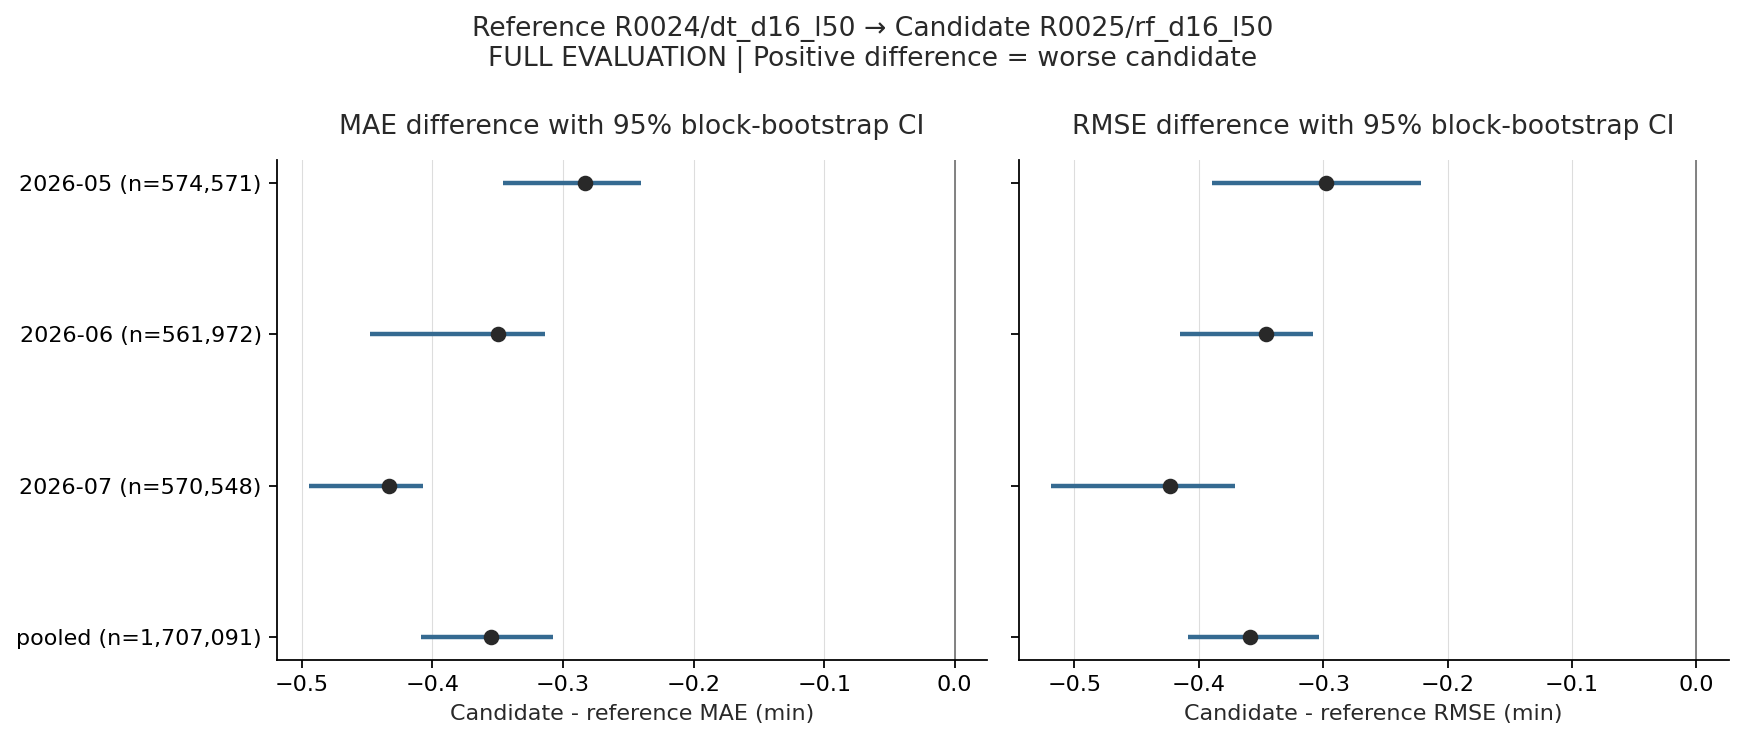

### 模型归档：R0026

运行状态：**completed**。

```json
{
  "feature_group": "G4B",
  "model_name": "rf_d16_l200",
  "model_type": "random_forest",
  "models": [
    "rf_d16_l200"
  ],
  "features": [
    "airport_id",
    "route",
    "downstream_airline",
    "aircraft_family",
    "downstream_distance",
    "downstream_crs_elapsed_time",
    "downstream_day_of_week",
    "downstream_sched_hour",
    "scheduled_turnaround_minutes",
    "upstream_arr_delay_minutes",
    "tail_completed_24h_n",
    "tail_completed_24h_arr_delay_mean",
    "history_window_incomplete",
    "airport_departures_60m_n",
    "airport_departures_60m_delay_mean",
    "airport_planned_departures_next60m_n",
    "airport_planned_arrivals_next60m_n",
    "airport_history_window_incomplete",
    "metar_wind_knots",
    "metar_gust_knots",
    "metar_visibility_miles",
    "metar_ceiling_ft",
    "metar_precip_amount_in",
    "metar_precip_flag",
    "metar_rain_flag",
    "metar_snow_flag",
    "metar_thunder_flag",
    "metar_age_minutes",
    "metar_missing",
    "metar_sky_reported",
    "metar_ceiling_reported",
    "metar_weather_codes_reported",
    "taf_bulletin_age_minutes",
    "taf_lead_minutes",
    "taf_missing",
    "taf_prevailing_wind_knots",
    "taf_prevailing_gust_knots",
    "taf_prevailing_visibility_miles",
    "taf_prevailing_ceiling_ft",
    "taf_prevailing_precip_flag",
    "taf_prevailing_rain_flag",
    "taf_prevailing_snow_flag",
    "taf_prevailing_thunder_flag",
    "taf_prevailing_segment_count",
    "taf_prevailing_missing",
    "taf_tempo_wind_knots",
    "taf_tempo_gust_knots",
    "taf_tempo_visibility_miles",
    "taf_tempo_ceiling_ft",
    "taf_tempo_precip_flag",
    "taf_tempo_rain_flag",
    "taf_tempo_snow_flag",
    "taf_tempo_thunder_flag",
    "taf_tempo_segment_count",
    "taf_tempo_missing",
    "taf_probability_wind_knots",
    "taf_probability_gust_knots",
    "taf_probability_visibility_miles",
    "taf_probability_ceiling_ft",
    "taf_probability_precip_flag",
    "taf_probability_rain_flag",
    "taf_probability_snow_flag",
    "taf_probability_thunder_flag",
    "taf_probability_segment_count",
    "taf_probability_missing"
  ],
  "categorical_features": [
    "airport_id",
    "route",
    "downstream_airline",
    "aircraft_family"
  ],
  "numeric_features": [
    "downstream_distance",
    "downstream_crs_elapsed_time",
    "downstream_day_of_week",
    "downstream_sched_hour",
    "scheduled_turnaround_minutes",
    "upstream_arr_delay_minutes",
    "tail_completed_24h_n",
    "tail_completed_24h_arr_delay_mean",
    "history_window_incomplete",
    "airport_departures_60m_n",
    "airport_departures_60m_delay_mean",
    "airport_planned_departures_next60m_n",
    "airport_planned_arrivals_next60m_n",
    "airport_history_window_incomplete",
    "metar_wind_knots",
    "metar_gust_knots",
    "metar_visibility_miles",
    "metar_ceiling_ft",
    "metar_precip_amount_in",
    "metar_precip_flag",
    "metar_rain_flag",
    "metar_snow_flag",
    "metar_thunder_flag",
    "metar_age_minutes",
    "metar_missing",
    "metar_sky_reported",
    "metar_ceiling_reported",
    "metar_weather_codes_reported",
    "taf_bulletin_age_minutes",
    "taf_lead_minutes",
    "taf_missing",
    "taf_prevailing_wind_knots",
    "taf_prevailing_gust_knots",
    "taf_prevailing_visibility_miles",
    "taf_prevailing_ceiling_ft",
    "taf_prevailing_precip_flag",
    "taf_prevailing_rain_flag",
    "taf_prevailing_snow_flag",
    "taf_prevailing_thunder_flag",
    "taf_prevailing_segment_count",
    "taf_prevailing_missing",
    "taf_tempo_wind_knots",
    "taf_tempo_gust_knots",
    "taf_tempo_visibility_miles",
    "taf_tempo_ceiling_ft",
    "taf_tempo_precip_flag",
    "taf_tempo_rain_flag",
    "taf_tempo_snow_flag",
    "taf_tempo_thunder_flag",
    "taf_tempo_segment_count",
    "taf_tempo_missing",
    "taf_probability_wind_knots",
    "taf_probability_gust_knots",
    "taf_probability_visibility_miles",
    "taf_probability_ceiling_ft",
    "taf_probability_precip_flag",
    "taf_probability_rain_flag",
    "taf_probability_snow_flag",
    "taf_probability_thunder_flag",
    "taf_probability_segment_count",
    "taf_probability_missing"
  ],
  "model_params": {
    "bootstrap": true,
    "ccp_alpha": 0.0,
    "criterion": "squared_error",
    "max_depth": 16,
    "max_features": 0.5,
    "max_leaf_nodes": null,
    "max_samples": null,
    "min_impurity_decrease": 0.0,
    "min_samples_leaf": 200,
    "min_samples_split": 2,
    "min_weight_fraction_leaf": 0.0,
    "monotonic_cst": null,
    "n_estimators": 200,
    "n_jobs": 24,
    "oob_score": false,
    "random_state": 42,
    "verbose": 0,
    "warm_start": false
  },
  "effective_preprocessing": {
    "min_frequency": 20,
    "drop": "first",
    "sparse": true,
    "categorical_imputation": "constant __MISSING__; keep_empty_features=True",
    "numeric_imputation": "median; add_indicator=True; keep_empty_features=True",
    "numeric_scaling": "StandardScaler(with_mean=False), fixed across algorithms",
    "unknown_categories": "infrequent_if_exist"
  },
  "evaluation_rows": 1707091,
  "evaluation_ids_sha256": "db4e500797d62152fece891a62b9c171822e97e4dea76ab92efd587bcfa8d68c",
  "split_sha256": "4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018967420e7e24441a593"
}
```

**[metrics.csv](../experiments/runs/R0026/metrics.csv)**：完整表 1,661 行；当前条件 4 行。

,model,fold,group,value,n,mae,rmse,target_ge15_share,unit,absolute_error_sum,squared_error_sum,target_ge15_n
0,rf_d16_l200,2026-05,all,all,574571,10.626909,36.467352,0.207785,minutes,6.105914e+06,7.641035e+08,119387
411,rf_d16_l200,2026-06,all,all,561972,12.284353,41.561315,0.247952,minutes,6.903462e+06,9.707184e+08,139342
826,rf_d16_l200,2026-07,all,all,570548,14.030639,47.591685,0.272265,minutes,8.005153e+06,1.292273e+09,155340
1625,rf_d16_l200,overall,all,all,1707091,12.310140,42.109947,0.242558,minutes,2.101453e+07,3.027095e+09,414069


**[comparison_metrics.csv](../experiments/runs/R0026/comparison/comparison_metrics.csv)**：完整表 8 行；当前条件 8 行。

,scope,metric,n,calendar_dates,reference_error,candidate_error,difference_candidate_minus_reference,ci95_low,ci95_high,valid_bootstrap_repeats,unit,sample_scope
0,2026-05,mae,574571,31,10.462333,10.626909,0.164577,0.118964,0.231473,1000,minutes,full_evaluation
1,2026-05,rmse,574571,31,36.124997,36.467352,0.342355,0.196112,0.498701,1000,minutes,full_evaluation
2,2026-06,mae,561972,30,12.144760,12.284353,0.139593,0.117355,0.193497,1000,minutes,full_evaluation
3,2026-06,rmse,561972,30,41.169029,41.561315,0.392287,0.311224,0.513618,1000,minutes,full_evaluation
4,2026-07,mae,570548,31,13.897443,14.030639,0.133196,0.123863,0.144760,1000,minutes,full_evaluation
5,2026-07,rmse,570548,31,47.281023,47.591685,0.310662,0.279734,0.362977,1000,minutes,full_evaluation
6,pooled,mae,1707091,92,12.164276,12.310140,0.145864,0.123072,0.174689,1000,minutes,full_evaluation
7,pooled,rmse,1707091,92,41.765397,42.109947,0.344550,0.290819,0.419144,1000,minutes,full_evaluation


**[comparison.json](../experiments/runs/R0026/comparison/comparison.json)**

```json
{
  "reference_run": "R0025",
  "candidate_run": "R0026",
  "reference_model": "rf_d16_l50",
  "candidate_model": "rf_d16_l200",
  "parent_run_id": "R0025",
  "candidate_declared_parent": "R0025",
  "comparison_purpose": null,
  "align_rows": false,
  "candidate_status_at_comparison": "running",
  "allow_running_candidate": true,
  "evaluation_ids_sha256": "db4e500797d62152fece891a62b9c171822e97e4dea76ab92efd587bcfa8d68c",
  "split_sha256": "4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018967420e7e24441a593",
  "sample_scope": "full_evaluation",
  "full_evaluation_n": 1707091,
  "compared_n": 1707091,
  "compared_identity_set_sha256": "cb539627cfec0128f2fd808ee86124ee174250e0246c8054e7372968c8a56506",
  "common_sample_columns": null,
  "difference_definition": "candidate minus reference; positive is worse",
  "bootstrap": {
    "method": "paired non-circular moving UTC date blocks",
    "block_days": 7,
    "repeats": 1000,
    "seed": 42,
    "confidence_level": 0.95,
    "full_calendar": "2026-05-01 through 2026-07-31 UTC, including zero-sample dates",
    "monthly_intervals": "resample each monthly calendar separately",
    "pooled_interval": "resample the full validation calendar; blocks never cross date gaps",
    "empty_resamples": "Exclude only bootstrap replicates with sampled n=0; valid replicate counts are reported; no prediction rows are dropped",
    "weighting": "sum AE / sum n; sqrt(sum SE / sum n); same sampled dates for both models"
  },
  "interpretation": "Paired sampling uncertainty, not causal evidence; explicit subsets are supplementary comparisons",
  "outputs": [
    "comparison_daily_stats.csv",
    "comparison_metrics.csv",
    "comparison_error_differences.png",
    "comparison.json"
  ]
}
```

**[comparison_error_differences.png](../experiments/runs/R0026/comparison/comparison_error_differences.png)**

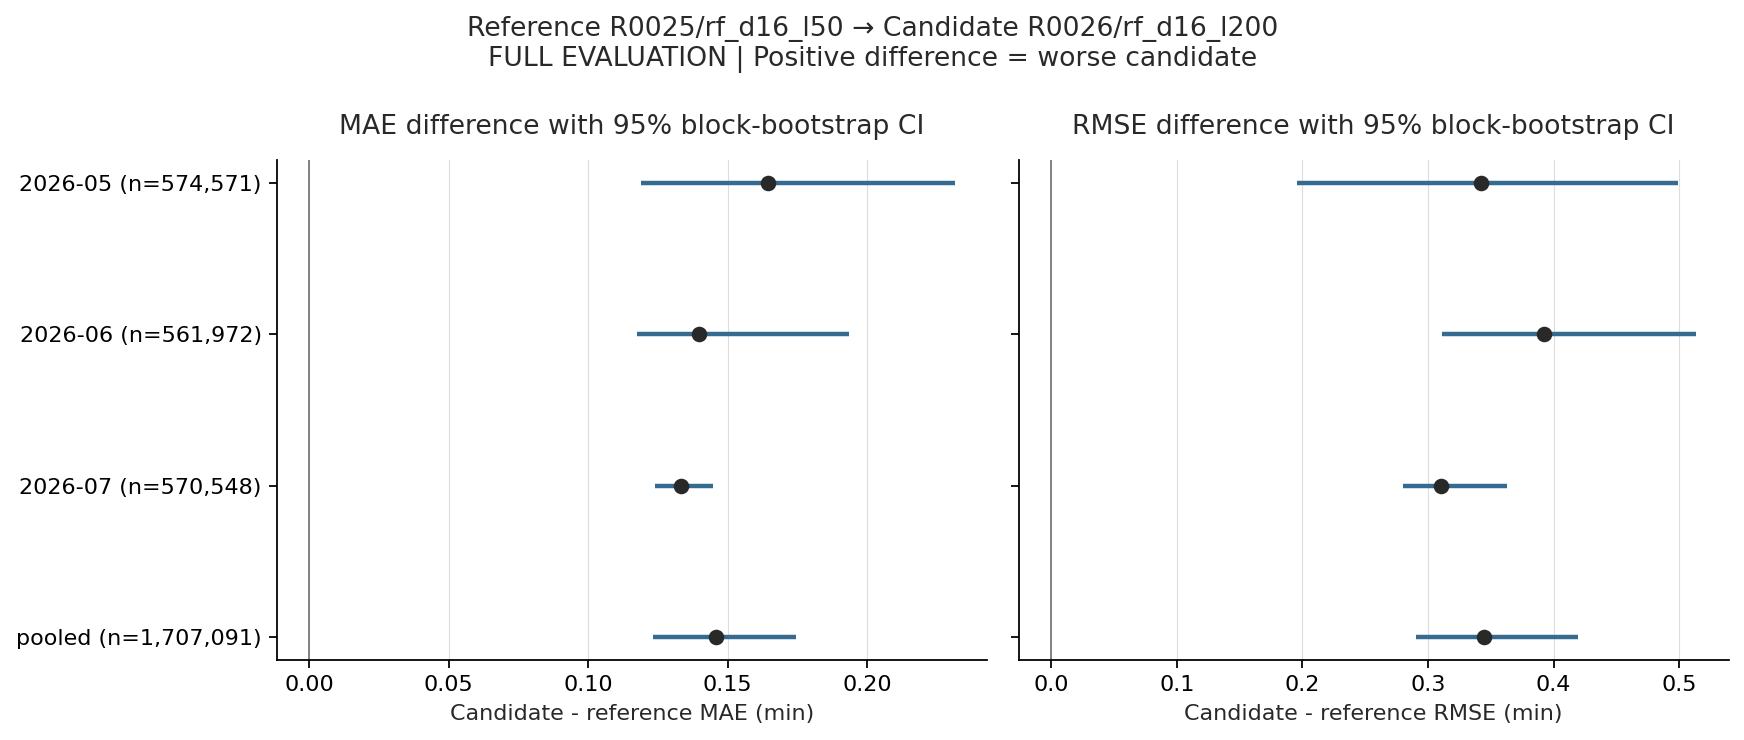

### 所指定开发运行的整体指标

,run_id,model,n,mae,rmse,feature_group,model_type,evaluation_ids_sha256,split_sha256
0,R0006,carry_forward,1707091,17.425608,57.330724,G0,linear,db4e500797d62152fece891a62b9c171822e97e4dea76a...,4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018...
1,R0006,g0_linear,1707091,19.573829,50.235168,G0,linear,db4e500797d62152fece891a62b9c171822e97e4dea76a...,4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018...
2,R0006,training_mean,1707091,20.911252,50.929578,G0,linear,db4e500797d62152fece891a62b9c171822e97e4dea76a...,4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018...
3,R0006,training_median,1707091,16.618017,53.468967,G0,linear,db4e500797d62152fece891a62b9c171822e97e4dea76a...,4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018...
4,R0007,carry_forward,1707091,17.425608,57.330724,G1,linear,db4e500797d62152fece891a62b9c171822e97e4dea76a...,4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018...
5,R0007,g1_linear,1707091,17.258108,46.941039,G1,linear,db4e500797d62152fece891a62b9c171822e97e4dea76a...,4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018...
6,R0007,training_mean,1707091,20.911252,50.929578,G1,linear,db4e500797d62152fece891a62b9c171822e97e4dea76a...,4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018...
7,R0007,training_median,1707091,16.618017,53.468967,G1,linear,db4e500797d62152fece891a62b9c171822e97e4dea76a...,4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018...
8,R0009,carry_forward,1707091,17.425608,57.330724,G2,linear,db4e500797d62152fece891a62b9c171822e97e4dea76a...,4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018...
9,R0009,g2_family_linear,1707091,17.248724,46.936626,G2,linear,db4e500797d62152fece891a62b9c171822e97e4dea76a...,4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018...


这些归档声明相同的评估 ID 与切分哈希；完整逐行标签/时间一致性及配对区间仍以各 comparison.json/CSV 为证据。

,run_id,model,n,mae,rmse,feature_group,model_type,evaluation_ids_sha256,split_sha256,delta_MAE_vs_training_mean,delta_MAE_vs_training_median,delta_MAE_vs_carry_forward
0,R0006,carry_forward,1707091,17.425608,57.330724,G0,linear,db4e500797d62152fece891a62b9c171822e97e4dea76a...,4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018...,-3.485645,0.807590,0.000000
1,R0006,g0_linear,1707091,19.573829,50.235168,G0,linear,db4e500797d62152fece891a62b9c171822e97e4dea76a...,4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018...,-1.337423,2.955812,2.148221
2,R0006,training_mean,1707091,20.911252,50.929578,G0,linear,db4e500797d62152fece891a62b9c171822e97e4dea76a...,4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018...,0.000000,4.293235,3.485645
3,R0006,training_median,1707091,16.618017,53.468967,G0,linear,db4e500797d62152fece891a62b9c171822e97e4dea76a...,4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018...,-4.293235,0.000000,-0.807590
4,R0007,carry_forward,1707091,17.425608,57.330724,G1,linear,db4e500797d62152fece891a62b9c171822e97e4dea76a...,4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018...,-3.485645,0.807590,0.000000
5,R0007,g1_linear,1707091,17.258108,46.941039,G1,linear,db4e500797d62152fece891a62b9c171822e97e4dea76a...,4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018...,-3.653145,0.640090,-0.167500
6,R0007,training_mean,1707091,20.911252,50.929578,G1,linear,db4e500797d62152fece891a62b9c171822e97e4dea76a...,4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018...,0.000000,4.293235,3.485645
7,R0007,training_median,1707091,16.618017,53.468967,G1,linear,db4e500797d62152fece891a62b9c171822e97e4dea76a...,4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018...,-4.293235,0.000000,-0.807590
8,R0009,carry_forward,1707091,17.425608,57.330724,G2,linear,db4e500797d62152fece891a62b9c171822e97e4dea76a...,4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018...,-3.485645,0.807590,0.000000
9,R0009,g2_family_linear,1707091,17.248724,46.936626,G2,linear,db4e500797d62152fece891a62b9c171822e97e4dea76a...,4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018...,-3.662528,0.630706,-0.176884


增量表为候选 MAE 减参照 MAE：正值表示更差；不是配对置信区间，也不是因果效应。

...

**[model_selection_decision.json](../experiments/runs/R0027/selection/model_selection_decision.json)**

```json
{
  "selection_type": "model",
  "selected_run_id": "R0025",
  "selected_run_dir": "D:\\airline-delay\\experiments\\runs\\R0025",
  "feature_source_run_id": "R0017",
  "feature_source_run_dir": "D:\\airline-delay\\experiments\\runs\\R0017",
  "development_feature_sha256": "f6ef89bf5290c6ddaf55f06d3d759fc9305d7e21e0a3e5c2c8936b5a39b642d8",
  "config": {
    "data_id": "D0003",
    "connection_path": "processed/D0003/flight_connections.csv.gz",
    "data_manifest_path": "processed/D0003/data_manifest.json",
    "feature_group": "G4B",
    "model_name": "rf_d16_l50",
    "model_type": "random_forest",
    "include_baselines": true,
    "threads": 8,
    "seed": 42,
    "linear_tolerance": 1e-06,
    "preprocessing": {
      "drop": "first",
      "min_frequency": 20
    },
    "primary_metric": "sample-weighted pooled validation MAE in minutes",
    "prediction_rule": "clip all predictions at zero",
    "split_rule": "UTC half-open prediction windows; training label_time strictly before cutoff",
    "sample_interpretation": "Retrospective prediction conditional on valid observed same-tail scheduled-adjacent completed connections",
    "weather_manifest_path": "processed/W0002/data_manifest.json",
    "noaa_backfill": false,
    "features": [
      "airport_id",
      "route",
      "downstream_airline",
      "aircraft_family",
      "downstream_distance",
      "downstream_crs_elapsed_time",
      "downstream_day_of_week",
      "downstream_sched_hour",
      "scheduled_turnaround_minutes",
      "upstream_arr_delay_minutes",
      "tail_completed_24h_n",
      "tail_completed_24h_arr_delay_mean",
      "history_window_incomplete",
      "airport_departures_60m_n",
      "airport_departures_60m_delay_mean",
      "airport_planned_departures_next60m_n",
      "airport_planned_arrivals_next60m_n",
      "airport_history_window_incomplete",
      "metar_wind_knots",
      "metar_gust_knots",
      "metar_visibility_miles",
      "metar_ceiling_ft",
      "metar_precip_amount_in",
      "metar_precip_flag",
      "metar_rain_flag",
      "metar_snow_flag",
      "metar_thunder_flag",
      "metar_age_minutes",
      "metar_missing",
      "metar_sky_reported",
      "metar_ceiling_reported",
      "metar_weather_codes_reported",
      "taf_bulletin_age_minutes",
      "taf_lead_minutes",
      "taf_missing",
      "taf_prevailing_wind_knots",
      "taf_prevailing_gust_knots",
      "taf_prevailing_visibility_miles",
      "taf_prevailing_ceiling_ft",
      "taf_prevailing_precip_flag",
      "taf_prevailing_rain_flag",
      "taf_prevailing_snow_flag",
      "taf_prevailing_thunder_flag",
      "taf_prevailing_segment_count",
      "taf_prevailing_missing",
      "taf_tempo_wind_knots",
      "taf_tempo_gust_knots",
      "taf_tempo_visibility_miles",
      "taf_tempo_ceiling_ft",
      "taf_tempo_precip_flag",
      "taf_tempo_rain_flag",
      "taf_tempo_snow_flag",
      "taf_tempo_thunder_flag",
      "taf_tempo_segment_count",
      "taf_tempo_missing",
      "taf_probability_wind_knots",
      "taf_probability_gust_knots",
      "taf_probability_visibility_miles",
      "taf_probability_ceiling_ft",
      "taf_probability_precip_flag",
      "taf_probability_rain_flag",
      "taf_probability_snow_flag",
      "taf_probability_thunder_flag",
      "taf_probability_segment_count",
      "taf_probability_missing"
    ],
    "categorical_features": [
      "airport_id",
      "route",
      "downstream_airline",
      "aircraft_family"
    ],
    "numeric_features": [
      "downstream_distance",
      "downstream_crs_elapsed_time",
      "downstream_day_of_week",
      "downstream_sched_hour",
      "scheduled_turnaround_minutes",
      "upstream_arr_delay_minutes",
      "tail_completed_24h_n",
      "tail_completed_24h_arr_delay_mean",
      "history_window_incomplete",
      "airport_departures_60m_n",
      "airport_departures_60m_delay_mean",
      "airport_planned_departures_next60m_n",
      "airport_planned_arrivals_next60m_n",
      "airport_history_window_incomplete",
      "metar_wind_knots",
      "metar_gust_knots",
      "metar_visibility_miles",
      "metar_ceiling_ft",
      "metar_precip_amount_in",
      "metar_precip_flag",
      "metar_rain_flag",
      "metar_snow_flag",
      "metar_thunder_flag",
      "metar_age_minutes",
      "metar_missing",
      "metar_sky_reported",
      "metar_ceiling_reported",
      "metar_weather_codes_reported",
      "taf_bulletin_age_minutes",
      "taf_lead_minutes",
      "taf_missing",
      "taf_prevailing_wind_knots",
      "taf_prevailing_gust_knots",
      "taf_prevailing_visibility_miles",
      "taf_prevailing_ceiling_ft",
      "taf_prevailing_precip_flag",
      "taf_prevailing_rain_flag",
      "taf_prevailing_snow_flag",
      "taf_prevailing_thunder_flag",
      "taf_prevailing_segment_count",
      "taf_prevailing_missing",
      "taf_tempo_wind_knots",
      "taf_tempo_gust_knots",
      "taf_tempo_visibility_miles",
      "taf_tempo_ceiling_ft",
      "taf_tempo_precip_flag",
      "taf_tempo_rain_flag",
      "taf_tempo_snow_flag",
      "taf_tempo_thunder_flag",
      "taf_tempo_segment_count",
      "taf_tempo_missing",
      "taf_probability_wind_knots",
      "taf_probability_gust_knots",
      "taf_probability_visibility_miles",
      "taf_probability_ceiling_ft",
      "taf_probability_precip_flag",
      "taf_probability_rain_flag",
      "taf_probability_snow_flag",
      "taf_probability_thunder_flag",
      "taf_probability_segment_count",
      "taf_probability_missing"
    ],
    "model_params": {
      "max_depth": 16,
      "max_features": 0.5,
      "min_samples_leaf": 50,
      "n_estimators": 200,
      "random_state": 42
    }
  },
  "primary_model_name": "rf_d16_l50",
  "primary_development_mae": 12.164275884412929,
  "primary_candidates": [
    {
      "model": "rf_d16_l50",
      "mae": 12.164275884412929,
      "run_id": "R0025"
    },
    {
      "model": "training_mean",
      "mae": 20.911252222695456,
      "run_id": "R0017"
    },
    {
      "model": "training_median",
      "mae": 16.618017434337126,
      "run_id": "R0017"
    },
    {
      "model": "carry_forward",
      "mae": 17.425607656533835,
      "run_id": "R0017"
    }
  ],
  "learned_pooled_mae": 12.164275884412929,
  "reason": "Registered family minima and sequential practical/monthly-stability promotion, followed by minimum pooled MAE against all three baselines",
  "primary_exact_tie_rule": "stable order: retained learned, training_mean, training_median, carry_forward; no RMSE override",
  "threshold_roundoff_tolerance": 1e-12,
  "promotion_decisions": [
    {
      "family": "decision_tree",
      "reference_run_id": "R0017",
      "candidate_run_id": "R0023",
      "pooled_improvement": 4.3216284173111035,
      "required_improvement": 0.1,
      "improved_months": 3,
      "worst_monthly_deterioration": -3.9591108947746125,
      "promoted": true,
      "rejection_reasons": "",
      "monthly_candidate_minus_reference": [
        -3.9591108947746125,
        -4.447029989427897,
        -4.563185452224369
      ]
    },
    {
      "family": "random_forest",
      "reference_run_id": "R0023",
      "candidate_run_id": "R0025",
      "pooled_improvement": 0.3206994286374272,
      "required_improvement": 0.1,
      "improved_months": 3,
      "worst_monthly_deterioration": -0.2817330577268091,
      "promoted": true,
      "rejection_reasons": "",
      "monthly_candidate_minus_reference": [
        -0.2975884755561946,
        -0.2817330577268091,
        -0.38235400076145964
      ]
    }
  ],
  "evaluation_ids_sha256": "db4e500797d62152fece891a62b9c171822e97e4dea76ab92efd587bcfa8d68c",
  "split_sha256": "4e419b1462154fb34ff4e412653cb9f1b73dc790d6b018967420e7e24441a593",
  "schema_version": 1,
  "created_at_utc": "2026-10-24T02:57:36.308214+00:00",
  "protocol": {
    "registered_at_stage": "After P3 numerical metrics; before any weather or decision-tree/random-forest development model",
    "primary_metric": "sample-weighted pooled May-July validation MAE (minutes)",
    "feature_selection": {
      "eligible_mainline": [
        "G0",
        "G1",
        "G2",
        "G3",
        "G4A",
        "G4B"
      ],
      "rule": "Choose minimum pooled MAE; tie within 1e-9 chooses fewer predictors/earlier mainline stage",
      "excluded_primary_branches": [
        "G2_VARIANT",
        "NOAA retrospective backfill"
      ],
      "same_ids_labels_splits_required": true
    },
    "algorithm_candidates": {
      "linear": "same selected feature set, fixed existing OLS settings",
      "decision_tree": {
        "max_depth": [
          8,
          16
        ],
        "min_samples_leaf": [
          50,
          200
        ],
        "random_state": 42
      },
      "random_forest": {
        "n_estimators": 200,
        "max_depth": 16,
        "max_features": 0.5,
        "min_samples_leaf": [
          50,
          200
        ],
        "random_state": 42
      }
    },
    "within_family_selection": "Minimum pooled MAE; exact numerical ties choose shallower tree/larger leaf",
    "complexity_preference": {
      "order": [
        "linear",
        "decision_tree",
        "random_forest"
      ],
      "promotion_rule": "Starting with linear, promote to the best candidate of the next family only if its pooled MAE improvement is at least max(0.10 minute, 0.005 * retained MAE), at least 2 of 3 monthly MAEs improve, and the worst monthly deterioration is at most 0.10 minute",
      "paired_intervals": "Report paired 7-day 1000-repeat intervals as uncertainty evidence; no parameter changes to chase interval significance"
    },
    "baseline_rule": "Compare the retained learned model with training_mean, training_median and carry_forward on primary MAE; declare lowest-MAE candidate the primary, including a baseline if it wins. No RMSE override.",
    "test_rule": "Freeze full scientific config, source/data hashes and selection reason before one formal August prediction-window assessment. No post-test tuning.",
    "disclosure": "Practical/stability thresholds refine the original simpler-if-small-and-unstable rule during development; they were not registered before P0-P3. No algorithm candidate has been evaluated when this file is first committed."
  },
  "registration_commit": "6357cd4d11882d01a70b64200356b9626004103d",
  "protocol_file": {
    "path": "configs/model_selection_protocol.json",
    "sha256": "08f00d0e57a3b625c44a90e99f58e4dcdf742cf784cea3c04e42abb9ca5ea9b9",
    "bytes": 2389
  },
  "code_files": [
    {
      "path": "scripts/build_features.py",
      "sha256": "a5d990aebcf3ddf5ffbcf34bf92f79339f64484062d427f4df29d899788dd583",
      "bytes": 18827
    },
    {
      "path": "scripts/compare_experiments.py",
      "sha256": "fb30833fba85b41178f2a8ad5deb024fe7263e284ef1a613dae0cc664da4971e",
      "bytes": 18298
    },
    {
      "path": "scripts/evaluate_models.py",
      "sha256": "ee39185ad678b517ab72d75444f0ba39fb9ba371aa12264b7cadafba154f8e18",
      "bytes": 2980
    },
    {
      "path": "scripts/final_evaluation.py",
      "sha256": "34a822695f015b96722d1f022a30037c3b70d4eb0ee7ad9e8e02c045a9ff4128",
      "bytes": 28770
    },
    {
      "path": "scripts/operational_features.py",
      "sha256": "af9be876031917ea367b7cefd4c888c5b7326b750b53d842c7e13ee9691a9a5c",
      "bytes": 9638
    },
    {
      "path": "scripts/prepare_weather.py",
      "sha256": "1bd7bc54b3212ebdeccec69406f9c1c78e42220728c2a71880900f3af297ce45",
      "bytes": 33339
    },
    {
      "path": "scripts/render_research_notebooks.py",
      "sha256": "7d9bca780233d822e34dec1b02eb337d324b71b666651758b8a5350300c82790",
      "bytes": 35656
    },
    {
      "path": "scripts/reproduce_final.py",
      "sha256": "27526e262c94b07ca4ef00df0a1ed8e5fa0fc74faca0cf2181e52633953a3286",
      "bytes": 18846
    },
    {
      "path": "scripts/run_pipeline.py",
      "sha256": "1accd6c2a0495394b590b4f3c3fd5f9c01eca6a1b376c7f2d996dec711ef39bb",
      "bytes": 20866
    },
    {
      "path": "scripts/select_models.py",
      "sha256": "e4e8a67010909c83b68b200e62fa92bc9f1b66d5d38644cf16f2c8074073f92c",
      "bytes": 28843
    },
    {
      "path": "scripts/train_models.py",
      "sha256": "ee658f357053878b69a5e2f04ada629ffc9502de6d9e493f205a50ec79bf2105",
      "bytes": 22574
    },
    {
      "path": "scripts/weather_features.py",
      "sha256": "f22336957c868bcbab1b2a1bdeb47932c58325695056c5b4ccaa2290f28fda01",
      "bytes": 38222
    },
    {
      "path": "scripts/weather_pipeline_features.py",
      "sha256": "cb98bee161f6685cc2427c57bf6b12a397991636d843e8500cf9ac20a3420def",
      "bytes": 12041
    }
  ],
  "candidate_files": [
    {
      "path": "experiments/runs/R0017/manifest.json",
      "sha256": "2dd862b2c43cbb5b43bfd0c364e7205c7a6d512ee09a148e1cf4c513e1fa715c",
      "bytes": 45865
    },
    {
      "path": "experiments/runs/R0017/config.json",
      "sha256": "1006f3b82abec7768e3954cad3055f9c3f6c8837f7a6fd4656304ee29ca5d45e",
      "bytes": 5530
    },
    {
      "path": "experiments/runs/R0017/model_manifest.json",
      "sha256": "ec89247900b1aebb51be989fcf6a9689b237736c6d51b084c688a3d0664b7075",
      "bytes": 10067
    },
    {
      "path": "experiments/runs/R0017/metrics.csv",
      "sha256": "9379ac294c57e6f2d03a8b4d17adf3d90e9f722d60fe3532c6887d5e4ed5b04e",
      "bytes": 902328
    },
    {
      "path": "experiments/runs/R0017/predictions/2026-05_g4b_linear.csv.gz",
      "sha256": "c8ba14544c20b3c4cb554c6cc5b3d6bb4b1a6a5c02fb2e0007e755e1622349a1",
      "bytes": 21670535
    },
    {
      "path": "experiments/runs/R0017/predictions/2026-06_g4b_linear.csv.gz",
      "sha256": "bffe39ea618bf9f88aa30e5cf92b03d0c62940b3a6c3ae0db4e65c4c61bdc2a2",
      "bytes": 21252759
    },
    {
      "path": "experiments/runs/R0017/predictions/2026-07_g4b_linear.csv.gz",
      "sha256": "4abe20c003d783d5279218008e52603dd0879cacbb7726d112cc3cdeb3832a27",
      "bytes": 21632798
    },
    {
      "path": "experiments/runs/R0017/data/features.pkl",
      "sha256": "2a1dc2326d762a27245312b6bc59705d43222f4734aad62811d05c6a20e3ebe6",
      "bytes": 2159300442
    },
    {
      "path": "experiments/runs/R0017/predictions/2026-05_training_mean.csv.gz",
      "sha256": "fe504bda13ce211b8ca871b5f01ce6442544b3c37c9943c1a72a6003ca1efd99",
      "bytes": 13190162
    },
    {
      "path": "experiments/runs/R0017/predictions/2026-06_training_mean.csv.gz",
      "sha256": "f6f2c1d67c85ae12206e550b046e557b59e6cbf722363314af3445c2abfa8210",
      "bytes": 12944107
    },
    {
      "path": "experiments/runs/R0017/predictions/2026-07_training_mean.csv.gz",
      "sha256": "c65744af56cd2183e0c88bff4372500db474eb3af19e5b5ad170e2c94994b8d1",
      "bytes": 13189436
    },
    {
      "path": "experiments/runs/R0017/predictions/2026-05_training_median.csv.gz",
      "sha256": "c764d622ee23cbbd9ca6aba2ee9ad630d48af5832120fa1de639c956bbd3f081",
      "bytes": 12898887
    },
    {
      "path": "experiments/runs/R0017/predictions/2026-06_training_median.csv.gz",
      "sha256": "9e8c4d4c1168f6dea121491fe174d33380cffa4deecc67625c02796f6704cab2",
      "bytes": 12667990
    },
    {
      "path": "experiments/runs/R0017/predictions/2026-07_training_median.csv.gz",
      "sha256": "878daf7aae01a2b3fc17906777b47a6cce091ac53fafcc2f8d0767e265e85cc2",
      "bytes": 12907931
    },
    {
      "path": "experiments/runs/R0017/predictions/2026-05_carry_forward.csv.gz",
      "sha256": "e248fb7df31712fa7ff6deac6f0f58d303a9b28b1f829ac82b1d9b1ca6d7cde1",
      "bytes": 13826651
    },
    {
      "path": "experiments/runs/R0017/predictions/2026-06_carry_forward.csv.gz",
      "sha256": "492723757d022418cfbba3a84ad1cd4806a2e06a3ac11f0e5cae78cb2a24a635",
      "bytes": 13675371
    },
    {
      "path": "experiments/runs/R0017/predictions/2026-07_carry_forward.csv.gz",
      "sha256": "5f20f5c9c4cc7c38fc8708d248b4c79196a965f904526758fec9d02d2163b88f",
      "bytes": 14005849
    },
    {
      "path": "experiments/runs/R0021/manifest.json",
      "sha256": "2aa02ef5cf38fcffe830a9256a3a1586444e88537ebce068e1c42e062d29f271",
      "bytes": 38059
    },
    {
      "path": "experiments/runs/R0021/config.json",
      "sha256": "65751e20144d4b6ba5a1326fb2541082f39147641f98a1a696e3a07442531c12",
      "bytes": 5588
    },
    {
      "path": "experiments/runs/R0021/model_manifest.json",
      "sha256": "1d1e4420d544773a3943515b80b8ecd6e89de875212214c7387e2b3b2e9be270",
      "bytes": 9667
    },
    {
      "path": "experiments/runs/R0021/metrics.csv",
      "sha256": "d130d03df78daf9f405e77775f668856da02572601e3bf6ed3d44420e262c403",
      "bytes": 236246
    },
    {
      "path": "experiments/runs/R0021/predictions/2026-05_dt_d8_l50.csv.gz",
      "sha256": "492f45265488ffe842dcda3a093c34633ce4561cf75611dd4bcf2e75bb1ec4c4",
      "bytes": 14797810
    },
    {
      "path": "experiments/runs/R0021/predictions/2026-06_dt_d8_l50.csv.gz",
      "sha256": "f92a4ca3a946c7e5b9fe8b3cb3057765e3bad00b7399e5e10a1f0fef6fb6f1e3",
      "bytes": 14649473
    },
    {
      "path": "experiments/runs/R0021/predictions/2026-07_dt_d8_l50.csv.gz",
      "sha256": "a4820539c3fc4acc129a52ac01fe64164d225170724e008790433a1172e09122",
      "bytes": 15040491
    },
    {
      "path": "experiments/runs/R0021/data/features.pkl",
      "sha256": "1fec76092e48835d9576813e0d2bd0e963f8d0d71354deca3b9a6389447c4a1a",
      "bytes": 2159301366
    },
    {
      "path": "experiments/runs/R0022/manifest.json",
      "sha256": "2de73c4f7d5f1b4d83dadac96e97cea39f8dfee629cfe9800d0cc50450d06d7b",
      "bytes": 38050
    },
    {
      "path": "experiments/runs/R0022/config.json",
      "sha256": "8baec7eef20ce3005a382cf6d14371f21856b06cb7f690aebb9edfeacf684544",
      "bytes": 5560
    },
    {
      "path": "experiments/runs/R0022/model_manifest.json",
      "sha256": "f3d73c078d661550b90f704817af002190b4e8f69f70e613c90a711682ac0eea",
      "bytes": 9678
    },
    {
      "path": "experiments/runs/R0022/metrics.csv",
      "sha256": "efaf2aaff3c0368bbb69077073997587eddc575adb5d5d9dddcef4aad3d317c2",
      "bytes": 237967
    },
    {
      "path": "experiments/runs/R0022/predictions/2026-05_dt_d8_l200.csv.gz",
      "sha256": "6d36fde79a1887719589c97c203c66e6f5002f768d85d394411f88999bf3f487",
      "bytes": 15054054
    },
    {
      "path": "experiments/runs/R0022/predictions/2026-06_dt_d8_l200.csv.gz",
      "sha256": "68e1b154fe78624601f44375b4db2da203267995e65593d4620529759cc80273",
      "bytes": 14893732
    },
    {
      "path": "experiments/runs/R0022/predictions/2026-07_dt_d8_l200.csv.gz",
      "sha256": "1cd98bb13e1cafce2b3cc00af16d9be06c9e390696b7d4df1c28f0d622e7c76f",
      "bytes": 15219240
    },
    {
      "path": "experiments/runs/R0022/data/features.pkl",
      "sha256": "1fec76092e48835d9576813e0d2bd0e963f8d0d71354deca3b9a6389447c4a1a",
      "bytes": 2159301366
    },
    {
      "path": "experiments/runs/R0023/manifest.json",
      "sha256": "66b14788ca99fdb10df014be12aad3d3b36db8884eae8117cd9af3d8955017ef",
      "bytes": 38067
    },
    {
      "path": "experiments/runs/R0023/config.json",
      "sha256": "d275c8c671c08b54bc3db8dd1a1a1314c8dddf2777a4488bf0ef6cc9b5917b58",
      "bytes": 5562
    },
    {
      "path": "experiments/runs/R0023/model_manifest.json",
      "sha256": "670d88a595b34630c3d2a7702a8999d0f5ad08fd7354b83dcc3d2d88943dfe0e",
      "bytes": 9684
    },
    {
      "path": "experiments/runs/R0023/metrics.csv",
      "sha256": "d125b9d8e7b9732d4fd1202ec04d901502412a40ace2b8ee0a109f009a5bf9bb",
      "bytes": 239518
    },
    {
      "path": "experiments/runs/R0023/predictions/2026-05_dt_d16_l200.csv.gz",
      "sha256": "7a9bd2c31fea1ecb1a6c1235026c5cd8387170165ccd7dd8965db8e6dc068f6d",
      "bytes": 17068761
    },
    {
      "path": "experiments/runs/R0023/predictions/2026-06_dt_d16_l200.csv.gz",
      "sha256": "e38b7ca19ba9e82b017a2adfa5d3b5d751a8840ec5b0a6266ebc0687a014dd6e",
      "bytes": 17197863
    },
    {
      "path": "experiments/runs/R0023/predictions/2026-07_dt_d16_l200.csv.gz",
      "sha256": "c4906edbe28705af69fc1e848f80c89aa29f008ae4833d2e140654c8c2692d30",
      "bytes": 17671239
    },
    {
      "path": "experiments/runs/R0023/data/features.pkl",
      "sha256": "1fec76092e48835d9576813e0d2bd0e963f8d0d71354deca3b9a6389447c4a1a",
      "bytes": 2159301366
    },
    {
      "path": "experiments/runs/R0024/manifest.json",
      "sha256": "31f0b0c4847ea181e20370d38ed89ad2dffc5f085e38f96bc1886f2c71f5971d",
      "bytes": 38054
    },
    {
      "path": "experiments/runs/R0024/config.json",
      "sha256": "3c15c6a613999db186cbdb38ac5d04c3df6d040db6ecd3c5b213f024ca1a3451",
      "bytes": 5561
    },
    {
      "path": "experiments/runs/R0024/model_manifest.json",
      "sha256": "a7f9e310572955af58e6aa7a09e84a0764c6c9656cb2a837e16c1a2073617c92",
      "bytes": 9678
    },
    {
      "path": "experiments/runs/R0024/metrics.csv",
      "sha256": "5453a7e28fda5e22e8fc27ad61b56de6b3d6d9c10b893f77bd45992cb304ec34",
      "bytes": 237804
    },
    {
      "path": "experiments/runs/R0024/predictions/2026-05_dt_d16_l50.csv.gz",
      "sha256": "d2a2754cb87976beffd1848cc7d21599c9d3cd77e97627f2434def3447f6af7c",
      "bytes": 15882570
    },
    {
      "path": "experiments/runs/R0024/predictions/2026-06_dt_d16_l50.csv.gz",
      "sha256": "87b025550a0bbe407e1f3c15f348954be500b4597c06ea1e2a9e3ddbb9bfce1e",
      "bytes": 16025535
    },
    {
      "path": "experiments/runs/R0024/predictions/2026-07_dt_d16_l50.csv.gz",
      "sha256": "3702c9c2e91d0a796d051f1df42b5e954ad8f57983d1b3ec94c9c81d30388d6b",
      "bytes": 16601797
    },
    {
      "path": "experiments/runs/R0024/data/features.pkl",
      "sha256": "1fec76092e48835d9576813e0d2bd0e963f8d0d71354deca3b9a6389447c4a1a",
      "bytes": 2159301366
    },
    {
      "path": "experiments/runs/R0025/manifest.json",
      "sha256": "8e798325eb24b819fc666e87e1eeb4a1dd030c575fd8597655027fb9c63bf7e7",
      "bytes": 38294
    },
    {
      "path": "experiments/runs/R0025/config.json",
      "sha256": "0351fdc952db4e301e0947c8c516889312c558ef287b1a465b9c3e1cf6d41925",
      "bytes": 5641
    },
    {
      "path": "experiments/runs/R0025/model_manifest.json",
      "sha256": "3ad247a16536ef5ed8cb331e6fa7a61c12e42c3e9ba65fcbdbb8553dc139fe3f",
      "bytes": 9816
    },
    {
      "path": "experiments/runs/R0025/metrics.csv",
      "sha256": "54cbc2f8ee1055e800efce03bf7c14d9f7d6b32a8b18b95a0b97afe7466d7934",
      "bytes": 237857
    },
    {
      "path": "experiments/runs/R0025/predictions/2026-05_rf_d16_l50.csv.gz",
      "sha256": "0c49979e01c0406726591ef8e541c9a716575ae67ff260767d892cfb58b8316e",
      "bytes": 21574309
    },
    {
      "path": "experiments/runs/R0025/predictions/2026-06_rf_d16_l50.csv.gz",
      "sha256": "b867ba239d25434b529404b87d5601fd022a1429b681ec12d798b70ee0e15927",
      "bytes": 21156092
    },
    {
      "path": "experiments/runs/R0025/predictions/2026-07_rf_d16_l50.csv.gz",
      "sha256": "a28692bfb086000c7b8c09b4e0e0180c41fd2911b2b9521b6bb7667230c2ac11",
      "bytes": 21551562
    },
    {
      "path": "experiments/runs/R0025/data/features.pkl",
      "sha256": "1fec76092e48835d9576813e0d2bd0e963f8d0d71354deca3b9a6389447c4a1a",
      "bytes": 2159301366
    },
    {
      "path": "experiments/runs/R0026/manifest.json",
      "sha256": "385789ca7a89e342efae926d375c0f977a57c17b02e18deade17e182e079a93d",
      "bytes": 38654
    },
    {
      "path": "experiments/runs/R0026/config.json",
      "sha256": "659dc7274cd8926126770330f066167e569b514f48fc97920264b66da11081e3",
      "bytes": 5737
    },
    {
      "path": "experiments/runs/R0026/model_manifest.json",
      "sha256": "8d0632ce84a49e3c47fcbbc2883e5f3421f9cb15e2203ffec166fc8fb533bd42",
      "bytes": 10055
    },
    {
      "path": "experiments/runs/R0026/metrics.csv",
      "sha256": "3a5245060431d8a9a3ffd156f65fb6186fda456d462850efd6c615ea89d98b33",
      "bytes": 239592
    },
    {
      "path": "experiments/runs/R0026/predictions/2026-05_rf_d16_l200.csv.gz",
      "sha256": "c816b79e5f2851eea792302d5de7e9aa948c28b00bef454df8b460ca3e260fda",
      "bytes": 21612088
    },
    {
      "path": "experiments/runs/R0026/predictions/2026-06_rf_d16_l200.csv.gz",
      "sha256": "c442d50afd587602370ff715bc2d97fd3684601db788600e30808590a9325c1b",
      "bytes": 21200340
    },
    {
      "path": "experiments/runs/R0026/predictions/2026-07_rf_d16_l200.csv.gz",
      "sha256": "02cdb2a58b4237dee69ffe63c34cf7832c6c79674b935dbf962f5b2deb3fda96",
      "bytes": 21590609
    },
    {
      "path": "experiments/runs/R0026/data/features.pkl",
      "sha256": "1fec76092e48835d9576813e0d2bd0e963f8d0d71354deca3b9a6389447c4a1a",
      "bytes": 2159301366
    }
  ],
  "output_files": [
    {
      "path": "experiments/runs/R0027/selection/baseline_monthly_metrics.csv",
      "sha256": "388279b44fd2b4a6df7c5e78196d8861a89155c934f50ff76d2133c2cf367bb3",
      "bytes": 912
    },
    {
      "path": "experiments/runs/R0027/selection/candidate_monthly_metrics.csv",
      "sha256": "a878075aaf62ec7ff96dd88721c51b288ebdbe4686958fe2b1e51a416ea69323",
      "bytes": 2001
    },
    {
      "path": "experiments/runs/R0027/selection/candidates.csv",
      "sha256": "a4db14306cbe3edfd968b2f3ff8f7a37a420fb17103434793fffd11f292c8ef1",
      "bytes": 3131
    },
    {
      "path": "experiments/runs/R0027/selection/paired_intervals.csv",
      "sha256": "73baf0048f70cded54a44b37ce6bad20468a1322362410d3151e8e8ecc3be8f4",
      "bytes": 2504
    },
    {
      "path": "experiments/runs/R0027/selection/promotion_decisions.csv",
      "sha256": "eb9ab4af5bbbd225d3139d4e9bace982733b0f762511e8e47dc8b23ba92b35d4",
      "bytes": 474
    }
  ],
  "selection_sha256": "4221e662267d46cbaa1182f8cf3645470a45570391583920336c5d7545563544"
}
```

**[candidates.csv](../experiments/runs/R0027/selection/candidates.csv)**：完整表 7 行；当前条件 7 行。

,run_id,run_dir,model,feature_group,predictors,model_type,model_params,pooled_mae,pooled_rmse
0,R0017,D:\airline-delay\experiments\runs\R0017,g4b_linear,G4B,65,linear,"{""copy_X"": true, ""fit_intercept"": true, ""n_job...",16.806604,44.813557
1,R0021,D:\airline-delay\experiments\runs\R0021,dt_d8_l50,G4B,65,decision_tree,"{""ccp_alpha"": 0.0, ""criterion"": ""squared_error...",12.543526,42.004472
2,R0022,D:\airline-delay\experiments\runs\R0022,dt_d8_l200,G4B,65,decision_tree,"{""ccp_alpha"": 0.0, ""criterion"": ""squared_error...",12.580886,42.180713
3,R0023,D:\airline-delay\experiments\runs\R0023,dt_d16_l200,G4B,65,decision_tree,"{""ccp_alpha"": 0.0, ""criterion"": ""squared_error...",12.484975,42.147048
4,R0024,D:\airline-delay\experiments\runs\R0024,dt_d16_l50,G4B,65,decision_tree,"{""ccp_alpha"": 0.0, ""criterion"": ""squared_error...",12.519697,42.124332
5,R0025,D:\airline-delay\experiments\runs\R0025,rf_d16_l50,G4B,65,random_forest,"{""bootstrap"": true, ""ccp_alpha"": 0.0, ""criteri...",12.164276,41.765397
6,R0026,D:\airline-delay\experiments\runs\R0026,rf_d16_l200,G4B,65,random_forest,"{""bootstrap"": true, ""ccp_alpha"": 0.0, ""criteri...",12.310140,42.109947


,run_id,run_dir,model,feature_group,predictors,model_type,model_params,pooled_mae,pooled_rmse
0,R0017,D:\airline-delay\experiments\runs\R0017,g4b_linear,G4B,65,linear,"{""copy_X"": true, ""fit_intercept"": true, ""n_job...",16.806604,44.813557
1,R0021,D:\airline-delay\experiments\runs\R0021,dt_d8_l50,G4B,65,decision_tree,"{""ccp_alpha"": 0.0, ""criterion"": ""squared_error...",12.543526,42.004472
2,R0022,D:\airline-delay\experiments\runs\R0022,dt_d8_l200,G4B,65,decision_tree,"{""ccp_alpha"": 0.0, ""criterion"": ""squared_error...",12.580886,42.180713
3,R0023,D:\airline-delay\experiments\runs\R0023,dt_d16_l200,G4B,65,decision_tree,"{""ccp_alpha"": 0.0, ""criterion"": ""squared_error...",12.484975,42.147048
4,R0024,D:\airline-delay\experiments\runs\R0024,dt_d16_l50,G4B,65,decision_tree,"{""ccp_alpha"": 0.0, ""criterion"": ""squared_error...",12.519697,42.124332
5,R0025,D:\airline-delay\experiments\runs\R0025,rf_d16_l50,G4B,65,random_forest,"{""bootstrap"": true, ""ccp_alpha"": 0.0, ""criteri...",12.164276,41.765397
6,R0026,D:\airline-delay\experiments\runs\R0026,rf_d16_l200,G4B,65,random_forest,"{""bootstrap"": true, ""ccp_alpha"": 0.0, ""criteri...",12.310140,42.109947


In [8]:
model_comparison_runs()
notice(f"**模型选择决定来源：{OUTPUT_RUN_DIR.name}**")
archived_json("selection/model_selection_decision.json", base=OUTPUT_RUN_DIR)
archived_table("selection/candidates.csv", base=OUTPUT_RUN_DIR, limit=None)

## 7. 解释分析与待完成证据

分组置换把机场/航线与其他计划信息一同置换，保留组内结构，但仍可能打破与其他组的相关性。置换差值、编码系数和 PDP 都是模型与样本下的描述，不是因果效应。PDP 仅在固定开发样本支持范围选网格；线性机场/航线共线时不能把单独系数解释为机场作用。

**解释分析归档来源：R0027**

**[explain_summary.json](../experiments/runs/R0027/explanations/R0017/explain_summary.json)**

```json
{
  "source_run": "R0017",
  "source_status_at_explanation": "completed",
  "model_name": "g4b_linear",
  "source_files": {
    "features": "data/features.pkl",
    "model_manifest": "model_manifest.json",
    "models": [
      "models\\2026-07_g4b_linear.joblib"
    ]
  },
  "features": [
    "airport_id",
    "route",
    "downstream_airline",
    "aircraft_family",
    "downstream_distance",
    "downstream_crs_elapsed_time",
    "downstream_day_of_week",
    "downstream_sched_hour",
    "scheduled_turnaround_minutes",
    "upstream_arr_delay_minutes",
    "tail_completed_24h_n",
    "tail_completed_24h_arr_delay_mean",
    "history_window_incomplete",
    "airport_departures_60m_n",
    "airport_departures_60m_delay_mean",
    "airport_planned_departures_next60m_n",
    "airport_planned_arrivals_next60m_n",
    "airport_history_window_incomplete",
    "metar_wind_knots",
    "metar_gust_knots",
    "metar_visibility_miles",
    "metar_ceiling_ft",
    "metar_precip_amount_in",
    "metar_precip_flag",
    "metar_rain_flag",
    "metar_snow_flag",
    "metar_thunder_flag",
    "metar_age_minutes",
    "metar_missing",
    "metar_sky_reported",
    "metar_ceiling_reported",
    "metar_weather_codes_reported",
    "taf_bulletin_age_minutes",
    "taf_lead_minutes",
    "taf_missing",
    "taf_prevailing_wind_knots",
    "taf_prevailing_gust_knots",
    "taf_prevailing_visibility_miles",
    "taf_prevailing_ceiling_ft",
    "taf_prevailing_precip_flag",
    "taf_prevailing_rain_flag",
    "taf_prevailing_snow_flag",
    "taf_prevailing_thunder_flag",
    "taf_prevailing_segment_count",
    "taf_prevailing_missing",
    "taf_tempo_wind_knots",
    "taf_tempo_gust_knots",
    "taf_tempo_visibility_miles",
    "taf_tempo_ceiling_ft",
    "taf_tempo_precip_flag",
    "taf_tempo_rain_flag",
    "taf_tempo_snow_flag",
    "taf_tempo_thunder_flag",
    "taf_tempo_segment_count",
    "taf_tempo_missing",
    "taf_probability_wind_knots",
    "taf_probability_gust_knots",
    "taf_probability_visibility_miles",
    "taf_probability_ceiling_ft",
    "taf_probability_precip_flag",
    "taf_probability_rain_flag",
    "taf_probability_snow_flag",
    "taf_probability_thunder_flag",
    "taf_probability_segment_count",
    "taf_probability_missing"
  ],
  "folds": [
    {
      "fold": "2026-07",
      "validation_start": "2026-07-01T00:00:00+00:00",
      "validation_end_exclusive": "2026-08-01T00:00:00+00:00",
      "validation_n": 570548,
      "sample_n": 10000,
      "sampling_fraction": 0.017527009121055547,
      "original_clipped_mae": 18.186582208087604,
      "model_path": "models\\2026-07_g4b_linear.joblib"
    }
  ],
  "sample_n_requested_per_fold": 10000,
  "repeats": 5,
  "seed": 42,
  "sampling": "Uniform without replacement within each validation fold; fixed seed; chronological source positions retained",
  "fit_called": false,
  "prediction_rule": "clip predictions below zero before all error/PDP calculations",
  "permutation_groups": {
    "G0_plan": [
      "airport_id",
      "route",
      "downstream_airline",
      "downstream_distance",
      "downstream_crs_elapsed_time",
      "downstream_day_of_week",
      "downstream_sched_hour",
      "scheduled_turnaround_minutes"
    ],
    "G1_upstream_delay": [
      "upstream_arr_delay_minutes"
    ],
    "G1_tail_history": [
      "tail_completed_24h_n",
      "tail_completed_24h_arr_delay_mean",
      "history_window_incomplete"
    ],
    "G2_aircraft": [
      "aircraft_family"
    ],
    "G3_airport_operations": [
      "airport_departures_60m_n",
      "airport_departures_60m_delay_mean",
      "airport_planned_departures_next60m_n",
      "airport_planned_arrivals_next60m_n",
      "airport_history_window_incomplete"
    ],
    "G4a_METAR": [
      "metar_wind_knots",
      "metar_gust_knots",
      "metar_visibility_miles",
      "metar_ceiling_ft",
      "metar_precip_amount_in",
      "metar_precip_flag",
      "metar_rain_flag",
      "metar_snow_flag",
      "metar_thunder_flag",
      "metar_age_minutes",
      "metar_missing",
      "metar_sky_reported",
      "metar_ceiling_reported",
      "metar_weather_codes_reported"
    ],
    "G4b_TAF": [
      "taf_bulletin_age_minutes",
      "taf_lead_minutes",
      "taf_missing",
      "taf_prevailing_wind_knots",
      "taf_prevailing_gust_knots",
      "taf_prevailing_visibility_miles",
      "taf_prevailing_ceiling_ft",
      "taf_prevailing_precip_flag",
      "taf_prevailing_rain_flag",
      "taf_prevailing_snow_flag",
      "taf_prevailing_thunder_flag",
      "taf_prevailing_segment_count",
      "taf_prevailing_missing",
      "taf_tempo_wind_knots",
      "taf_tempo_gust_knots",
      "taf_tempo_visibility_miles",
      "taf_tempo_ceiling_ft",
      "taf_tempo_precip_flag",
      "taf_tempo_rain_flag",
      "taf_tempo_snow_flag",
      "taf_tempo_thunder_flag",
      "taf_tempo_segment_count",
      "taf_tempo_missing",
      "taf_probability_wind_knots",
      "taf_probability_gust_knots",
      "taf_probability_visibility_miles",
      "taf_probability_ceiling_ft",
      "taf_probability_precip_flag",
      "taf_probability_rain_flag",
      "taf_probability_snow_flag",
      "taf_probability_thunder_flag",
      "taf_probability_segment_count",
      "taf_probability_missing"
    ]
  },
  "permutation_sd": "Sample standard deviation across repeats; not a confidence interval",
  "pdp": {
    "features": [
      "upstream_arr_delay_minutes",
      "scheduled_turnaround_minutes"
    ],
    "grid": "11 evenly spaced points from fixed development sample q05 to q95; unique points retained",
    "audit": [
      {
        "fold": "2026-07",
        "feature": "upstream_arr_delay_minutes",
        "finite_sample_n": 10000,
        "missing_or_nonfinite_n": 0,
        "q05": 0.0,
        "q95": 106.0,
        "grid_n": 11
      },
      {
        "fold": "2026-07",
        "feature": "scheduled_turnaround_minutes",
        "finite_sample_n": 10000,
        "missing_or_nonfinite_n": 0,
        "q05": 31.0,
        "q95": 667.0499999999993,
        "grid_n": 11
      }
    ]
  },
  "skips": [],
  "tree_path_files": [],
  "prediction_warnings": [
    {
      "category": "UserWarning",
      "message": "Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as the infrequent category.",
      "count": 58
    }
  ],
  "limitations": [
    "Permutation may create unrealistic combinations with other correlated input groups; importance is conditional on model and sample, not causal",
    "Joint G0 permutation keeps airport, route and other plan inputs together; individual airport/route importance is not estimated",
    "Encoded linear coefficients use reference categories and scaled numeric inputs; airport-route collinearity prevents interpreting individual coefficients as independent airport effects",
    "PDP averages hypothetical input replacements, can cross correlated-feature support, and is descriptive rather than causal",
    "Fixed validation subsampling and repeat SD do not quantify full population or temporal uncertainty; no August grid selection or explanation"
  ]
}
```

**[explain_summary.json](../experiments/runs/R0027/explanations/R0025/explain_summary.json)**

```json
{
  "source_run": "R0025",
  "source_status_at_explanation": "completed",
  "model_name": "rf_d16_l50",
  "source_files": {
    "features": "data/features.pkl",
    "model_manifest": "model_manifest.json",
    "models": [
      "models\\2026-07_rf_d16_l50.joblib"
    ]
  },
  "features": [
    "airport_id",
    "route",
    "downstream_airline",
    "aircraft_family",
    "downstream_distance",
    "downstream_crs_elapsed_time",
    "downstream_day_of_week",
    "downstream_sched_hour",
    "scheduled_turnaround_minutes",
    "upstream_arr_delay_minutes",
    "tail_completed_24h_n",
    "tail_completed_24h_arr_delay_mean",
    "history_window_incomplete",
    "airport_departures_60m_n",
    "airport_departures_60m_delay_mean",
    "airport_planned_departures_next60m_n",
    "airport_planned_arrivals_next60m_n",
    "airport_history_window_incomplete",
    "metar_wind_knots",
    "metar_gust_knots",
    "metar_visibility_miles",
    "metar_ceiling_ft",
    "metar_precip_amount_in",
    "metar_precip_flag",
    "metar_rain_flag",
    "metar_snow_flag",
    "metar_thunder_flag",
    "metar_age_minutes",
    "metar_missing",
    "metar_sky_reported",
    "metar_ceiling_reported",
    "metar_weather_codes_reported",
    "taf_bulletin_age_minutes",
    "taf_lead_minutes",
    "taf_missing",
    "taf_prevailing_wind_knots",
    "taf_prevailing_gust_knots",
    "taf_prevailing_visibility_miles",
    "taf_prevailing_ceiling_ft",
    "taf_prevailing_precip_flag",
    "taf_prevailing_rain_flag",
    "taf_prevailing_snow_flag",
    "taf_prevailing_thunder_flag",
    "taf_prevailing_segment_count",
    "taf_prevailing_missing",
    "taf_tempo_wind_knots",
    "taf_tempo_gust_knots",
    "taf_tempo_visibility_miles",
    "taf_tempo_ceiling_ft",
    "taf_tempo_precip_flag",
    "taf_tempo_rain_flag",
    "taf_tempo_snow_flag",
    "taf_tempo_thunder_flag",
    "taf_tempo_segment_count",
    "taf_tempo_missing",
    "taf_probability_wind_knots",
    "taf_probability_gust_knots",
    "taf_probability_visibility_miles",
    "taf_probability_ceiling_ft",
    "taf_probability_precip_flag",
    "taf_probability_rain_flag",
    "taf_probability_snow_flag",
    "taf_probability_thunder_flag",
    "taf_probability_segment_count",
    "taf_probability_missing"
  ],
  "folds": [
    {
      "fold": "2026-07",
      "validation_start": "2026-07-01T00:00:00+00:00",
      "validation_end_exclusive": "2026-08-01T00:00:00+00:00",
      "validation_n": 570548,
      "sample_n": 10000,
      "sampling_fraction": 0.017527009121055547,
      "original_clipped_mae": 13.110288335290173,
      "model_path": "models\\2026-07_rf_d16_l50.joblib"
    }
  ],
  "sample_n_requested_per_fold": 10000,
  "repeats": 5,
  "seed": 42,
  "sampling": "Uniform without replacement within each validation fold; fixed seed; chronological source positions retained",
  "fit_called": false,
  "prediction_rule": "clip predictions below zero before all error/PDP calculations",
  "permutation_groups": {
    "G0_plan": [
      "airport_id",
      "route",
      "downstream_airline",
      "downstream_distance",
      "downstream_crs_elapsed_time",
      "downstream_day_of_week",
      "downstream_sched_hour",
      "scheduled_turnaround_minutes"
    ],
    "G1_upstream_delay": [
      "upstream_arr_delay_minutes"
    ],
    "G1_tail_history": [
      "tail_completed_24h_n",
      "tail_completed_24h_arr_delay_mean",
      "history_window_incomplete"
    ],
    "G2_aircraft": [
      "aircraft_family"
    ],
    "G3_airport_operations": [
      "airport_departures_60m_n",
      "airport_departures_60m_delay_mean",
      "airport_planned_departures_next60m_n",
      "airport_planned_arrivals_next60m_n",
      "airport_history_window_incomplete"
    ],
    "G4a_METAR": [
      "metar_wind_knots",
      "metar_gust_knots",
      "metar_visibility_miles",
      "metar_ceiling_ft",
      "metar_precip_amount_in",
      "metar_precip_flag",
      "metar_rain_flag",
      "metar_snow_flag",
      "metar_thunder_flag",
      "metar_age_minutes",
      "metar_missing",
      "metar_sky_reported",
      "metar_ceiling_reported",
      "metar_weather_codes_reported"
    ],
    "G4b_TAF": [
      "taf_bulletin_age_minutes",
      "taf_lead_minutes",
      "taf_missing",
      "taf_prevailing_wind_knots",
      "taf_prevailing_gust_knots",
      "taf_prevailing_visibility_miles",
      "taf_prevailing_ceiling_ft",
      "taf_prevailing_precip_flag",
      "taf_prevailing_rain_flag",
      "taf_prevailing_snow_flag",
      "taf_prevailing_thunder_flag",
      "taf_prevailing_segment_count",
      "taf_prevailing_missing",
      "taf_tempo_wind_knots",
      "taf_tempo_gust_knots",
      "taf_tempo_visibility_miles",
      "taf_tempo_ceiling_ft",
      "taf_tempo_precip_flag",
      "taf_tempo_rain_flag",
      "taf_tempo_snow_flag",
      "taf_tempo_thunder_flag",
      "taf_tempo_segment_count",
      "taf_tempo_missing",
      "taf_probability_wind_knots",
      "taf_probability_gust_knots",
      "taf_probability_visibility_miles",
      "taf_probability_ceiling_ft",
      "taf_probability_precip_flag",
      "taf_probability_rain_flag",
      "taf_probability_snow_flag",
      "taf_probability_thunder_flag",
      "taf_probability_segment_count",
      "taf_probability_missing"
    ]
  },
  "permutation_sd": "Sample standard deviation across repeats; not a confidence interval",
  "pdp": {
    "features": [
      "upstream_arr_delay_minutes",
      "scheduled_turnaround_minutes"
    ],
    "grid": "11 evenly spaced points from fixed development sample q05 to q95; unique points retained",
    "audit": [
      {
        "fold": "2026-07",
        "feature": "upstream_arr_delay_minutes",
        "finite_sample_n": 10000,
        "missing_or_nonfinite_n": 0,
        "q05": 0.0,
        "q95": 106.0,
        "grid_n": 11
      },
      {
        "fold": "2026-07",
        "feature": "scheduled_turnaround_minutes",
        "finite_sample_n": 10000,
        "missing_or_nonfinite_n": 0,
        "q05": 31.0,
        "q95": 667.0499999999993,
        "grid_n": 11
      }
    ]
  },
  "skips": [],
  "tree_path_files": [
    "explain_2026-07_tree_paths.txt"
  ],
  "prediction_warnings": [
    {
      "category": "UserWarning",
      "message": "Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as the infrequent category.",
      "count": 58
    }
  ],
  "limitations": [
    "Permutation may create unrealistic combinations with other correlated input groups; importance is conditional on model and sample, not causal",
    "Joint G0 permutation keeps airport, route and other plan inputs together; individual airport/route importance is not estimated",
    "Encoded linear coefficients use reference categories and scaled numeric inputs; airport-route collinearity prevents interpreting individual coefficients as independent airport effects",
    "PDP averages hypothetical input replacements, can cross correlated-feature support, and is descriptive rather than causal",
    "Fixed validation subsampling and repeat SD do not quantify full population or temporal uncertainty; no August grid selection or explanation"
  ]
}
```

**[permutation_summary.csv](../experiments/runs/R0027/explanations/R0017/permutation_summary.csv)**：完整表 7 行；当前条件 7 行。

,fold,group,features,mean_delta_mae,sd_delta_mae,repeats
0,2026-07,G0_plan,airport_id|route|downstream_airline|downstream...,55.687216,0.549445,5
1,2026-07,G1_upstream_delay,upstream_arr_delay_minutes,15.093554,0.221481,5
2,2026-07,G1_tail_history,tail_completed_24h_n|tail_completed_24h_arr_de...,0.057966,0.007552,5
3,2026-07,G2_aircraft,aircraft_family,0.000353,0.011712,5
4,2026-07,G3_airport_operations,airport_departures_60m_n|airport_departures_60...,0.264872,0.017361,5
5,2026-07,G4a_METAR,metar_wind_knots|metar_gust_knots|metar_visibi...,0.075453,0.007499,5
6,2026-07,G4b_TAF,taf_bulletin_age_minutes|taf_lead_minutes|taf_...,45.356353,0.729778,5


**[permutation_summary.csv](../experiments/runs/R0027/explanations/R0025/permutation_summary.csv)**：完整表 7 行；当前条件 7 行。

,fold,group,features,mean_delta_mae,sd_delta_mae,repeats
0,2026-07,G0_plan,airport_id|route|downstream_airline|downstream...,8.023956,0.240464,5
1,2026-07,G1_upstream_delay,upstream_arr_delay_minutes,14.951354,0.096887,5
2,2026-07,G1_tail_history,tail_completed_24h_n|tail_completed_24h_arr_de...,0.036606,0.008579,5
3,2026-07,G2_aircraft,aircraft_family,0.151168,0.016828,5
4,2026-07,G3_airport_operations,airport_departures_60m_n|airport_departures_60...,0.213709,0.025124,5
5,2026-07,G4a_METAR,metar_wind_knots|metar_gust_knots|metar_visibi...,0.008541,0.003777,5
6,2026-07,G4b_TAF,taf_bulletin_age_minutes|taf_lead_minutes|taf_...,1.228282,0.028526,5


**[permutation_2026-07.png](../experiments/runs/R0027/explanations/R0017/permutation_2026-07.png)**

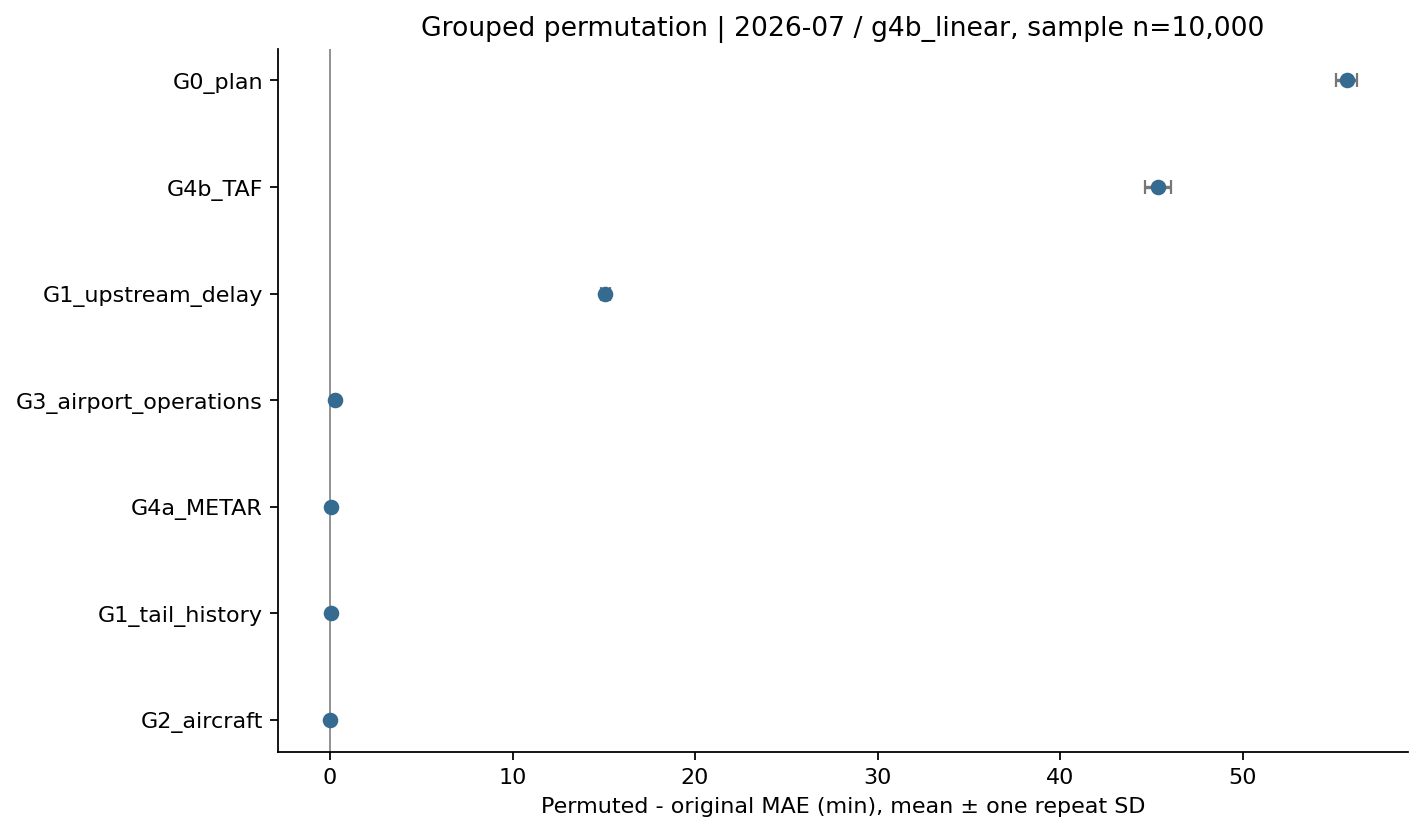

**[permutation_2026-07.png](../experiments/runs/R0027/explanations/R0025/permutation_2026-07.png)**

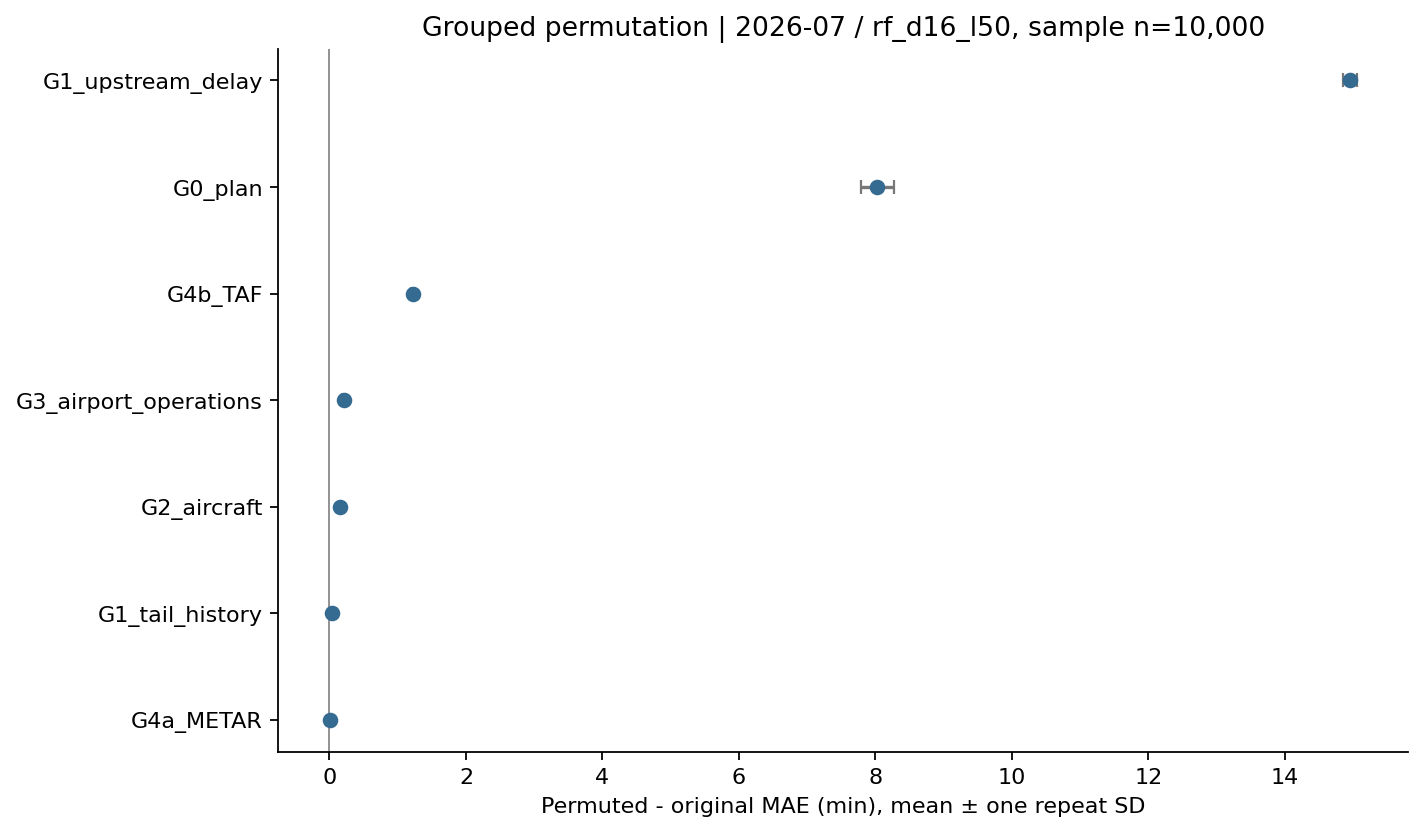

**[pdp_values.csv](../experiments/runs/R0027/explanations/R0017/pdp_values.csv)**：完整表 22 行；当前条件 22 行。

,fold,feature,grid_value,mean_prediction,sample_n
0,2026-07,upstream_arr_delay_minutes,0.000,7.058409,10000
1,2026-07,upstream_arr_delay_minutes,10.600,13.262200,10000
2,2026-07,upstream_arr_delay_minutes,21.200,20.519229,10000
3,2026-07,upstream_arr_delay_minutes,31.800,28.333599,10000
4,2026-07,upstream_arr_delay_minutes,42.400,36.470345,10000
5,2026-07,upstream_arr_delay_minutes,53.000,44.783674,10000
6,2026-07,upstream_arr_delay_minutes,63.600,53.213452,10000
7,2026-07,upstream_arr_delay_minutes,74.200,61.720840,10000
8,2026-07,upstream_arr_delay_minutes,84.800,70.288217,10000
9,2026-07,upstream_arr_delay_minutes,95.400,78.888806,10000


**[pdp_values.csv](../experiments/runs/R0027/explanations/R0025/pdp_values.csv)**：完整表 22 行；当前条件 22 行。

,fold,feature,grid_value,mean_prediction,sample_n
0,2026-07,upstream_arr_delay_minutes,0.000,7.402082,10000
1,2026-07,upstream_arr_delay_minutes,10.600,13.525177,10000
2,2026-07,upstream_arr_delay_minutes,21.200,19.390665,10000
3,2026-07,upstream_arr_delay_minutes,31.800,26.249535,10000
4,2026-07,upstream_arr_delay_minutes,42.400,33.358089,10000
5,2026-07,upstream_arr_delay_minutes,53.000,42.155513,10000
6,2026-07,upstream_arr_delay_minutes,63.600,48.698190,10000
7,2026-07,upstream_arr_delay_minutes,74.200,55.998876,10000
8,2026-07,upstream_arr_delay_minutes,84.800,63.514420,10000
9,2026-07,upstream_arr_delay_minutes,95.400,70.434285,10000


**[pdp_support.csv](../experiments/runs/R0027/explanations/R0017/pdp_support.csv)**：完整表 40 行；当前条件 40 行。

,fold,feature,bin_left,bin_right,n,share_finite
0,2026-07,upstream_arr_delay_minutes,0.00,53.55,8791,0.8791
1,2026-07,upstream_arr_delay_minutes,53.55,107.10,727,0.0727
2,2026-07,upstream_arr_delay_minutes,107.10,160.65,243,0.0243
3,2026-07,upstream_arr_delay_minutes,160.65,214.20,107,0.0107
4,2026-07,upstream_arr_delay_minutes,214.20,267.75,63,0.0063
5,2026-07,upstream_arr_delay_minutes,267.75,321.30,24,0.0024
6,2026-07,upstream_arr_delay_minutes,321.30,374.85,16,0.0016
7,2026-07,upstream_arr_delay_minutes,374.85,428.40,6,0.0006
8,2026-07,upstream_arr_delay_minutes,428.40,481.95,3,0.0003
9,2026-07,upstream_arr_delay_minutes,481.95,535.50,5,0.0005


**[pdp_support.csv](../experiments/runs/R0027/explanations/R0025/pdp_support.csv)**：完整表 40 行；当前条件 40 行。

,fold,feature,bin_left,bin_right,n,share_finite
0,2026-07,upstream_arr_delay_minutes,0.00,53.55,8791,0.8791
1,2026-07,upstream_arr_delay_minutes,53.55,107.10,727,0.0727
2,2026-07,upstream_arr_delay_minutes,107.10,160.65,243,0.0243
3,2026-07,upstream_arr_delay_minutes,160.65,214.20,107,0.0107
4,2026-07,upstream_arr_delay_minutes,214.20,267.75,63,0.0063
5,2026-07,upstream_arr_delay_minutes,267.75,321.30,24,0.0024
6,2026-07,upstream_arr_delay_minutes,321.30,374.85,16,0.0016
7,2026-07,upstream_arr_delay_minutes,374.85,428.40,6,0.0006
8,2026-07,upstream_arr_delay_minutes,428.40,481.95,3,0.0003
9,2026-07,upstream_arr_delay_minutes,481.95,535.50,5,0.0005


**[pdp_2026-07_scheduled_turnaround_minutes.png](../experiments/runs/R0027/explanations/R0017/pdp_2026-07_scheduled_turnaround_minutes.png)**

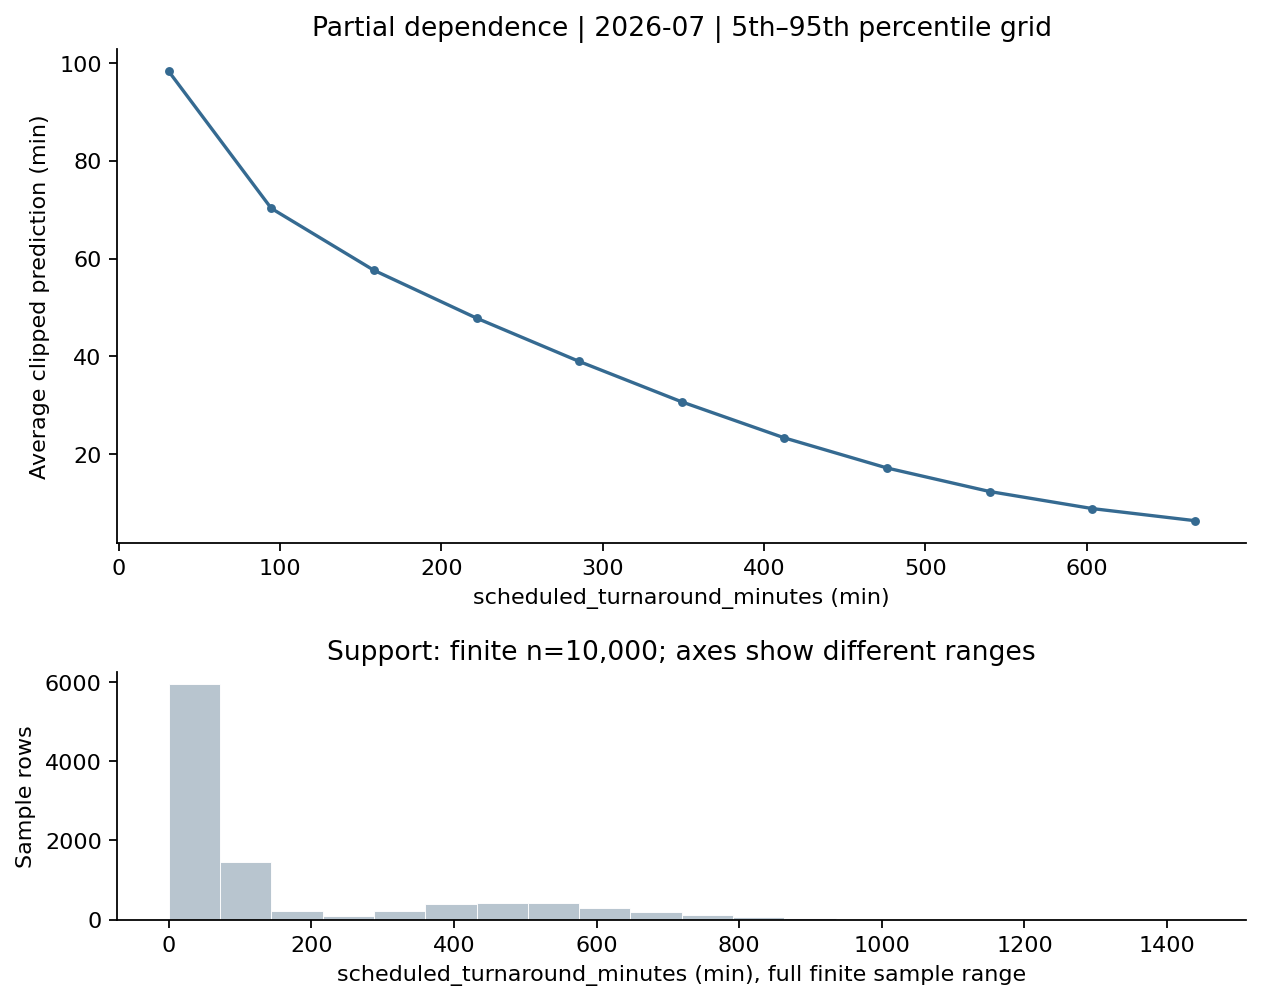

**[pdp_2026-07_upstream_arr_delay_minutes.png](../experiments/runs/R0027/explanations/R0017/pdp_2026-07_upstream_arr_delay_minutes.png)**

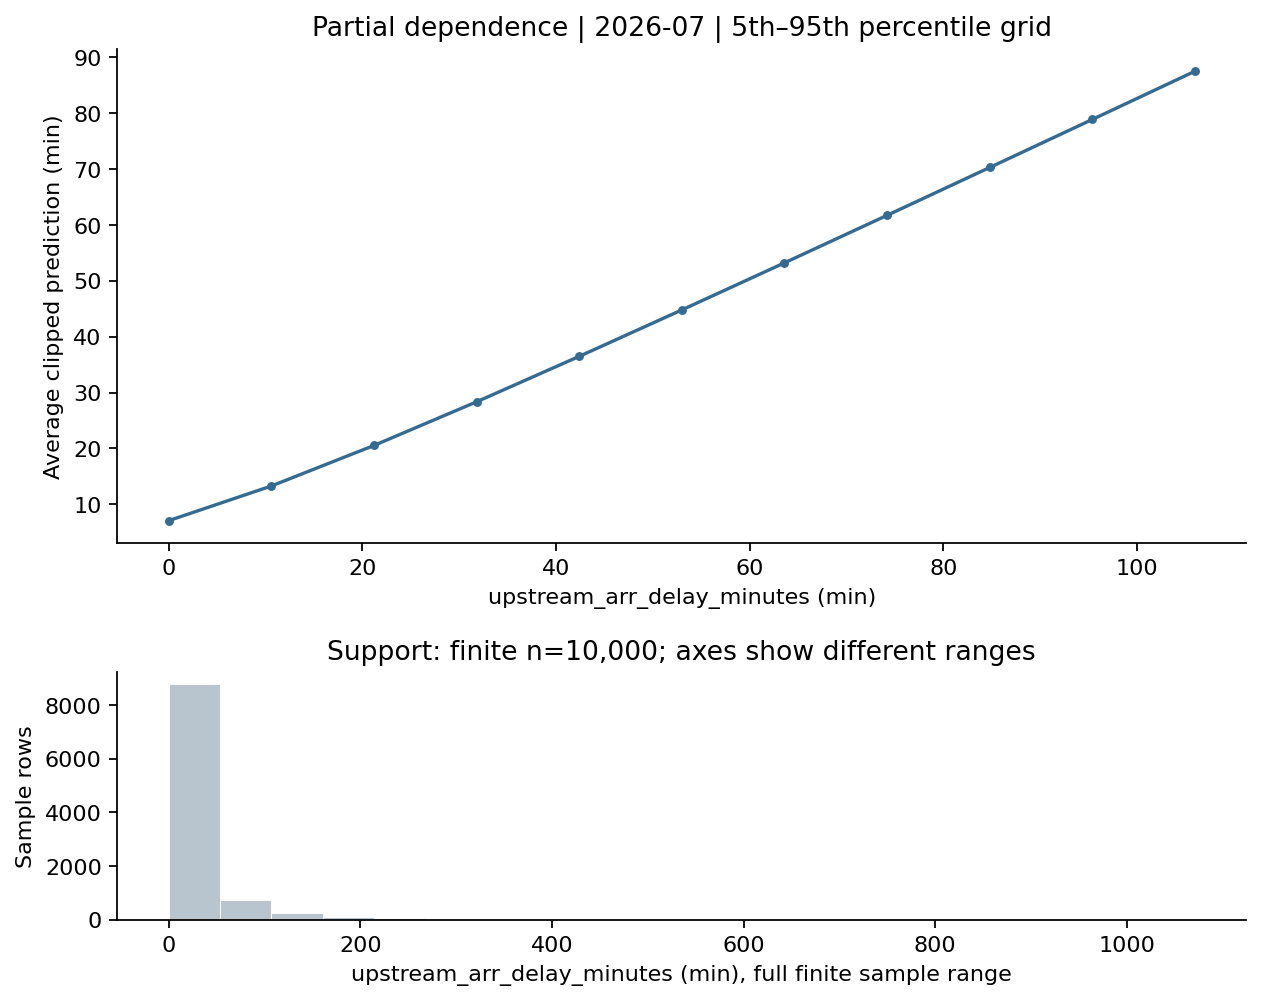

**[pdp_2026-07_scheduled_turnaround_minutes.png](../experiments/runs/R0027/explanations/R0025/pdp_2026-07_scheduled_turnaround_minutes.png)**

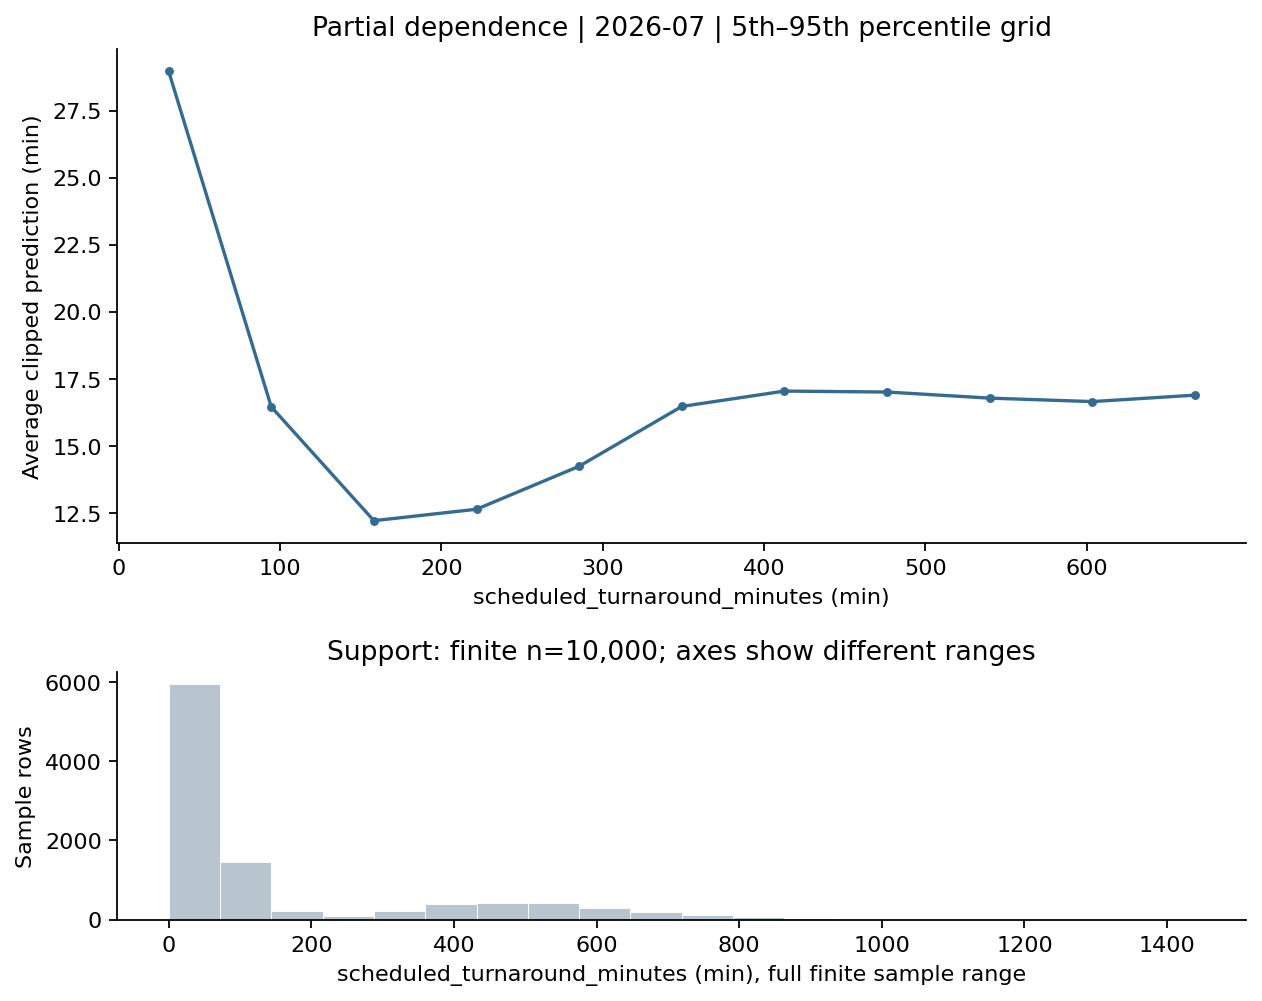

**[pdp_2026-07_upstream_arr_delay_minutes.png](../experiments/runs/R0027/explanations/R0025/pdp_2026-07_upstream_arr_delay_minutes.png)**

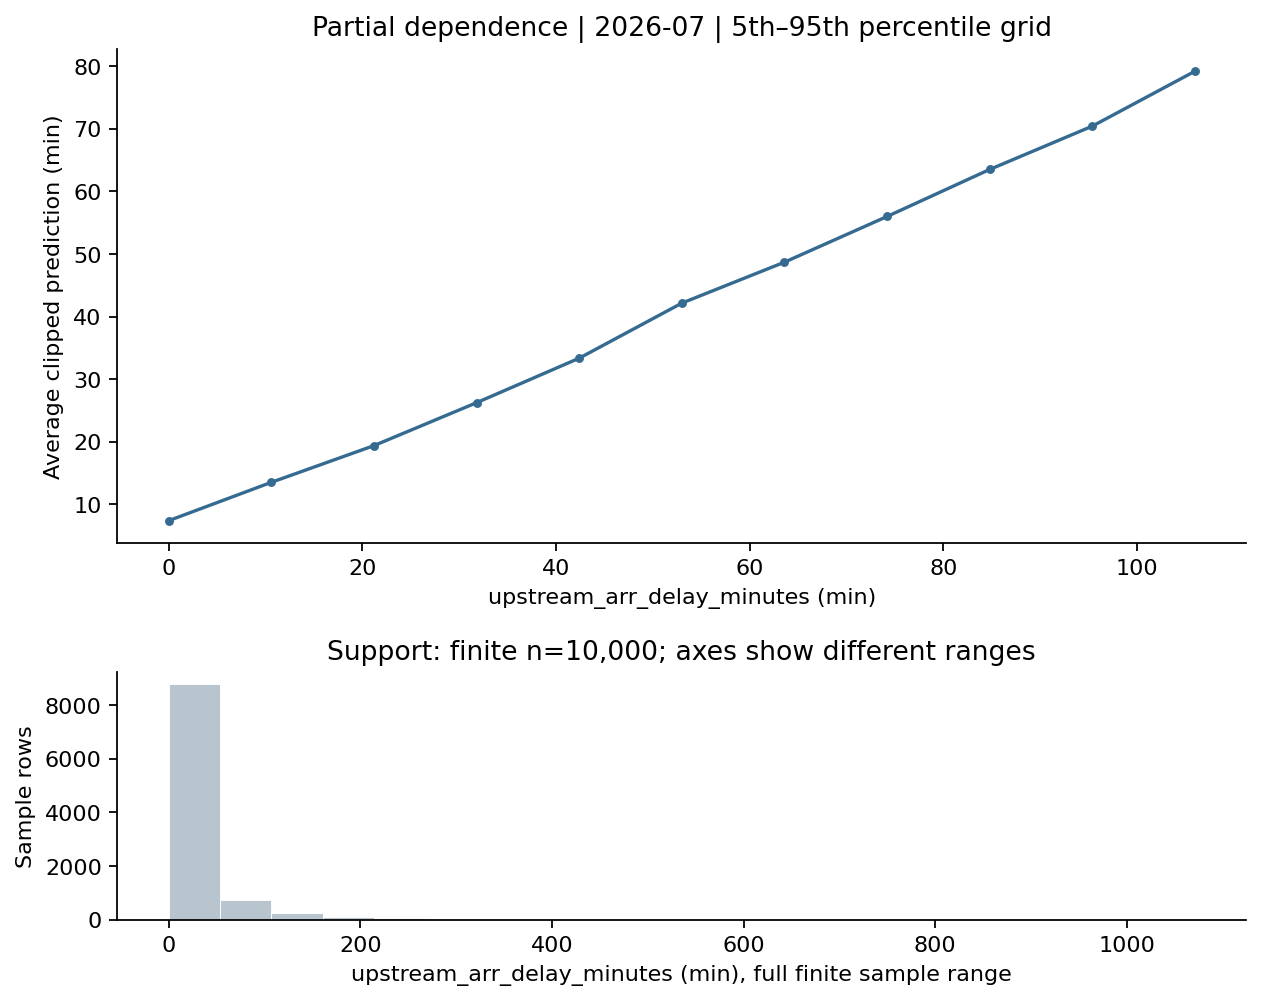

### 系数、截距与树路径：R0017（R0027）

**[explain_coefficients.csv](../experiments/runs/R0027/explanations/R0017/explain_coefficients.csv)**：完整编码系数表可下载。

**numeric__ 数值特征系数：102 行**（预处理后的编码/缩放单位）。

,fold,encoded_feature,coefficient
6154,2026-07,numeric__downstream_distance,-2.676602
6155,2026-07,numeric__downstream_crs_elapsed_time,2.823694
6156,2026-07,numeric__downstream_day_of_week,0.239975
6157,2026-07,numeric__downstream_sched_hour,4.396169
6158,2026-07,numeric__scheduled_turnaround_minutes,-135.209336
6159,2026-07,numeric__upstream_arr_delay_minutes,36.805381
6160,2026-07,numeric__tail_completed_24h_n,-0.655070
6161,2026-07,numeric__tail_completed_24h_arr_delay_mean,0.898631
6162,2026-07,numeric__history_window_incomplete,-0.083924
6163,2026-07,numeric__airport_departures_60m_n,0.920486


**其他编码系数：共 6,154 行，按归档行序仅显示前 12 行**。类别系数依赖参考类别，数值系数使用缩放后输入；不能把绝对系数大小直接当重要性排名，也不能解释为因果效应。

...

,fold,intercept


截距表为空；树模型没有线性截距项，不补造截距。

**[explain_2026-07_tree_paths.txt](../experiments/runs/R0027/explanations/R0025/explain_2026-07_tree_paths.txt)**：完整文本 145 行，下面最多展示前 120 行。DT 为一棵树，RF 为归档的前 3 棵，路径截于深度 3。阈值处于编码/缩放输入空间，不能直接按原始分钟或距离解读。RF 的前 3 棵、深度 3 截断仅为结构示例，不代表整个森林的全局解释。

```text
Tree 0; encoded/scaled inputs; truncated at depth 3
|--- numeric__downstream_sched_hour <= 2.543
|   |--- numeric__upstream_arr_delay_minutes <= 1.092
|   |   |--- numeric__scheduled_turnaround_minutes <= 0.107
|   |   |   |--- numeric__upstream_arr_delay_minutes <= 0.011
|   |   |   |   |--- truncated branch of depth 12
|   |   |   |--- numeric__upstream_arr_delay_minutes >  0.011
|   |   |   |   |--- truncated branch of depth 6
|   |   |--- numeric__scheduled_turnaround_minutes >  0.107
|   |   |   |--- numeric__downstream_sched_hour <= 2.136
|   |   |   |   |--- truncated branch of depth 13
|   |   |   |--- numeric__downstream_sched_hour >  2.136
|   |   |   |   |--- truncated branch of depth 13
|   |--- numeric__upstream_arr_delay_minutes >  1.092
|   |   |--- numeric__taf_lead_minutes <= 0.854
|   |   |   |--- numeric__upstream_arr_delay_minutes <= 3.006
|   |   |   |   |--- truncated branch of depth 13
|   |   |   |--- numeric__upstream_arr_delay_minutes >  3.006
|   |   |   |   |--- truncated branch of depth 11
|   |   |--- numeric__taf_lead_minutes >  0.854
|   |   |   |--- numeric__taf_bulletin_age_minutes <= 2.650
|   |   |   |   |--- truncated branch of depth 13
|   |   |   |--- numeric__taf_bulletin_age_minutes >  2.650
|   |   |   |   |--- truncated branch of depth 13
|--- numeric__downstream_sched_hour >  2.543
|   |--- numeric__upstream_arr_delay_minutes <= 1.317
|   |   |--- numeric__upstream_arr_delay_minutes <= 0.417
|   |   |   |--- numeric__upstream_arr_delay_minutes <= 0.056
|   |   |   |   |--- truncated branch of depth 13
|   |   |   |--- numeric__upstream_arr_delay_minutes >  0.056
|   |   |   |   |--- truncated branch of depth 13
|   |   |--- numeric__upstream_arr_delay_minutes >  0.417
|   |   |   |--- numeric__upstream_arr_delay_minutes <= 0.799
|   |   |   |   |--- truncated branch of depth 13
|   |   |   |--- numeric__upstream_arr_delay_minutes >  0.799
|   |   |   |   |--- truncated branch of depth 13
|   |--- numeric__upstream_arr_delay_minutes >  1.317
|   |   |--- numeric__upstream_arr_delay_minutes <= 2.939
|   |   |   |--- numeric__upstream_arr_delay_minutes <= 1.948
|   |   |   |   |--- truncated branch of depth 13
|   |   |   |--- numeric__upstream_arr_delay_minutes >  1.948
|   |   |   |   |--- truncated branch of depth 13
|   |   |--- numeric__upstream_arr_delay_minutes >  2.939
|   |   |   |--- numeric__taf_lead_minutes <= 1.449
|   |   |   |   |--- truncated branch of depth 13
|   |   |   |--- numeric__taf_lead_minutes >  1.449
|   |   |   |   |--- truncated branch of depth 8


Tree 1; encoded/scaled inputs; truncated at depth 3
|--- numeric__downstream_sched_hour <= 2.543
|   |--- numeric__upstream_arr_delay_minutes <= 1.137
|   |   |--- numeric__upstream_arr_delay_minutes <= 0.079
|   |   |   |--- numeric__scheduled_turnaround_minutes <= 0.107
|   |   |   |   |--- truncated branch of depth 13
|   |   |   |--- numeric__scheduled_turnaround_minutes >  0.107
|   |   |   |   |--- truncated branch of depth 13
|   |   |--- numeric__upstream_arr_delay_minutes >  0.079
|   |   |   |--- numeric__scheduled_turnaround_minutes <= 0.278
|   |   |   |   |--- truncated branch of depth 13
|   |   |   |--- numeric__scheduled_turnaround_minutes >  0.278
|   |   |   |   |--- truncated branch of depth 13
|   |--- numeric__upstream_arr_delay_minutes >  1.137
|   |   |--- numeric__taf_lead_minutes <= 0.842
|   |   |   |--- numeric__taf_lead_minutes <= 0.356
|   |   |   |   |--- truncated branch of depth 13
|   |   |   |--- numeric__taf_lead_minutes >  0.356
|   |   |   |   |--- truncated branch of depth 13
|   |   |--- numeric__taf_lead_minutes >  0.842
|   |   |   |--- numeric__scheduled_turnaround_minutes <= 0.299
|   |   |   |   |--- truncated branch of depth 9
|   |   |   |--- numeric__scheduled_turnaround_minutes >  0.299
|   |   |   |   |--- truncated branch of depth 13
|--- numeric__downstream_sched_hour >  2.543
|   |--- numeric__upstream_arr_delay_minutes <= 1.407
|   |   |--- numeric__upstream_arr_delay_minutes <= 0.417
|   |   |   |--- numeric__airport_departures_60m_delay_mean <= 0.485
|   |   |   |   |--- truncated branch of depth 13
|   |   |   |--- numeric__airport_departures_60m_delay_mean >  0.485
|   |   |   |   |--- truncated branch of depth 13
|   |   |--- numeric__upstream_arr_delay_minutes >  0.417
|   |   |   |--- numeric__taf_lead_minutes <= 0.305
|   |   |   |   |--- truncated branch of depth 13
|   |   |   |--- numeric__taf_lead_minutes >  0.305
|   |   |   |   |--- truncated branch of depth 13
|   |--- numeric__upstream_arr_delay_minutes >  1.407
|   |   |--- numeric__upstream_arr_delay_minutes <= 3.254
|   |   |   |--- numeric__scheduled_turnaround_minutes <= 0.400
|   |   |   |   |--- truncated branch of depth 13
|   |   |   |--- numeric__scheduled_turnaround_minutes >  0.400
|   |   |   |   |--- truncated branch of depth 13
|   |   |--- numeric__upstream_arr_delay_minutes >  3.254
|   |   |   |--- numeric__scheduled_turnaround_minutes <= 0.555
|   |   |   |   |--- truncated branch of depth 13
|   |   |   |--- numeric__scheduled_turnaround_minutes >  0.555
|   |   |   |   |--- truncated branch of depth 13


Tree 2; encoded/scaled inputs; truncated at depth 3
|--- numeric__upstream_arr_delay_minutes <= 1.182
|   |--- numeric__airport_departures_60m_delay_mean <= 0.286
|   |   |--- numeric__upstream_arr_delay_minutes <= 0.304
|   |   |   |--- numeric__scheduled_turnaround_minutes <= 0.107
|   |   |   |   |--- truncated branch of depth 13
|   |   |   |--- numeric__scheduled_turnaround_minutes >  0.107
|   |   |   |   |--- truncated branch of depth 13
|   |   |--- numeric__upstream_arr_delay_minutes >  0.304
|   |   |   |--- numeric__downstream_sched_hour <= 1.932
|   |   |   |   |--- truncated branch of depth 13
|   |   |   |--- numeric__downstream_sched_hour >  1.932
|   |   |   |   |--- truncated branch of depth 13
|   |--- numeric__airport_departures_60m_delay_mean >  0.286
|   |   |--- numeric__upstream_arr_delay_minutes <= 0.327
|   |   |   |--- numeric__taf_lead_minutes <= 0.181
|   |   |   |   |--- truncated branch of depth 11
|   |   |   |--- numeric__taf_lead_minutes >  0.181
|   |   |   |   |--- truncated branch of depth 13
|   |   |--- numeric__upstream_arr_delay_minutes >  0.327
|   |   |   |--- numeric__downstream_sched_hour <= 1.932
|   |   |   |   |--- truncated branch of depth 13
```

展示文本已截断，完整路径见上方归档下载链接。

In [9]:
notice(f"**解释分析归档来源：{OUTPUT_RUN_DIR.name}**")
archive_matches("**/explain_summary.json", base=OUTPUT_RUN_DIR, kind="json")
archive_matches("**/permutation_summary.csv", base=OUTPUT_RUN_DIR, limit=None)
archive_matches("**/permutation_2026-07.png", base=OUTPUT_RUN_DIR, kind="image")
archive_matches("**/pdp_values.csv", base=OUTPUT_RUN_DIR)
archive_matches("**/pdp_support.csv", base=OUTPUT_RUN_DIR)
archive_matches("**/pdp_2026-07_*.png", base=OUTPUT_RUN_DIR, kind="image")
model_structure_explanations(OUTPUT_RUN_DIR)